In [ ]:
### Lymphocytes subpopulation identification in multiorgan

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random


adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")
np.random.seed(0)
random.seed(0)

import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Myeloid_subpop/")


In [2]:
#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")
#adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V6.h5ad")

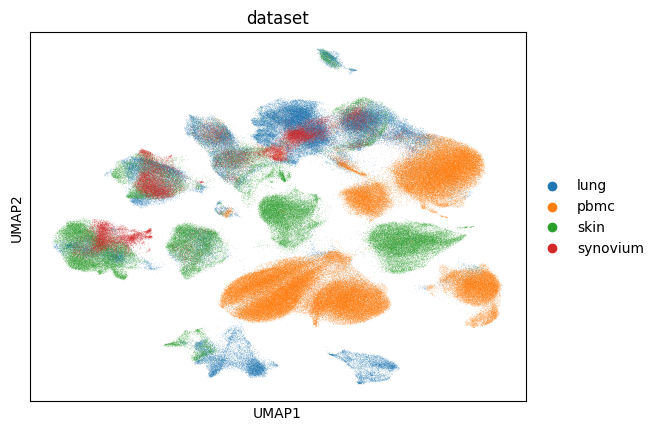

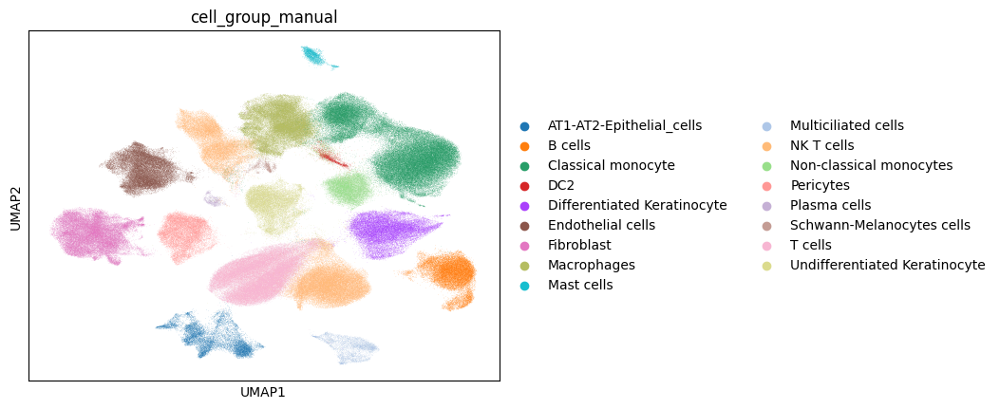

In [3]:
sc.pl.umap(adata_all, color=['dataset'])
sc.pl.umap(adata_all, color=['cell_group_manual'])


In [4]:
adata_all.obs

,sample,Condition,cell_group_manual,leiden_global,Organism,University,Age,Sex,Sequencer,chemistry,...,geo_accession,seurat_clusters,cell_type_celltypist,orig_index,tissue,dataset,apoptosis_score,stress_score,cell_group_lineage,decontX_contamination
GSE128169_SC109SSCUP_SC109SSCUP_1,SC109SSCUP,SSC,Classical monocyte,0,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,-0.140000,6.134343,Myeloid cells,0.012835
GSE128169_SC109SSCUP_SC109SSCUP_2,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.975556,11.032323,Myeloid cells,0.007324
GSE128169_SC109SSCUP_SC109SSCUP_3,SC109SSCUP,SSC,AT1-AT2-Epithelial_cells,6,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,AT2,NaN,lung,lung,-0.128889,0.228283,Epithelial cells,0.005595
GSE128169_SC109SSCUP_SC109SSCUP_4,SC109SSCUP,SSC,Multiciliated cells,7,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Multiciliated,NaN,lung,lung,0.024444,-0.080808,Epithelial cells,0.049414
GSE128169_SC109SSCUP_SC109SSCUP_5,SC109SSCUP,SSC,Macrophages,2,Homo sapiens,University of Pittsburgh,NaN,NaN,Illumina NextSeq 500,10x genomics chemistry: 10X Genomics 3 Prime V...,...,GSM3666106,NaN,Classical monocytes,NaN,lung,lung,0.502222,-0.670707,Myeloid cells,0.082853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE00000_SB-095_SB-095_SB-095_TTTGGTTAGCACTCTA-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,2.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGGTTAGCACTCTA-1-GSE00000,synovium,synovium,0.264444,7.011111,Myeloid cells,0.135197
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTCGTGATT-1-GSE00000,SB-095,SSC,Endothelial cells,11,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,E1: ICAM1+ venous,SB-095_TTTGGTTGTCGTGATT-1-GSE00000,synovium,synovium,-0.682222,0.909091,Endothelial cells,0.030557
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,0.0,M0: MERTK+ TIMD4+ macrophages,SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,synovium,synovium,1.300000,6.116162,Myeloid cells,0.123813
GSE00000_SB-095_SB-095_SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,SB-095,SSC,Macrophages,2,Homo sapiens,University of Zurich,58.0,Male,Illumina NovaSeq 6000,missing,...,nan,1.0,M1: MERTK+ SELENOP+ macrophages,SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,synovium,synovium,0.333333,2.260606,Myeloid cells,0.242589


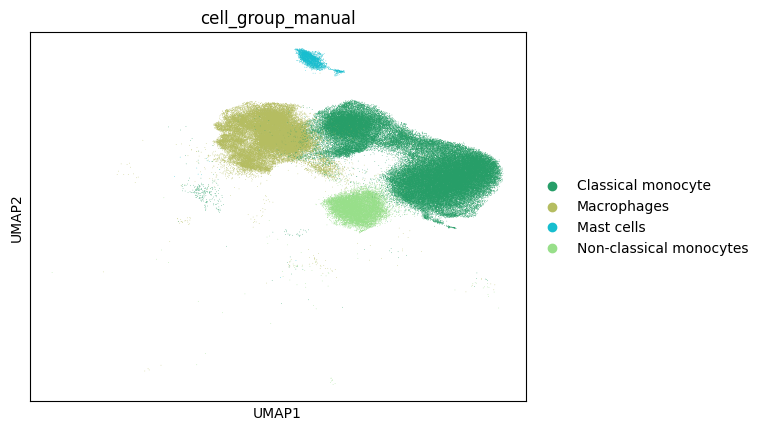

In [5]:
# Define the categories you want to keep
fibroblast_labels = ['Macrophages', 'Mast cells', 'Classical monocyte', 'Non-classical monocytes']

# Subset the AnnData object
#adata_query = adata_query[adata_query.obs['leiden_r0.1'].isin(fibroblast_labels)].copy()
adata_all = adata_all[adata_all.obs['cell_group_manual'].isin(fibroblast_labels)].copy()
sc.pl.umap(adata_all, color=['cell_group_manual'])

NORMALIZATION COMPARABILITY CHECK

[1/6] Loading dataset...
✓ Loaded: 131,867 cells × 22,446 genes
  Batches: ['E-GEAD-872', 'GSE00000', 'GSE128169', 'GSE138669', 'GSE209635', 'GSE212109']

[3/6] Comparing value distributions across batches...
  (Using ALL cells - no subsampling)
  Processing E-GEAD-872: 60,753 cells...
  Processing GSE00000: 11,994 cells...
  Processing GSE128169: 33,466 cells...
  Processing GSE138669: 4,016 cells...
  Processing GSE209635: 2,109 cells...
  Processing GSE212109: 19,529 cells...
     (Distributions should look similar if normalization worked)


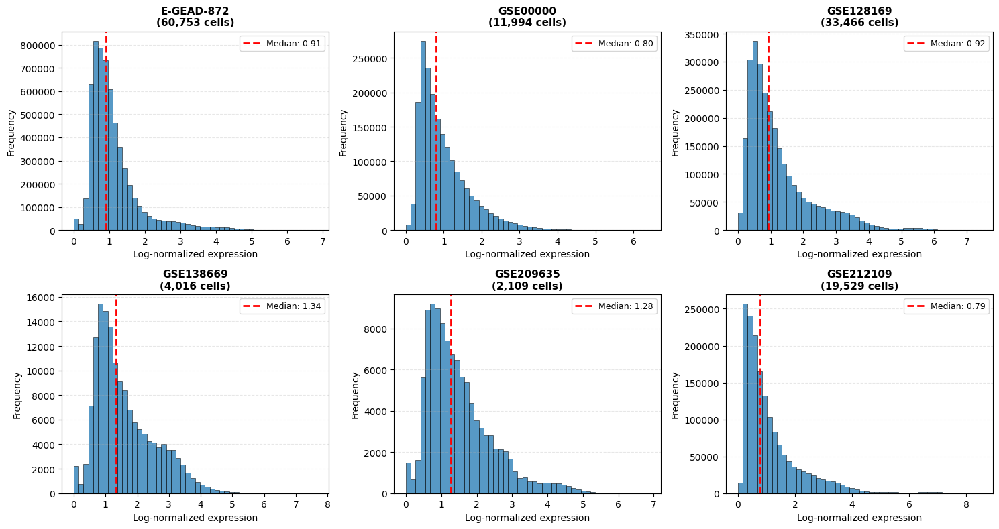

In [6]:

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations


# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════
BATCH_KEY = "batch"
CELLTYPE_KEY = "cell_group"

print("="*70)
print("NORMALIZATION COMPARABILITY CHECK")
print("="*70)

# ═══════════════════════════════════════════════════════════
# 1. CARICA DATI
# ═══════════════════════════════════════════════════════════

print("\n[1/6] Loading dataset...")
# Assume adata_all already loaded
print(f"✓ Loaded: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

batches = sorted(adata_all.obs[BATCH_KEY].unique())
print(f"  Batches: {batches}")



print("\n[3/6] Comparing value distributions across batches...")
print("  (Using ALL cells - no subsampling)")

# Calculate grid layout
n_batches = len(batches)
n_cols = min(3, n_batches)
n_rows = int(np.ceil(n_batches / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
if n_batches == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, batch in enumerate(batches):
    mask = adata_all.obs[BATCH_KEY] == batch
    batch_data = adata_all[mask]
    
    print(f"  Processing {batch}: {batch_data.n_obs:,} cells...")
    
    # Extract ALL values (no subsampling)
    if hasattr(batch_data.X, 'toarray'):
        # Sparse matrix - sample genes to avoid memory issues
        # Take all cells but sample 1000 random genes
        n_genes_sample = min(1000, batch_data.n_vars)
        gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
        values = batch_data.X[:, gene_idx].toarray().flatten()
    else:
        # Dense matrix - can handle all
        if batch_data.n_obs * batch_data.n_vars > 10_000_000:
            # Too big - sample
            n_genes_sample = min(1000, batch_data.n_vars)
            gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
            values = batch_data.X[:, gene_idx].flatten()
        else:
            values = np.array(batch_data.X).flatten()
    
    # Remove zeros for clearer visualization
    values_nonzero = values[values > 0]
    
    # Plot histogram
    axes[idx].hist(values_nonzero, bins=50, alpha=0.75, edgecolor='black', linewidth=0.5)
    axes[idx].axvline(np.median(values_nonzero), color='red', linestyle='--', 
                      linewidth=2, label=f'Median: {np.median(values_nonzero):.2f}')
    
    axes[idx].set_title(f"{batch}\n({batch_data.n_obs:,} cells)", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Log-normalized expression", fontsize=10)
    axes[idx].set_ylabel("Frequency", fontsize=10)
    axes[idx].legend(fontsize=9)
    axes[idx].grid(axis='y', alpha=0.3, linestyle='--')

# Hide empty subplots
for idx in range(n_batches, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
print("     (Distributions should look similar if normalization worked)")
#plt.close()

In [7]:
import pandas as pd

obs = adata_all.obs

# Number of unique patients per batch
patients_per_batch = obs.groupby("batch")["sample"].nunique()

# Number of unique patients per batch *and condition*
patients_condition = (
    obs.groupby(["batch", "Condition"])["sample"]
       .nunique()
       .unstack(fill_value=0)
)
# Rinomina le colonne per chiarezza
patients_condition.columns = [f"n_patients_{col}" for col in patients_condition.columns]

# Number of cells per batch
cells_per_batch = obs["batch"].value_counts().sort_index()

# Tissues represented in each batch
tissues_per_batch = obs.groupby("batch")["tissue"].unique()

# List of patient IDs per batch
patients_list = obs.groupby("batch")["sample"].unique()

# Combine everything into a single summary table
summary = pd.DataFrame({
    "n_patients_total": patients_per_batch,
    "n_cells": cells_per_batch,
    "tissues": tissues_per_batch,
    "patient_ids": patients_list
})

# Aggiungi per-condition patient counts
summary = pd.concat([summary, patients_condition], axis=1)

print(summary)

            n_patients_total  n_cells  \
batch                                   
E-GEAD-872                27    60753   
GSE00000                   9    11994   
GSE128169                 13    33466   
GSE138669                 22     4016   
GSE209635                 15     2109   
GSE212109                  9    19529   

                                                      tissues  \
batch                                                           
E-GEAD-872  ['pbmc']
Categories (4, object): ['lung', 'pbm...   
GSE00000    ['synovium']
Categories (4, object): ['lung', ...   
GSE128169   ['lung']
Categories (4, object): ['lung', 'pbm...   
GSE138669   ['skin']
Categories (4, object): ['lung', 'pbm...   
GSE209635   ['skin']
Categories (4, object): ['lung', 'pbm...   
GSE212109   ['lung']
Categories (4, object): ['lung', 'pbm...   

                                                  patient_ids  \
batch                                                           
E-GEAD-872  ['HD5', 

/tmp/ipykernel_1358845/196286925.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patients_per_batch = obs.groupby("batch")["sample"].nunique()
/tmp/ipykernel_1358845/196286925.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs.groupby(["batch", "Condition"])["sample"]
/tmp/ipykernel_1358845/196286925.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tissues_per_batch = obs.groupby("batch")["tissue"].unique()

In [8]:
adata_all

AnnData object with n_obs × n_vars = 131867 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors', 'dataset_colors', 'excluded_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'

In [9]:
adata_all.obs["cell_group_manual"].unique()

['Classical monocyte', 'Macrophages', 'Mast cells', 'Non-classical monocytes']
Categories (4, object): ['Classical monocyte', 'Macrophages', 'Mast cells', 'Non-classical monocytes']

In [10]:
# --- 4) Highly Variable Genes ---
sc.pp.highly_variable_genes(adata_all, flavor="seurat", n_top_genes=1000)

# DO NOT subset the object
# adata_all = adata_all[:, adata_all.var["highly_variable"]].copy()   

# --- 5) PCA using only HVGs ---
sc.tl.pca(adata_all, use_highly_variable=True, svd_solver="arpack")

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


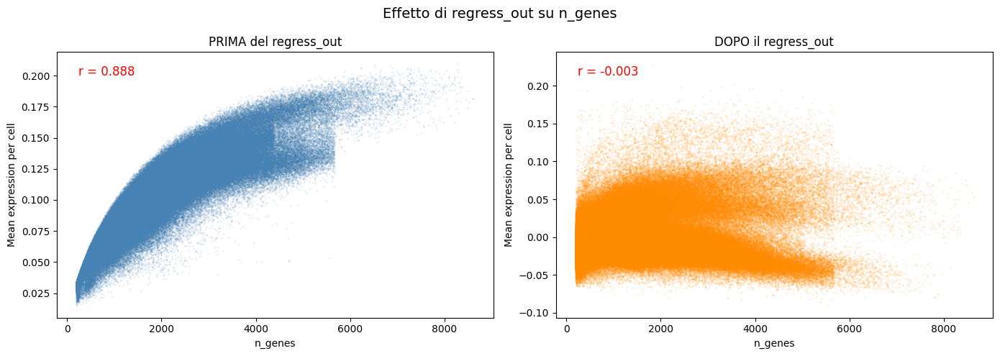

n_genes — Correlazione PRIMA: 0.8879 | DOPO: -0.0034


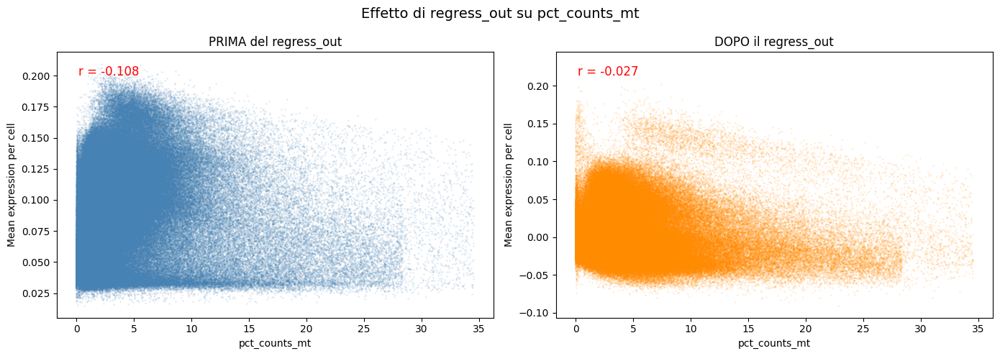

pct_counts_mt — Correlazione PRIMA: -0.1083 | DOPO: -0.0265


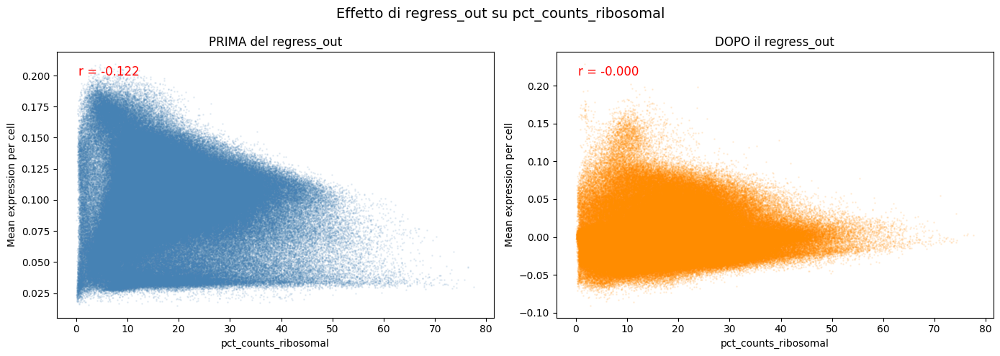

pct_counts_ribosomal — Correlazione PRIMA: -0.1217 | DOPO: -0.0000

Correlazione n_genes vs PC1: -0.0756 | PC2: -0.0229

Correlazione pct_counts_mt vs PC1: -0.0514 | PC2: -0.0106

Correlazione pct_counts_ribosomal vs PC1: 0.0000 | PC2: 0.0000


2026-09-28 14:17:33,859 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-09-28 14:18:50,631 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-28 14:19:01,436 - harmonypy - INFO - Iteration 1 of 25


KeyboardInterrupt: 

In [4]:
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import numpy as np

# ── SUBSET HVG ───────────────────────────────────────────────────────────────
adata_all_hvg = adata_all[:, adata_all.var["highly_variable"]].copy()

# ── REGRESS OUT ───────────────────────────────────────────────────────────────
sc.pp.regress_out(adata_all_hvg, ["n_genes"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_mt"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_ribosomal"])

# ── VALORI PRE/POST ───────────────────────────────────────────────────────────
mean_expr_before = np.array(adata_all.X.mean(axis=1)).flatten()
mean_expr_after  = np.array(adata_all_hvg.X.mean(axis=1)).flatten()

n_genes          = adata_all_hvg.obs["n_genes"].values
pct_counts_mt    = adata_all_hvg.obs["pct_counts_mt"].values
pct_counts_rb    = adata_all_hvg.obs["pct_counts_ribosomal"].values

# ── FUNZIONE HELPER ───────────────────────────────────────────────────────────
def plot_regress_validation(var_values, var_name, before, after):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # nuova figura ogni volta

    corr_before = np.corrcoef(var_values, before)[0, 1]
    corr_after  = np.corrcoef(var_values, after)[0, 1]

    axes[0].scatter(var_values, before, alpha=0.1, s=1, color="steelblue")
    axes[0].set_xlabel(var_name)
    axes[0].set_ylabel("Mean expression per cell")
    axes[0].set_title("PRIMA del regress_out")
    axes[0].text(0.05, 0.95, f"r = {corr_before:.3f}", transform=axes[0].transAxes,
                 fontsize=12, color="red", va="top")

    axes[1].scatter(var_values, after, alpha=0.1, s=1, color="darkorange")
    axes[1].set_xlabel(var_name)
    axes[1].set_ylabel("Mean expression per cell")
    axes[1].set_title("DOPO il regress_out")
    axes[1].text(0.05, 0.95, f"r = {corr_after:.3f}", transform=axes[1].transAxes,
                 fontsize=12, color="red", va="top")

    plt.suptitle(f"Effetto di regress_out su {var_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print(f"{var_name} — Correlazione PRIMA: {corr_before:.4f} | DOPO: {corr_after:.4f}")

# ── PLOT ──────────────────────────────────────────────────────────────────────
plot_regress_validation(n_genes,       "n_genes",            mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_mt, "pct_counts_mt",      mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_rb, "pct_counts_ribosomal", mean_expr_before, mean_expr_after)

# ── PCA ───────────────────────────────────────────────────────────────────────
sc.tl.pca(adata_all_hvg, svd_solver="arpack")

for var_values, var_name in [
    (n_genes,       "n_genes"),
    (pct_counts_mt, "pct_counts_mt"),
    (pct_counts_rb, "pct_counts_ribosomal"),
]:
    corr_pc1 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 0])[0, 1]
    corr_pc2 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 1])[0, 1]
    print(f"\nCorrelazione {var_name} vs PC1: {corr_pc1:.4f} | PC2: {corr_pc2:.4f}")

# ── HARMONY + UMAP ───────────────────────────────────────────────────────────
sce.pp.harmony_integrate(adata_all_hvg, "sample", max_iter_harmony=25)
sc.pp.neighbors(adata_all_hvg, use_rep="X_pca_harmony", n_neighbors=15)
sc.tl.umap(adata_all_hvg)

In [ ]:
# --- 7) Recompute neighbors + UMAP using Harmony embedding ---
#sc.pp.neighbors(adata_all, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=50)
#sc.tl.umap(adata_all)
sc.pl.umap(adata_all_hvg)
# --- 8) Save the integrated object ---
#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Integrated_SSC_Harmony.h5ad")

print("✅ Harmony integration completed and UMAP computed!")

In [ ]:
sc.tl.leiden(
    adata_all_hvg,
    resolution=0.8,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="Myeloid_subpopulation" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

In [66]:
print(adata_all.obs.columns.tolist())
print(adata_all.obs["Myeloid_subpopulation"].value_counts())

['sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination', 'Myeloid_subpopulation', 'IFN_ALPHA_genes', 'IFN_GAMMA_genes', 'COMP_CLASS_genes', 'COMP_ALT_genes', 'COMP_ALL_genes', 'ambient_score']
Myeloid_subpopulation
3     31649
4     21904
8     16717
2     14261
1     13720
0     11070
5     10153
6      6242
11     2376
12     1411
10     1134
7       841
9       389
Name: count, dtype: int64


In [59]:
# Trasferisci l'UMAP da fib_hvg a fib
adata_all.obsm["X_umap"] = adata_all_hvg.obsm["X_umap"]
adata_all.obsm["X_pca_harmony"] = adata_all_hvg.obsm["X_pca_harmony"]

['0', '4', '1', '6', '11', ..., '10', '2', '9', '7', '12']
Length: 13
Categories (13, object): ['0', '1', '2', '3', ..., '9', '10', '11', '12']


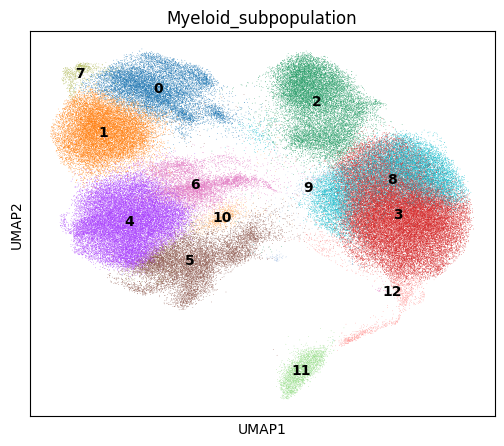

In [80]:
print(adata_all_hvg.obs['Myeloid_subpopulation'].unique())
sc.pl.umap(adata_all_hvg, color='Myeloid_subpopulation', legend_loc='on data')
adata_all.obs["Myeloid_subpopulation"] = adata_all_hvg.obs["Myeloid_subpopulation"]

In [87]:
%matplotlib inline

In [81]:
# Salva l'assegnazione cluster con l'indice (cell barcode) per riuso futuro
# senza dover rifare l'intero pipeline di integrazione/clustering
Myeloid_subpop_export = adata_all.obs[['Myeloid_subpopulation']].copy()
Myeloid_subpop_export.index.name = 'cell_id'
Myeloid_subpop_export.to_csv('Myeloid_subpopulation_assignment.csv')

In [82]:
adata_all.obs[['Myeloid_subpopulation']]

,Myeloid_subpopulation
GSE128169_SC109SSCUP_SC109SSCUP_1,0
GSE128169_SC109SSCUP_SC109SSCUP_2,4
GSE128169_SC109SSCUP_SC109SSCUP_5,4
GSE128169_SC109SSCUP_SC109SSCUP_6,4
GSE128169_SC109SSCUP_SC109SSCUP_9,1
...,...
GSE00000_SB-095_SB-095_SB-095_TTTGGAGAGGAAAGGT-1-GSE00000,5
GSE00000_SB-095_SB-095_SB-095_TTTGGTTAGCACTCTA-1-GSE00000,4
GSE00000_SB-095_SB-095_SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,4
GSE00000_SB-095_SB-095_SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,1


In [9]:

CLUSTER_MAP = {
    "0":  "Mixed_ClassMono_DC2",
    "1":  "Pan_DifferentiatingMono_TREM2",
    "2":  "PBMC_NonclassMono_FCGR3A",
    "3":  "PBMC_ClassMono_CD14",
    "4":  "Pan_ResidentMac_TREM2",
    "5":  "Low_Quality",
    "6":  "Lung_ResidentMac_TREM2",
    "7":  "Low_Quality",
    "8":  "PBMC_ClassMono_CD14",
    "9":  "Synov_DifferentiatingMono",
    "10": "Pan_ResidentMac_FOLR2_LYVE1",
    "11": "Pan_MastCells",
    "12": "Mixed_MastMac",
}

adata_all.obs["Myeloid_subpopulation"] = (
    adata_all.obs["Myeloid_subpopulation"]
    .astype(str)          # ← forza stringa anche sul lato obs, per sicurezza
    .map(CLUSTER_MAP)
    .fillna("Unknown")
    .astype("category")
)

print(adata_all.obs["Myeloid_subpopulation"].value_counts())

Myeloid_subpopulation
PBMC_ClassMono_CD14              48366
Pan_ResidentMac_TREM2            21904
PBMC_NonclassMono_FCGR3A         14261
Pan_DifferentiatingMono_TREM2    13720
Mixed_ClassMono_DC2              11070
Low_Quality                      10994
Lung_ResidentMac_TREM2            6242
Pan_MastCells                     2376
Mixed_MastMac                     1411
Pan_ResidentMac_FOLR2_LYVE1       1134
Synov_DifferentiatingMono          389
Name: count, dtype: int64


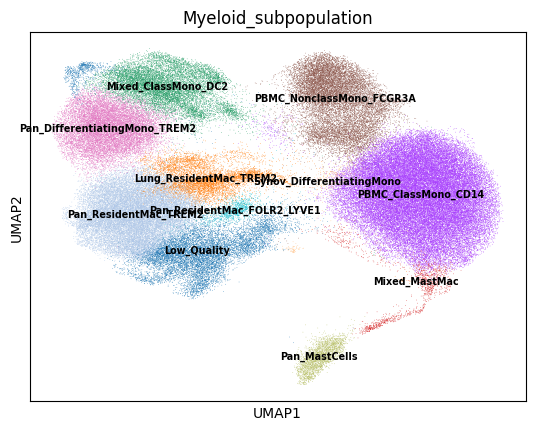

In [12]:
sc.pl.umap(adata_all, color='Myeloid_subpopulation', legend_loc='on data', legend_fontsize="x-small")

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random

np.random.seed(0)
random.seed(0)




#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Monocytes.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Monocytes.h5ad")

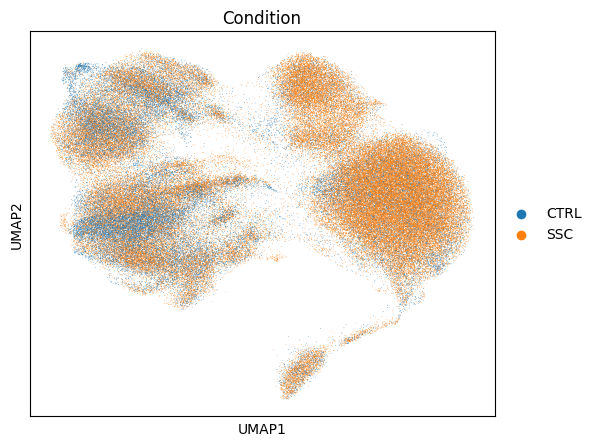

In [85]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 5)  # larghezza, altezza in pollici
sc.pl.umap(adata_all, color=['Condition'])

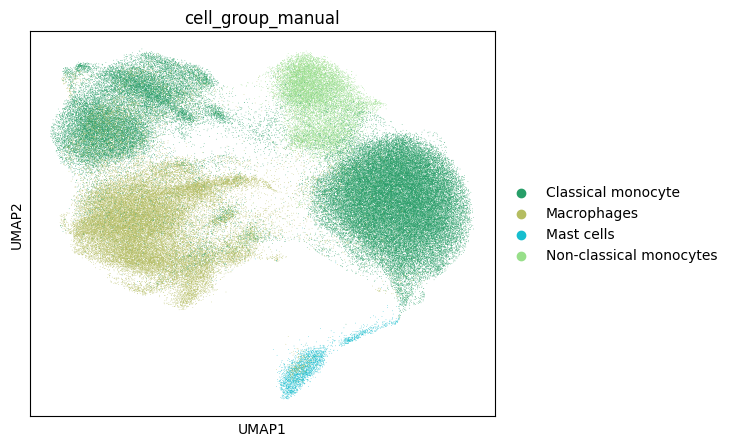

In [86]:
sc.pl.umap(adata_all, color=['cell_group_manual'])

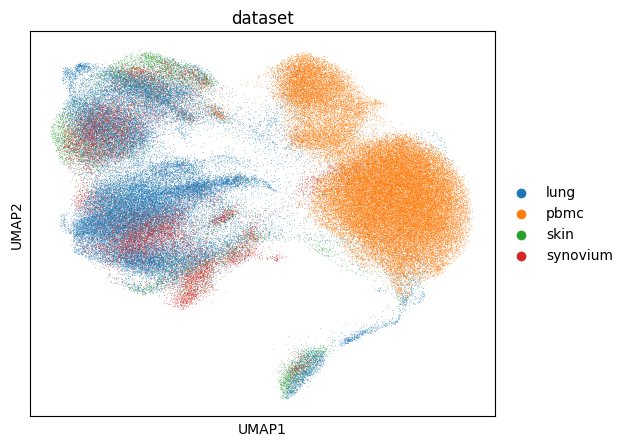

In [87]:
sc.pl.umap(adata_all, color=['dataset'])

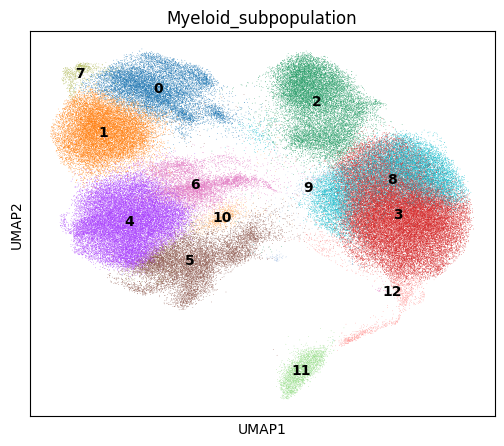

In [88]:
sc.pl.umap(adata_all, color='Myeloid_subpopulation', legend_loc='on data')

In [89]:
adata_all

AnnData object with n_obs × n_vars = 131867 × 22446
    obs: 'sample', 'Condition', 'cell_group_manual', 'leiden_global', 'Organism', 'University', 'Age', 'Sex', 'Sequencer', 'chemistry', 'treatment', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'autoantibodies', 'Cell_Phase', 'n_genes', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'seurat_clusters', 'cell_type_celltypist', 'orig_index', 'tissue', 'dataset', 'apoptosis_score', 'stress_score', 'cell_group_lineage', 'decontX_contamination', 'Myeloid_subpopulation', 'IFN_ALPHA_genes', 'IFN_GAMMA_genes', 'COMP_CLASS_genes', 'COMP_ALT_genes', 'COMP_ALL_genes', 'ambient_score', 'Myeloid_annotation'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'Condition_colors', 'cell_group_colors', 'cell_group_leiden_colors', 'cell_group_manual_colors', 'cell_type_colors',

/tmp/ipykernel_1358845/601108382.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['sample', 'Myeloid_subpopulation']).size().reset_index(name='count')


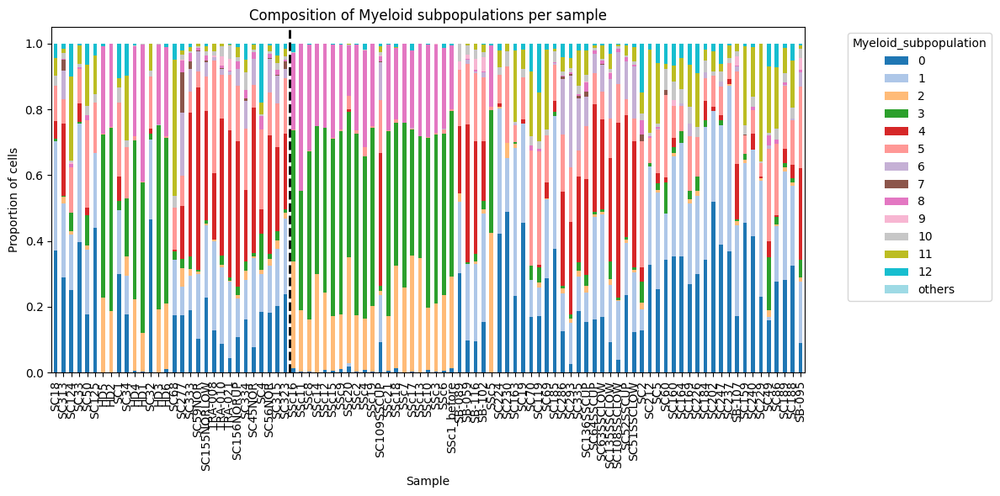

In [90]:
import pandas as pd
import matplotlib.pyplot as plt

df = adata_all.obs[['sample', 'Myeloid_subpopulation', 'Condition']].copy()
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].astype('category')
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].cat.add_categories('others')
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].fillna('others')

counts = df.groupby(['sample', 'Myeloid_subpopulation']).size().reset_index(name='count')
counts_pivot = counts.pivot(index='sample', columns='Myeloid_subpopulation', values='count').fillna(0)
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)

# --- Unica aggiunta: ordina per condizione ---
sample_condition = df[['sample', 'Condition']].drop_duplicates().set_index('sample')
counts_prop = counts_prop.loc[sample_condition.sort_values('Condition').index]

# Plot
ax = counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab20'
)

# --- Linea verticale per separare le condizioni ---
condition_sizes = sample_condition.sort_values('Condition')['Condition'].value_counts(sort=False)
split = condition_sizes.iloc[0]  # numero di campioni della prima condizione
ax.axvline(x=split - 0.5, color='black', linewidth=2, linestyle='--')

plt.ylabel('Proportion of cells')
plt.xlabel('Sample')
plt.title('Composition of Myeloid subpopulations per sample')
plt.legend(title='Myeloid_subpopulation', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2199619/4192556283.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_2199619/4192556283.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
/tmp/ipykernel_2199619/4192556283.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  count

Saved: Figures/Myeloid_composition_by_organ.svg


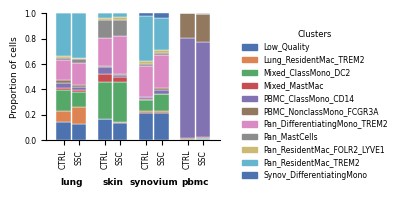

In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()
    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)
    color_map = {c: palette[i % len(palette)] for i, c in enumerate(categories)}

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col]).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, categories, title="Clusters", fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="Myeloid_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/Myeloid_composition_by_organ.svg"
)
plt.show()

/tmp/ipykernel_2199619/795048119.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['Condition', 'Myeloid_subpopulation']).size().reset_index(name='count')


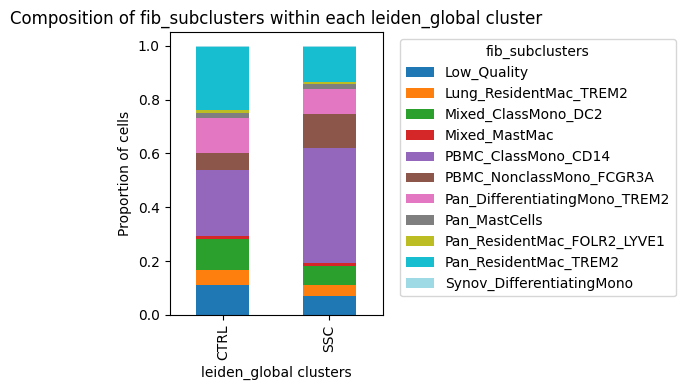

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['Condition', 'Myeloid_subpopulation']].copy()
# Ensure 'fib_subclusters' is categorical
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].astype('category')
# Add 'others' to the categories
#df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].cat.add_categories('others')
# Fill missing values with 'others'
#df['fibroblast_subpopulation'] = df['fibroblast_subpopulation'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['Condition', 'Myeloid_subpopulation']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='Condition', columns='Myeloid_subpopulation', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,4),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2199619/2439629840.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['tissue', 'Myeloid_subpopulation']).size().reset_index(name='count')


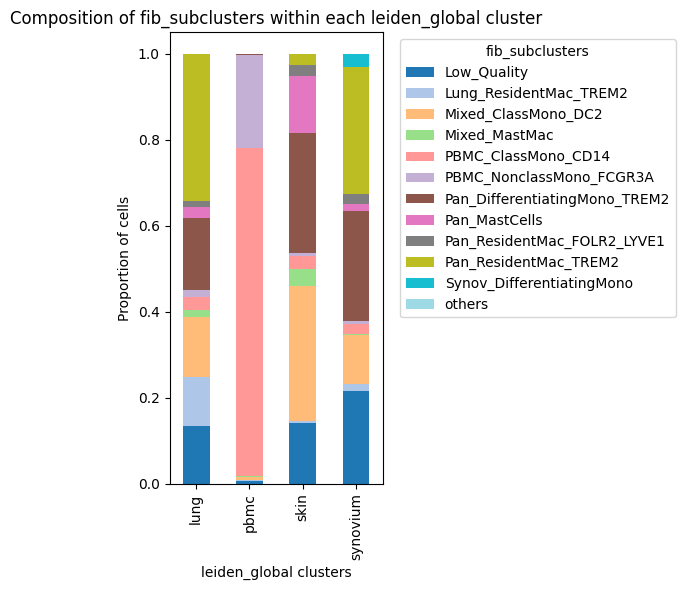

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['tissue', 'Myeloid_subpopulation']].copy()
# Ensure 'fib_subclusters' is categorical
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].astype('category')
# Add 'others' to the categories
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].cat.add_categories('others')
# Fill missing values with 'others'
df['Myeloid_subpopulation'] = df['Myeloid_subpopulation'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['tissue', 'Myeloid_subpopulation']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='tissue', columns='Myeloid_subpopulation', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2199619/2464669885.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['Myeloid_subpopulation', 'tissue']).size().reset_index(name='count')


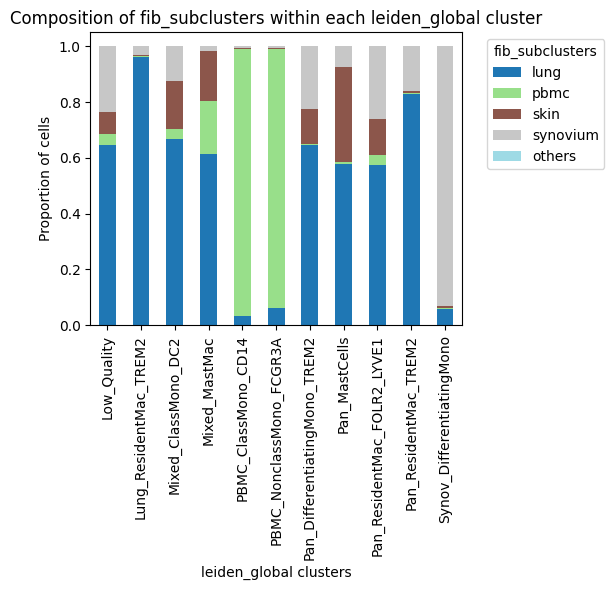

In [20]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Copy relevant columns
df = adata_all.obs[['Myeloid_subpopulation', 'tissue']].copy()
# Ensure 'fib_subclusters' is categorical
df['tissue'] = df['tissue'].astype('category')
# Add 'others' to the categories
df['tissue'] = df['tissue'].cat.add_categories('others')
# Fill missing values with 'others'
df['tissue'] = df['tissue'].fillna('others')
# Compute counts per cluster
counts = df.groupby(['Myeloid_subpopulation', 'tissue']).size().reset_index(name='count')
# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='Myeloid_subpopulation', columns='tissue', values='count').fillna(0)
# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)
# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(6,6),
    colormap='tab20'
)
plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

Ambient genes trovati: 13/13


<Axes: title={'center': 'Ambient RNA score'}, xlabel='UMAP1', ylabel='UMAP2'>

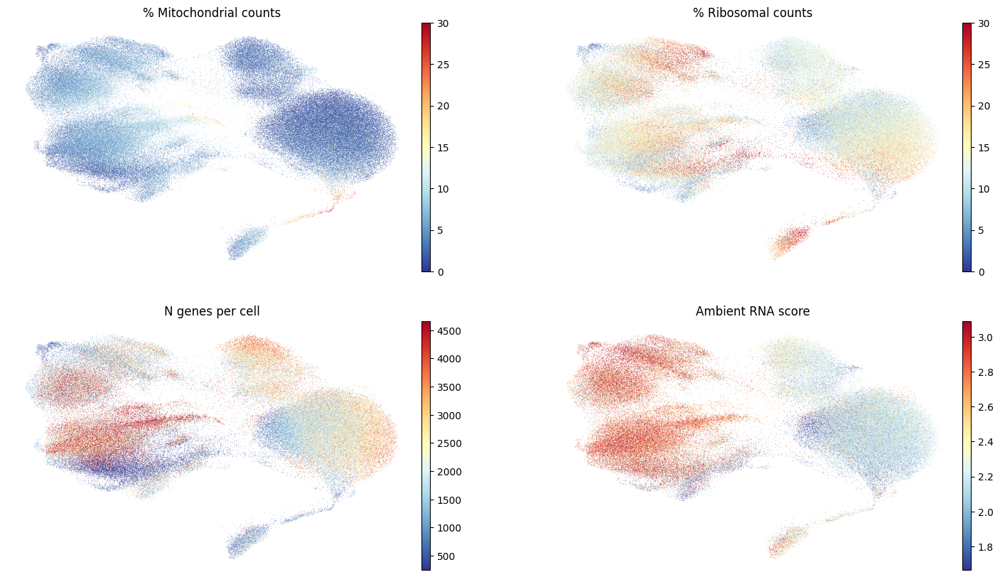

In [21]:
import matplotlib.pyplot as plt
import numpy as np


# ── GENE SIGNATURES ──────────────────────────────────────────────────────────
# Ambient RNA / housekeeping genes — highly expressed in empty droplets
ambient_genes = [
    "MALAT1", "NEAT1",                          # lncRNA ubiqui nell'ambient RNA
    "ACTB", "ACTG1",                            # actina
    "GAPDH", "LDHA",                            # glicolisi
    "B2M",                                      # MHC I ubiquo
    "FTL", "FTH1",                              # ferritina — molto abbondante
    "TMSB4X", "TMSB10",                         # thymosine — ambient marker
    "S100A4", "VIM",                            # proteine strutturali ubique
]

ambient_present = [g for g in ambient_genes if g in adata_all.var_names]
missing = [g for g in ambient_genes if g not in adata_all.var_names]
print(f"Ambient genes trovati: {len(ambient_present)}/{len(ambient_genes)}")
if missing:
    print(f"Mancanti: {missing}")

sc.tl.score_genes(adata_all, ambient_present, score_name="ambient_score")


fig, axes = plt.subplots(2, 2, figsize=(18, 10))


# ── PLOT 2: UMAP % mitocondriale ─────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_mt",
    ax=axes[0, 0],
    show=False,
    frameon=False,
    title="% Mitochondrial counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── PLOT 3: UMAP % ribosomiale ───────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_ribosomal",
    ax=axes[0, 1],
    show=False,
    frameon=False,
    title="% Ribosomal counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── UMAP: n_genes ─────────────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="n_genes",
           ax=axes[1, 0], show=False, frameon=False,
           title="N genes per cell",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["n_genes"].quantile(0.05),
           vmax=adata_all.obs["n_genes"].quantile(0.95))

# ── UMAP: ambient score ───────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="ambient_score",
           ax=axes[1, 1], show=False, frameon=False,
           title="Ambient RNA score",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["ambient_score"].quantile(0.05),
           vmax=adata_all.obs["ambient_score"].quantile(0.95))


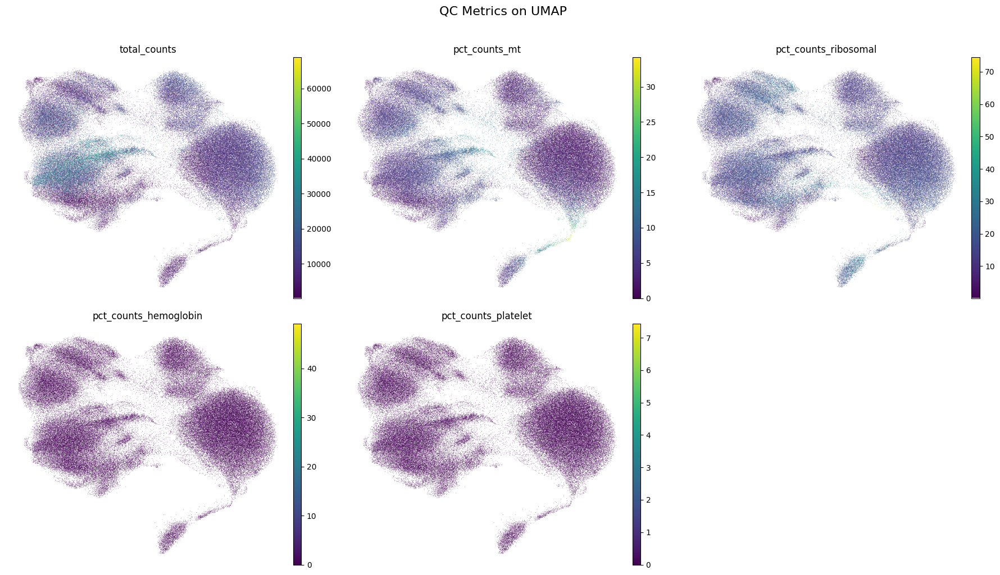

In [96]:
import matplotlib.pyplot as plt
import scanpy as sc

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

variables = ["total_counts", "pct_counts_mt", "pct_counts_ribosomal", 
             "pct_counts_hemoglobin", "pct_counts_platelet"]

for i, var in enumerate(variables):
    sc.pl.umap(
        adata_all,
        color=var,
        ax=axes[i],
        show=False,
        frameon=False,
        title=var
    )

# Rimuovi l'ultimo subplot vuoto
axes[-1].set_visible(False)

plt.suptitle("QC Metrics on UMAP", fontsize=16, y=1.02)
plt.tight_layout()

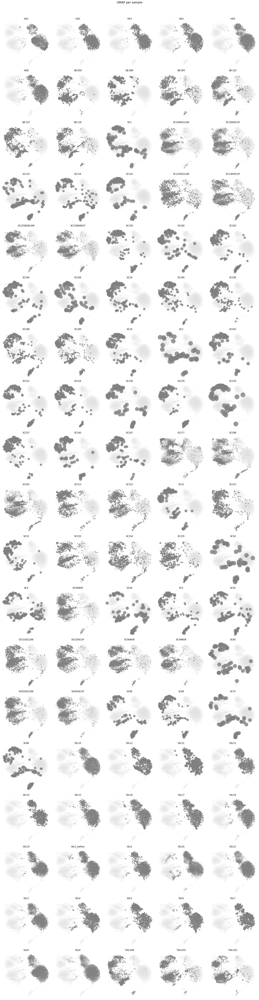

In [97]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['sample'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['sample'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per sample", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [23]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 2000
groupby = "Myeloid_subpopulation"

# Usa indici numerici invece dei nomi dei barcodes
subsampled_idx = []

for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():
    # Converti i nomi in posizioni numeriche
    positions = np.where(adata_all.obs.index.isin(indices))[0]
    n_cells = len(positions)
    
    if n_cells <= min_keep:
        chosen = positions
    else:
        chosen = np.random.choice(positions, size=min_keep, replace=False)
    
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Usa iloc-style indexing con indici numerici
adata_sub = adata_all[np.array(subsampled_idx), :].copy()

print(f"\nTotal cells before: {adata_all.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")

/tmp/ipykernel_2199619/4278027860.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():


Low_Quality          → kept 2000 / 10994 cells
Lung_ResidentMac_TREM2 → kept 2000 / 6242 cells
Mixed_ClassMono_DC2  → kept 2000 / 11070 cells
Mixed_MastMac        → kept 1411 / 1411 cells
PBMC_ClassMono_CD14  → kept 2000 / 48366 cells
PBMC_NonclassMono_FCGR3A → kept 2000 / 14261 cells
Pan_DifferentiatingMono_TREM2 → kept 2000 / 13720 cells
Pan_MastCells        → kept 2000 / 2376 cells
Pan_ResidentMac_FOLR2_LYVE1 → kept 1134 / 1134 cells
Pan_ResidentMac_TREM2 → kept 2000 / 21904 cells
Synov_DifferentiatingMono → kept 389 / 389 cells

Total cells before: 131867
Total cells after subsampling: 18934


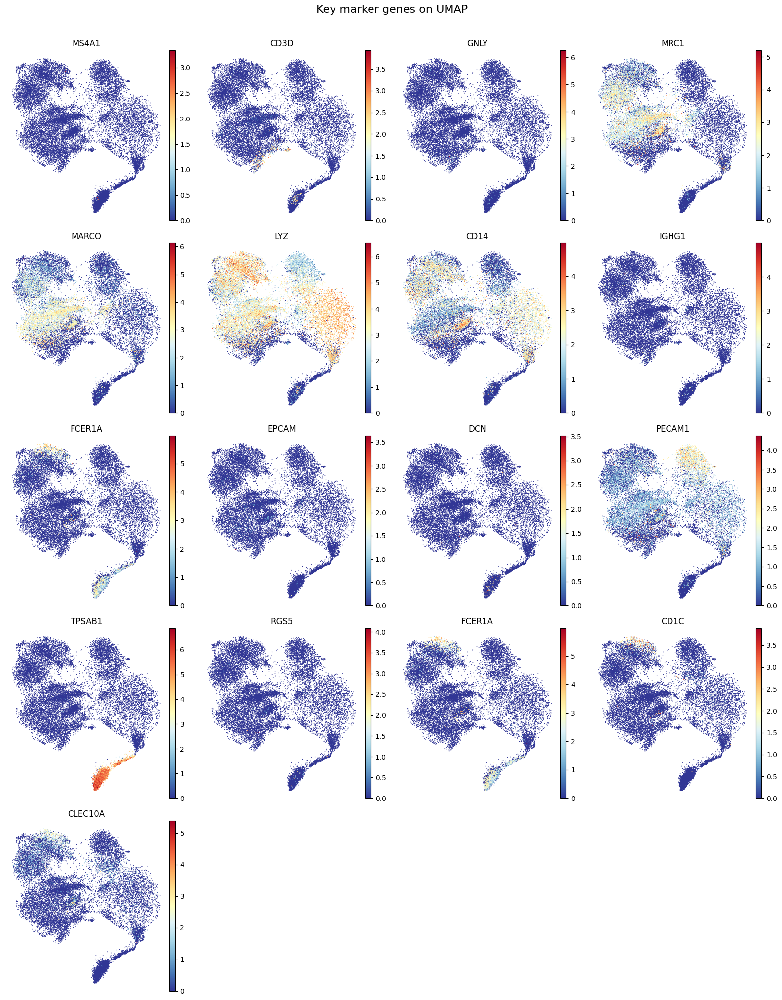

In [24]:
import matplotlib.pyplot as plt
import math

markers = {
    "B cells":       ["MS4A1"],           # CD20 — canonico e universale
    "T cells":       ["CD3D"],            # CD3 — pan-T
    "NK cells":      ["GNLY"],            # granulisina — pan-NK
    "Macrophages":   ["MRC1", "MARCO"],   # CD206 — pan-macrofagi
    "Monocytes":     ["LYZ", "CD14"],     # pan-monociti
    "Plasma cells":  ["IGHG1"],           # immunoglobulina — plasma cells
    "DC":            ["FCER1A"],          # recettore IgE — DC2/pan-DC
    "Epithelial":    ["EPCAM"],           # pan-epiteliale
    "Fibroblasts":   ["DCN"],             # decorina — pan-fibroblasti
    "Endothelial":   ["PECAM1"],          # CD31 — pan-endoteliale
    "Mast cells":    ["TPSAB1"],          # triptasi — pan-mast
    "Pericytes":     ["RGS5"],            # pan-periciti
    "DC2":                      ["FCER1A", "CD1C", "CLEC10A"],
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

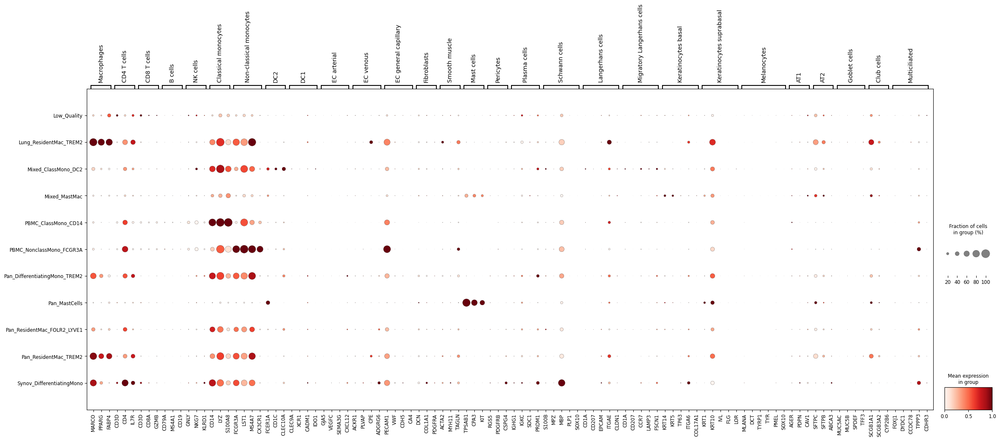

In [25]:
markers = {
    "Macrophages":     ["MARCO", "PPARG", "FABP4"],
    "CD4 T cells":              ["CD3D", "CD4", "IL7R"],
    "CD8 T cells":              ["CD3D", "CD8A", "GZMB"],
    "B cells":                  ["CD79A", "MS4A1", "CD19"],
    "NK cells":                 ["GNLY", "NKG7", "KLRD1"],
    "Classical monocytes":      ["CD14", "LYZ", "S100A8"],
    "Non-classical monocytes":  ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    "DC2":                      ["FCER1A", "CD1C", "CLEC10A"],
    "DC1":                      ["CLEC9A", "XCR1", "CADM1", "IDO1"],
    "EC arterial":              ["GJA5", "VEGFC", "SEMA3G", "CXCL12"],   # ← aggiunto
    "EC venous":                ["ACKR1", "PLVAP", "CPE", "ADGRG6"],     # ← aggiunto
    "EC general capillary":     ["PECAM1", "VWF", "CDH5", "CA4"],        # ← aggiunto CA4
    "Fibroblasts":              ["DCN", "COL1A1", "PDGFRA"],
    "Smooth muscle":            ["ACTA2", "MYH11", "TAGLN"],
    "Mast cells":               ["TPSAB1", "CPA3", "KIT"],
    "Pericytes":                ["RGS5", "PDGFRB", "CSPG4"],
    "Plasma cells":             ["IGHG1", "IGKC", "SDC1", "PRDM1"],
    "Schwann cells":            ["S100B", "MPZ", "MBP", "PLP1", "SOX10"],
    "Langerhans cells":         ["CD1A", "CD207", "EPCAM", "ITGAE", "CLDN1"],
    "Migratory Langerhans cells": ["CD1A", "CD207", "CCR7", "LAMP3", "FSCN1"],
    "Keratinocytes basal":      ["KRT14", "KRT5", "TP63", "ITGA6", "COL17A1"],
    "Keratinocytes suprabasal": ["KRT1", "KRT10", "IVL", "FLG", "LOR"],
    "Melanocytes":              ["MLANA", "DCT", "TYRP1", "TYR", "PMEL", "SOX10"],
    "AT1":                      ["AGER", "PDPN", "CAV1"],
    "AT2":                      ["SFTPC", "SFTPB", "ABCA3"],
    "Goblet cells":             ["MUC5AC", "MUC5B", "SPDEF", "TFF3"],
    "Club cells":               ["SCGB1A1", "SCGB3A2", "CYP2B6"],
    "Multiciliated":            ["FOXJ1", "DYDC1", "CCDC78", "TPPP3", "CDHR3"],
}

# Filtra i marker presenti nel dataset
all_markers_flat = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

# Verifica quali marker mancano
missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sc.pl.dotplot(
    adata_sub,
    var_names=markers,
    groupby="Myeloid_subpopulation",
    standard_scale="var",
    figsize=(28, 10),
)

In [39]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker dei macrofagi sinoviali umani (STMs), trascritti dallo schema
stm_markers = {
    "Tissue resident\n(MerTK+CD206+)": ["MERTK", "MRC1"],
    "TREM2_high":            ["TREM2"],
    "TREM2_low":             ["TREM2"],          # stesso marker, stato "low" -> distinzione solo quantitativa
    "FOLR2_LYVE1+":          ["FOLR2", "LYVE1"],
    "FOLR2_ID2+":            ["FOLR2", "ID2"],
    "FOLR2_ICAM1+":          ["FOLR2", "ICAM1"],
    "Tissue infiltrating\n(MerTK-CD206-)": ["CD48"],
    "CD48_S100A12+":         ["CD48", "S100A12"],
    "CD48_SPP1+":            ["CD48", "SPP1"],
    "CD48_ISG15+":           ["CD48", "ISG15"],
    "CD48_HLAhigh_CLEC10A+": ["CD48", "HLA-DRA", "HLA-DRB1", "CLEC10A"],
}

# Tieni solo i geni presenti e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in stm_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

stm_markers = {k: [g for g in v if g in present] for k, v in stm_markers.items()}
stm_markers = {k: v for k, v in stm_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=stm_markers,
    groupby="Myeloid_subpopulation",     # <-- cambia col nome della tua colonna myeloid
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(16, 5),
    show=True,
)

In [40]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker dei macrofagi sinoviali umani (STMs) - versione estesa
stm_markers = {
    "TREM2_high": [
        "TREM2", "MARCO", "VSIG4", "MSR1", "APOE", "APOC1",
        "C1QA", "C1QC", "TMEM176B", "DEFB1", "NDUFA1", "NDUFA4",
    ],
    "FOLR2_LYVE1+": [
        "FOLR2", "LYVE1", "HMOX1", "BLVRB", "F13A1", "A2M",
        "STAB1", "CSF1R", "GAS6", "LILRB5",
    ],
    "FOLR2_ID2+": [
        "FOLR2", "ID2", "REL", "KLF4", "KLF2", "KLF6", "JUN", "FOS",
    ],
    "FOLR2_ICAM1+": ["FOLR2", "ICAM1"],
    "CD48_S100A12+": [
        "CD48", "S100A12", "C5AR1", "IL1B", "CXCR4", "PGK1",
        "CD55", "SERPINA1", "TNFRSF1A", "TNFRSF1B",
    ],
    "CD48_SPP1+": [
        "CD48", "SPP1", "SLAMF7", "CD44", "ITGB2", "CD9",
        "FN1", "LDHA", "ENO1", "ALDOA", "PGAM1",
    ],
    "CD48_ISG15+": [
        "CD48", "ISG15", "TNFSF13B", "STAT1", "IRF1", "IRF4",
        "IFITM3", "IFI16",
    ],
    "CD48_HLAhigh_CLEC10A+": [
        "CD48", "CLEC10A", "HLA-DRB1", "HLA-DQB1", "HLA-DRB5",
        "ISG15", "STAT1", "IRF1",
    ],
}

# Tieni solo i geni presenti e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in stm_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

stm_markers = {k: [g for g in v if g in present] for k, v in stm_markers.items()}
stm_markers = {k: v for k, v in stm_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=stm_markers,
    groupby="Myeloid_subpopulation",   # <-- aggiorna col nome reale della colonna
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(24, 5),
    show=True,
)

In [41]:
import scanpy as sc
import matplotlib.pyplot as plt

# Marker dei macrofagi sinoviali umani (STMs), trascritti dallo schema
stm_markers = {
    "Tissue resident\n(MerTK+CD206+)": ["MERTK", "MRC1"],
    "TREM2_high":            ["TREM2"],
    "TREM2_low":             ["TREM2"],          # stesso marker, stato "low" -> distinzione solo quantitativa
    "FOLR2_LYVE1+":          ["FOLR2", "LYVE1"],
    "FOLR2_ID2+":            ["FOLR2", "ID2"],
    "FOLR2_ICAM1+":          ["FOLR2", "ICAM1"],
    "Tissue infiltrating\n(MerTK-CD206-)": ["CD48"],
    "CD48_S100A12+":         ["CD48", "S100A12"],
    "CD48_SPP1+":            ["CD48", "SPP1"],
    "CD48_ISG15+":           ["CD48", "ISG15"],
    "CD48_HLAhigh_CLEC10A+": ["CD48", "HLA-DRA", "HLA-DRB1", "CLEC10A"],
}

# Tieni solo i geni presenti e scarta i gruppi vuoti
present = set(adata_sub.var_names)
missing = [g for gs in stm_markers.values() for g in gs if g not in present]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

stm_markers = {k: [g for g in v if g in present] for k, v in stm_markers.items()}
stm_markers = {k: v for k, v in stm_markers.items() if v}

sc.pl.dotplot(
    adata_sub,
    var_names=stm_markers,
    groupby="Myeloid_subpopulation",     # <-- cambia col nome della tua colonna myeloid
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
    figsize=(16, 5),
    show=True,
)

In [42]:
import matplotlib.pyplot as plt
import math

markers = {
    "Tissue resident\n(MerTK+CD206+)": ["MERTK", "MRC1"],
    "TREM2_high":            ["TREM2"],
    "TREM2_low":             ["TREM2"],          # stesso marker, stato "low" -> distinzione solo quantitativa
    "FOLR2_LYVE1+":          ["FOLR2", "LYVE1"],
    "FOLR2_ID2+":            ["FOLR2", "ID2"],
    "FOLR2_ICAM1+":          ["FOLR2", "ICAM1"],
    "Tissue infiltrating\n(MerTK-CD206-)": ["CD48"],
    "CD48_S100A12+":         ["CD48", "S100A12"],
    "CD48_SPP1+":            ["CD48", "SPP1"],
    "CD48_ISG15+":           ["CD48", "ISG15"],
    "CD48_HLAhigh_CLEC10A+": ["CD48", "HLA-DRA", "HLA-DRB1", "CLEC10A"],
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [43]:
signatures = {
    "IFN-alpha (type I)": [
        "MX1", "MX2", "OAS1", "OAS2", "OAS3", "OASL", "IFI27", "IFI44",
        "IFI44L", "IFIT1", "IFIT3", "ISG15", "IFI6", "RSAD2", "USP18",
        "IRF7", "STAT1", "STAT2",
    ],
    "IFN-gamma (type II)": [
        "CXCL9", "CXCL10", "CXCL11", "GBP1", "GBP2", "GBP4", "GBP5",
        "IDO1", "SOCS1", "IRF1", "STAT1", "HLA-DRA", "HLA-DRB1",
        "CIITA", "TAP1", "PSMB9",
    ],
    "TNF signaling (NF-kB)": [
        "TNF", "TNFAIP3", "NFKB1", "NFKBIA", "REL", "RELB", "IL1B",
        "CXCL1", "CXCL2", "CXCL3", "CCL2", "CCL20", "PTGS2", "ICAM1",
        "TNFAIP2", "BIRC3", "NFKB2",
    ],
    "IL-1 family":          ["IL1A", "IL1B", "IL1RN", "IL18", "IL33", "IL36G"],
    "IL-6 / JAK-STAT3":     ["IL6", "IL6R", "IL6ST", "STAT3", "SOCS3", "OSM", "LIF"],
    "Th17 / IL-17 axis":    ["IL17A", "IL17F", "IL23A", "IL23R", "RORC", "CCR6"],
    "Th2 / IL-4-IL-13":     ["IL4", "IL13", "IL4R", "IL13RA1", "CCL17", "CCL22"],
    "Treg / IL-10":         ["IL10", "IL10RA", "FOXP3", "TGFB1"],
}

# Filtra i geni presenti
present = set(adata_sub.var_names)
missing = {k: [g for g in v if g not in present] for k, v in signatures.items()}
missing = {k: v for k, v in missing.items() if v}
if missing:
    print("Marker non trovati:", missing)

signatures = {k: [g for g in v if g in present] for k, v in signatures.items()}

sc.pl.dotplot(
    adata_sub,
    var_names=signatures,
    groupby="Myeloid_subpopulation",   # o il tuo cluster di interesse
    standard_scale="var",
    cmap="Reds",
    var_group_rotation=90,
    figsize=(26, 5),
    colorbar_title="Mean expression\n(scaled)",
    size_title="Fraction of cells\nin group (%)",
)

In [44]:
marker_genes_dict = {'SF1': ['PRG4'],
                     'SF2': 'CHI3L2',
                     'SF3': ['APOE'],
                     'SF4': ['POSTN'],
                     'SF5': ['FKBP5'],
                     'SF6': ['FOSB'],
                     'SF7': ['CXCL14'],
                     'SF8': ['MFAP5']}

In [45]:
IFN_ALPHA_genes = [
  "ADAR","B2M","BATF2","BST2","C1S","CASP1","CASP8","CCRL2","CD47","CD74",
  "CMPK2","CMTR1","CNP","CSF1","CXCL10","CXCL11","DDX60","DHX58","EIF2AK2",
  "ELF1","EPSTI1","GBP2","GBP4","GMPR","HELZ2","HERC6","HLA-C","IFI27","IFI30",
  "IFI35","IFI44","IFI44L","IFIH1","IFIT2","IFIT3","IFITM1","IFITM2","IFITM3",
  "IL15","IL4R","IL7R","IRF1","IRF2","IRF7","IRF9","ISG15","ISG20","LAMP3",
  "LAP3","LGALS3BP","LPAR6","LY6E","MOV10","MVB12A","MX1","NCOA7","NMI","NUB1",
  "OAS1","OASL","OGFR","PARP12","PARP14","PARP9","PLSCR1","PNPT1","PROCR","PSMA3",
  "PSMB8","PSMB9","PSME1","PSME2","RIPK2","RNF31","RSAD2","RTP4","SAMD9","SAMD9L",
  "SELL","SLC25A28","SP110","STAT2","TAP1","TDRD7","TENT5A","TMEM140","TRAFD1",
  "TRIM14","TRIM21","TRIM25","TRIM26","TRIM5","TXNIP","UBA7","UBE2L6","USP18","WARS1"
]

IFN_GAMMA_genes = ["ADAR","APOL6","ARID5B","ARL4A","AUTS2","B2M","BANK1","BATF2","BPGM","BST2",
    "BTG1","C1R","C1S","CASP1","CASP3","CASP4","CASP7","CASP8","CCL2","CCL5","CCL7",
    "CD274","CD38","CD40","CD69","CD74","CD86","CDKN1A","CFB","CFH","CIITA","CMKLR1",
    "CMPK2","CSF2RB","CXCL10","CXCL11","CXCL9","RIGI","DDX60","DHX58","EIF2AK2","EIF4E3",
    "EPSTI1","FAS","FCGR1A","FGL2","FPR1","CMTR1","GBP4","GBP6","GCH1","GPR18","GZMA",
    "HERC6","HIF1A","HLA-A","HLA-B","HLA-DMA","HLA-DQA1","HLA-DRB1","HLA-G","ICAM1",
    "IDO1","IFI27","IFI30","IFI35","IFI44","IFI44L","IFIH1","IFIT1","IFIT2","IFIT3",
    "IFITM2","IFITM3","IFNAR2","IL10RA","IL15","IL15RA","IL18BP","IL2RB","IL4R","IL6",
    "IL7","IRF1","IRF2","IRF4","IRF5","IRF7","IRF8","IRF9","ISG15","ISG20","ISOC1",
    "ITGB7","JAK2","KLRK1","LAP3","LATS2","LCP2","LGALS3BP","LY6E","LYSMD2","MARCHF1",
    "TMT1B","MT2A","MTHFD2","MVP","MX1","MX2","MYD88","NAMPT","NCOA3","NFKB1","NFKBIA",
    "NLRC5","NMI","NOD1","NUP93","OAS2","OAS3","OASL","OGFR","P2RY14","PARP12","PARP14",
    "PDE4B","PELI1","PFKP","PIM1","PLA2G4A","PLSCR1","PML","PNP","PNPT1","HELZ2",
    "PSMA2","PSMA3","PSMB10","PSMB2","PSMB8","PSMB9","PSME1","PSME2","PTGS2","PTPN1",
    "PTPN2","PTPN6","RAPGEF6","RBCK1","RIPK1","RIPK2","RNF213","RNF31","RSAD2","RTP4",
    "SAMD9L","SAMHD1","SECTM1","SELP","SERPING1","SLAMF7","SLC25A28","SOCS1","SOCS3",
    "SOD2","SP110","SPPL2A","SRI","SSPN","ST3GAL5","ST8SIA4","STAT1","STAT2","STAT3",
    "STAT4","TAP1","TAPBP","TDRD7","TNFAIP2","TNFAIP3","TNFAIP6","TNFSF10","TOR1B",
    "TRAFD1","TRIM14","TRIM21","TRIM25","TRIM26","TXNIP","UBE2L6","UPP1","USP18","VAMP5",
    "VAMP8","VCAM1","WARS1","XAF1","XCL1","ZBP1","ZNFX1"
]

COMP_CLASS_genes = [
    "C1QA","C1QB","C1QBP","C1QC","C1R","C1RL","C1S","C2","C4A","C4B","SERPING1","C4BPA","C4BPB","CSMD1"
]

COMP_ALT_genes = [
    "CFB","CFD","CFP","CFH","C3"
]

COMP_ALL_genes = [
    "C3","C5","C6","C7","C8A","C8B","C9","CFI","CR1","CD46","CD55","CD59","VTN","CLU","SVEP1","SUSD4","THBD"
]

sc.tl.score_genes(adata_all, gene_list=IFN_ALPHA_genes, score_name="IFN_ALPHA_genes")
sc.tl.score_genes(adata_all, gene_list=IFN_GAMMA_genes, score_name="IFN_GAMMA_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_CLASS_genes, score_name="COMP_CLASS_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALT_genes, score_name="COMP_ALT_genes")
sc.tl.score_genes(adata_all, gene_list=COMP_ALL_genes, score_name="COMP_ALL_genes")


Plotting IFN_ALPHA_genes ...


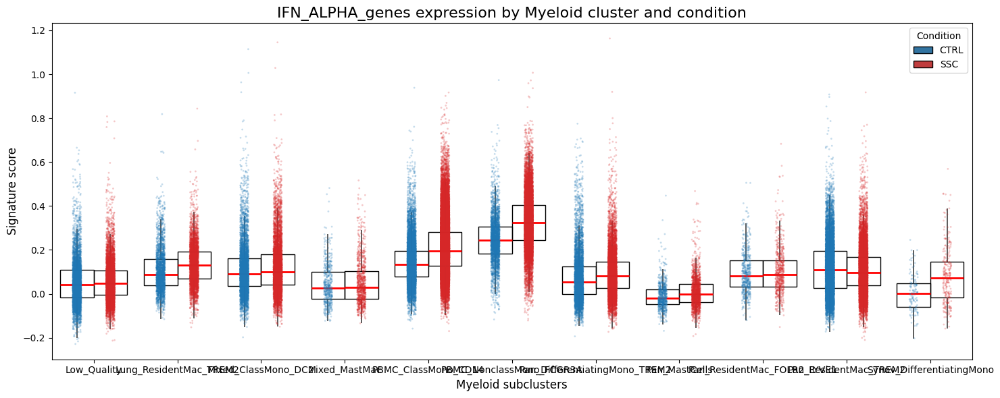

Plotting IFN_GAMMA_genes ...


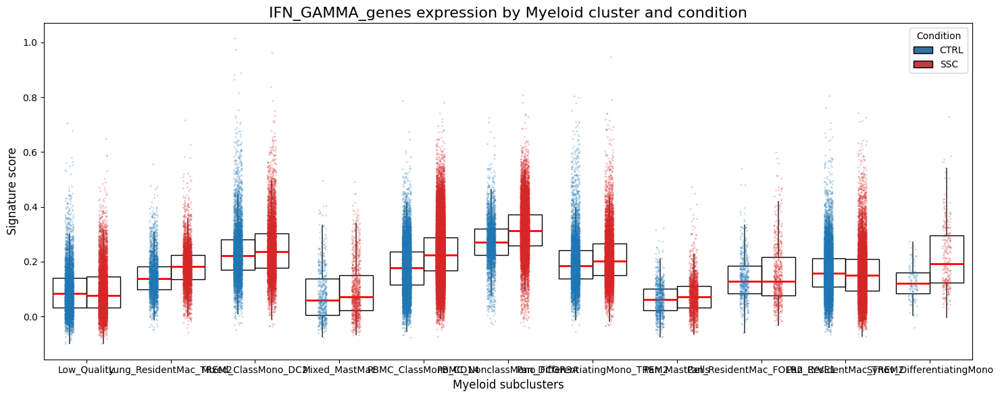

Plotting COMP_CLASS_genes ...


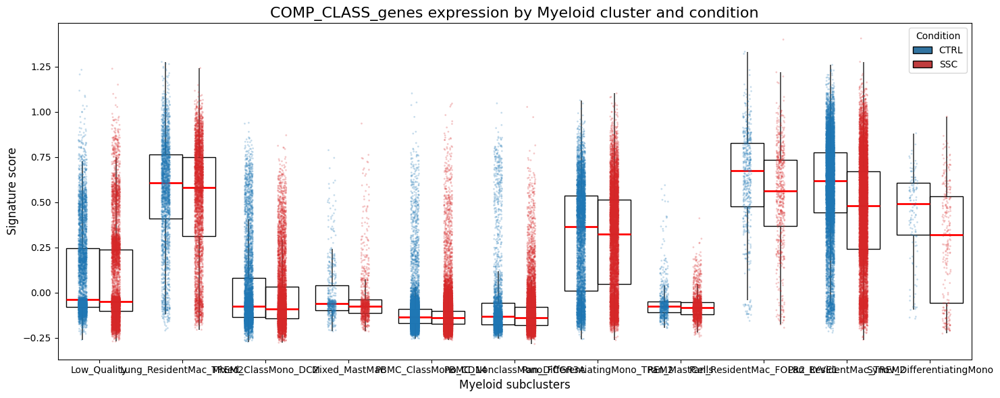

Plotting COMP_ALT_genes ...


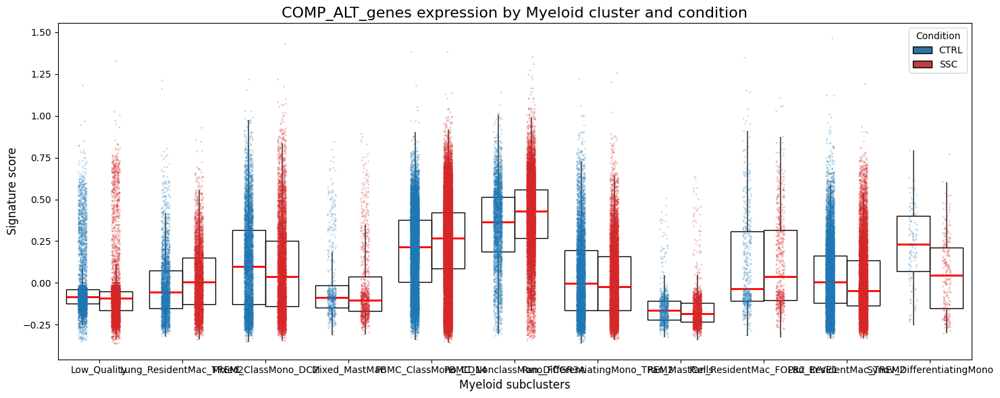

Plotting COMP_ALL_genes ...


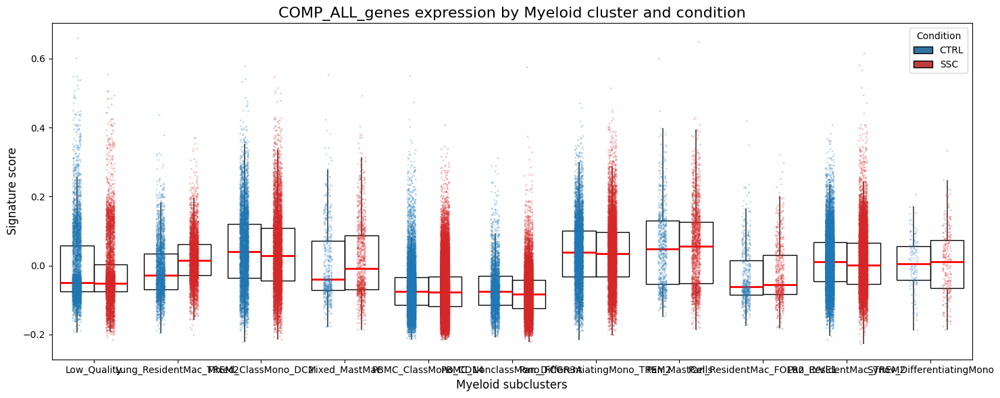

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

# Custom colors for the conditions
cond_palette = {
    "CTRL": "#1f77b4",   # blue
    "SSC":  "#d62728"    # red
}

# Ensure categories
adata_all.obs["Myeloid_subpopulation"] = adata_all.obs["Myeloid_subpopulation"].astype("category")
adata_all.obs["Condition"] = adata_all.obs["Condition"].astype("category")

for score in scores:
    print(f"Plotting {score} ...")

    df = adata_all.obs[[score, "Condition", "Myeloid_subpopulation"]].copy()

    # Drop rows where score is missing
    df = df.dropna(subset=[score])

    plt.figure(figsize=(15, 6))

    # --- BEAUTIFUL BOXPLOT WITH CUSTOM COLORS ---
    ax = sns.boxplot(
        data=df,
        x="Myeloid_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        showcaps=False,
        boxprops={'facecolor':'None', 'edgecolor':'black'},
        whiskerprops={'linewidth':1.2},
        medianprops={'color':'red', 'linewidth':2},
        showfliers=False
    )

    # --- DOTS WITH SAME COLORS ---
    sns.stripplot(
        data=df,
        x="Myeloid_subpopulation",
        y=score,
        hue='Condition',
        palette=cond_palette,
        dodge=True,
        jitter=True,
        alpha=0.25,
        size=2,
        linewidth=0
    )

    # Remove double legends (boxplot + stripplot)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], title="Condition")

    plt.title(f"{score} expression by Myeloid cluster and condition", fontsize=16)
    plt.xlabel("Myeloid subclusters", fontsize=12)
    plt.ylabel("Signature score", fontsize=12)

    plt.tight_layout()
    plt.show()


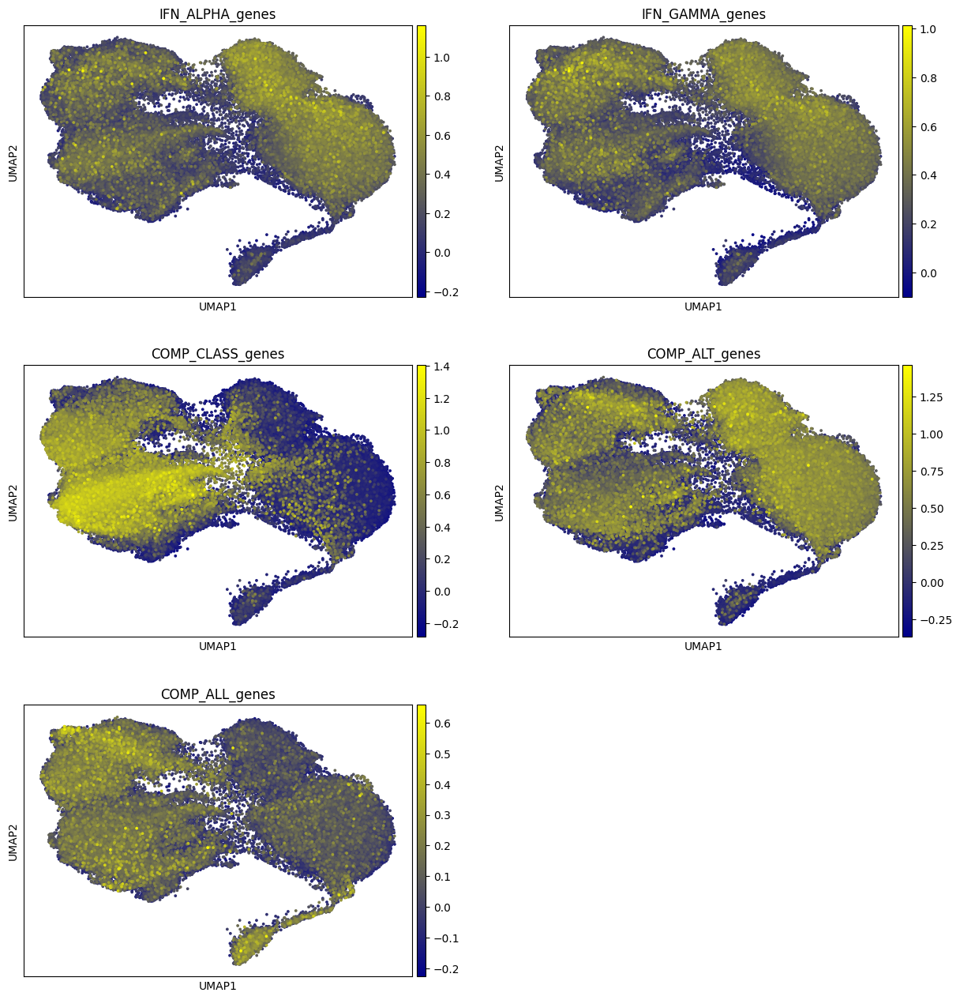

In [29]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

# List of scores to plot
scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

# Plot UMAP for all scores
sc.pl.umap(
    adata_all,
    color=scores,
    ncols=2,          # number of columns in the plot grid
    size=30,          # adjust dot size
    cmap=green_red,   # custom green-to-dark-red gradient
    show=True
)


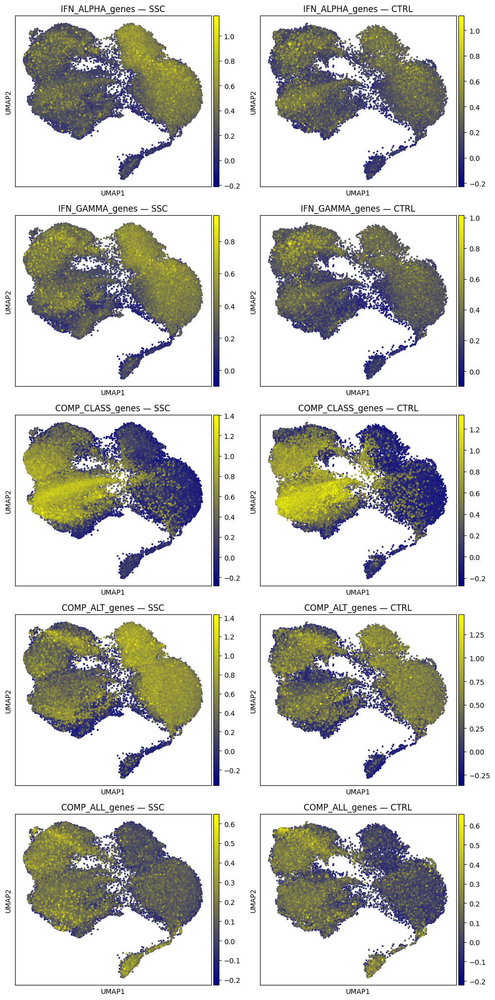

In [30]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["Condition"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["Condition"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

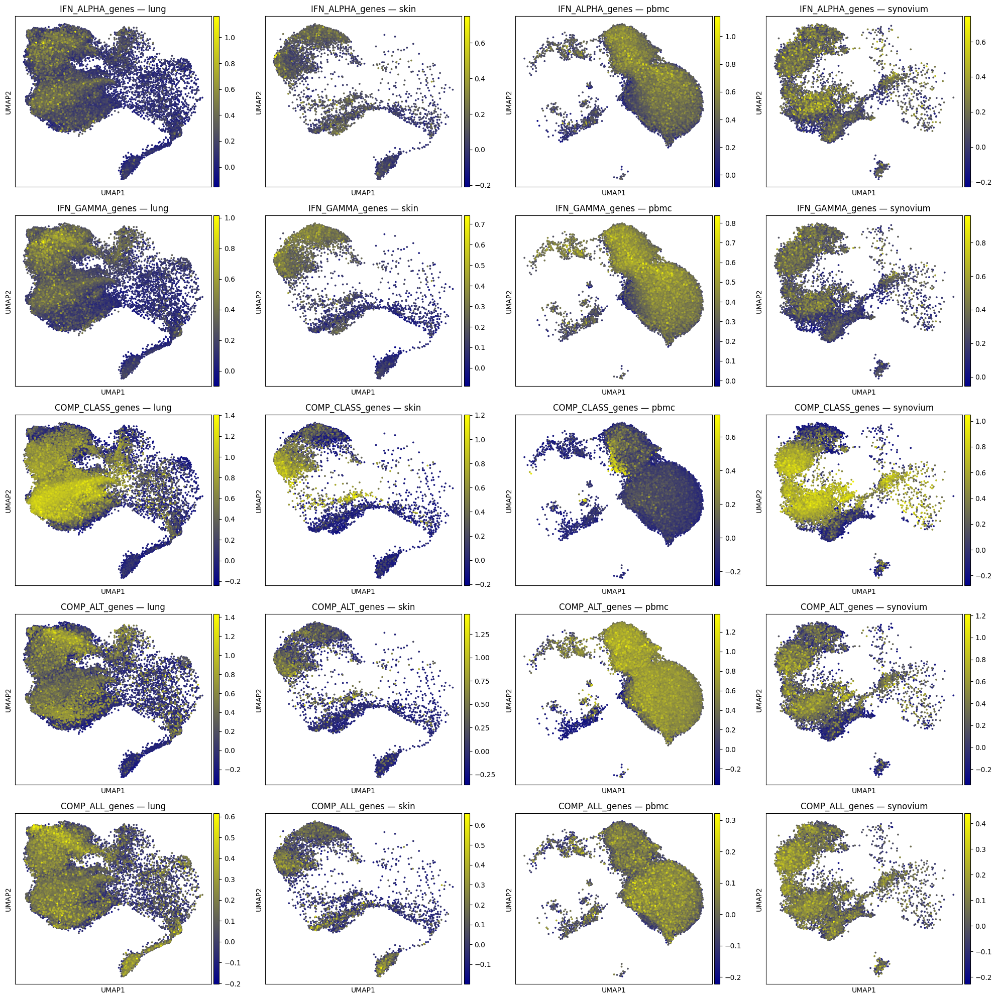

In [31]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Define a green-to-dark-red colormap
green_red = LinearSegmentedColormap.from_list("yellow_red", ["darkblue", "yellow"])

scores = [
    "IFN_ALPHA_genes",
    "IFN_GAMMA_genes",
    "COMP_CLASS_genes",
    "COMP_ALT_genes",
    "COMP_ALL_genes"
]

conditions = adata_all.obs["tissue"].unique().tolist()  # es. ['SSC', 'CTRL']

# Griglia: righe = score, colonne = condizioni
fig, axes = plt.subplots(
    nrows=len(scores), ncols=len(conditions),
    figsize=(5 * len(conditions), 4 * len(scores))
)

for i, score in enumerate(scores):
    for j, cond in enumerate(conditions):
        ax = axes[i, j] if len(scores) > 1 else axes[j]
        subset = adata_all[adata_all.obs["tissue"] == cond]
        sc.pl.umap(
            subset,
            color=score,
            size=30,
            cmap=green_red,
            ax=ax,
            show=False,
            title=f"{score} — {cond}"
        )

plt.tight_layout()
plt.show()

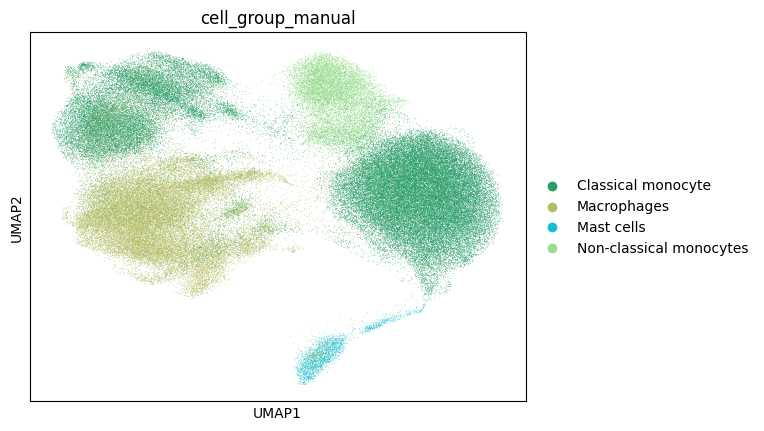

In [32]:
sc.pl.umap(adata_all, color=['cell_group_manual'])


In [33]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

scores = [
    'IFN_ALPHA_genes',
    'IFN_GAMMA_genes',
    'COMP_CLASS_genes',
    'COMP_ALT_genes',
    'COMP_ALL_genes'
]

adata_all.obs["Myeloid_subpopulation"] = adata_all.obs["Myeloid_subpopulation"].astype("category")

all_results = {}   # store results for each score

for score in scores:
    print(f"\n🔎 Running statistics for: {score}")

    df = adata_all.obs[[score, "Condition", "Myeloid_subpopulation"]].copy()
    df = df.dropna(subset=[score])

    results = []

    for cl in df["Myeloid_subpopulation"].cat.categories:
        subset = df[df["Myeloid_subpopulation"] == cl]

        ssc = subset[subset["Condition"] == "SSC"][score]
        ctrl = subset[subset["Condition"] == "CTRL"][score]

        if len(ssc) > 3 and len(ctrl) > 3:
            stat, p = mannwhitneyu(ssc, ctrl, alternative="two-sided")
        else:
            p = np.nan

        results.append({
            "cluster": cl,
            "n_SSC": len(ssc),
            "n_CTRL": len(ctrl),
            "p_value": p
        })

    stats_table = pd.DataFrame(results)

    # FDR correction (Benjamini–Hochberg)
    valid_mask = stats_table["p_value"].notna()
    _, fdr_corrected, _, _ = multipletests(
        stats_table.loc[valid_mask, "p_value"],
        method="fdr_bh"
    )
    stats_table.loc[valid_mask, "FDR"] = fdr_corrected

    all_results[score] = stats_table
    print(stats_table)



🔎 Running statistics for: IFN_ALPHA_genes
                          cluster  n_SSC  n_CTRL        p_value            FDR
0                     Low_Quality   6160    4834   3.584682e-04   4.381278e-04
1          Lung_ResidentMac_TREM2   3875    2367   5.110504e-46   1.405389e-45
2             Mixed_ClassMono_DC2   6065    5005   3.917384e-07   5.386403e-07
3                   Mixed_MastMac    905     506   4.202390e-01   4.202390e-01
4             PBMC_ClassMono_CD14  37929   10437   0.000000e+00   0.000000e+00
5        PBMC_NonclassMono_FCGR3A  11413    2848  1.962966e-235  1.079631e-234
6   Pan_DifferentiatingMono_TREM2   8151    5569   1.628937e-48   5.972768e-48
7                   Pan_MastCells   1657     719   1.945093e-10   4.279206e-10
8     Pan_ResidentMac_FOLR2_LYVE1    612     522   1.940051e-01   2.134056e-01
9           Pan_ResidentMac_TREM2  11737   10167   6.795416e-08   1.067851e-07
10      Synov_DifferentiatingMono    255     134   2.511190e-09   4.603848e-09

🔎 Runnin

In [34]:
#Calculating the markers for each subpopulation:
import scanpy as sc
import pandas as pd

# Make sure cell type column is categorical
adata_all.obs['Myeloid_subpopulation'] = adata_all.obs['Myeloid_subpopulation'].astype('category')

# 1️⃣ Compute one-vs-all markers
sc.tl.rank_genes_groups(
    adata_all,
    groupby='Myeloid_subpopulation',    # column with cell type labels
    method='wilcoxon',      # equivalent to Seurat default
    n_genes=adata_all.shape[1],  
    pts=True                 # include fraction of cells expressing the gene
)

# 2️⃣ Extract results into a tidy DataFrame
markers = adata_all.uns['rank_genes_groups']
cell_types = markers['names'].dtype.names

marker_list = []
for ct in cell_types:
    n_genes = len(markers['names'][ct])
    for i in range(n_genes):
        # Fraction of cells expressing gene in the cluster
        pct = markers['pts'][ct][i]
        if pct >= 0.1:  # min.pct = 0.1
            marker_list.append({
                'Myeloid_subpopulation': ct,
                'gene': markers['names'][ct][i],
                'logfoldchange': markers['logfoldchanges'][ct][i],
                'pval': markers['pvals'][ct][i],
                'pval_adj': markers['pvals_adj'][ct][i],
                'pct_in_group': markers['pts'][ct][i],
                'pct_rest': markers['pts_rest'][ct][i]
            })

marker_df = pd.DataFrame(marker_list)

# 3️⃣ Sort by cell type and log fold change (optional)
marker_df = marker_df.sort_values(['Myeloid_subpopulation', 'logfoldchange'], ascending=[True, False])

# Show top markers
marker_df.head(10)


/tmp/ipykernel_2199619/3620098905.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  pct = markers['pts'][ct][i]
/tmp/ipykernel_2199619/3620098905.py:34: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'pct_in_group': markers['pts'][ct][i],
/tmp/ipykernel_2199619/3620098905.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'pct_rest': markers['pts_rest'][ct][i]


,Myeloid_subpopulation,gene,logfoldchange,pval,pval_adj,pct_in_group,pct_rest
632,Low_Quality,LINC02676,19.428507,0.962158,1.0,0.110970,0.313809
793,Low_Quality,KRT26,19.174263,0.987382,1.0,0.263780,0.434075
796,Low_Quality,GSTT4,18.380653,0.987382,1.0,0.335001,0.774623
792,Low_Quality,KRT82,18.114912,0.987382,1.0,0.121430,0.353586
797,Low_Quality,GBX2,17.590353,0.987382,1.0,0.208932,0.472364
689,Low_Quality,TRAJ54,17.351316,0.975914,1.0,0.101783,0.290421
818,Low_Quality,LINC01671,16.793432,0.989677,1.0,0.120338,0.398443
795,Low_Quality,COL5A1-AS1,16.320934,0.987382,1.0,0.330089,0.871303
794,Low_Quality,LINC00692,16.279972,0.987382,1.0,0.129343,0.220620
804,Low_Quality,FOXG1,16.257559,0.988529,1.0,0.102692,0.275943


In [35]:
import os
# Set as working directory
os.chdir("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Myeloid_subpop/")


In [36]:
import os

# Create the output folder if it doesn't exist
output_dir = "markers_subMyeloid"
os.makedirs(output_dir, exist_ok=True)

# Save markers for each cell type separately
for ct in marker_df['Myeloid_subpopulation'].unique():
    df_ct = marker_df[marker_df['Myeloid_subpopulation'] == ct].copy()
    # Optional: sort by log fold change descending
    df_ct = df_ct.sort_values('logfoldchange', ascending=False)
    # Save to CSV
    filename = os.path.join(output_dir, f"{ct.replace('/', '_').replace(' ', '_')}_markers.csv")
    df_ct.to_csv(filename, index=False)

print(f"✅ Marker files saved in folder '{output_dir}'")


✅ Marker files saved in folder 'markers_subMyeloid'


In [3]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_myeloid.py
#   (myeloid counterpart of subpopulation_marker_dotplot.py, fibroblasts)
#
# PURPOSE:
#   Dotplot of curated marker genes across myeloid subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing the
#             tissue specificity of each subpopulation (PBMC / lung /
#             synovium / pan).
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it) - but every
#             subpopulation still gets ITS OWN logFC/pct dot in every gene
#             column (not just the "owning" population), so shared markers
#             (e.g. MARCO across both macrophage subpopulations) show
#             correctly in every row that expresses them.
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels (here, the myeloid
#   cluster annotation - Mixed_* and Low_Quality clusters are excluded
#   below, same convention as EXCLUDE_LABELS in the main pipeline / as done
#   for fibroblasts' "Mixed" cluster in the hierarchical pathway heatmap).
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot_Myeloid.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot_Myeloid")

SUBPOP_COL = "Myeloid_subpopulation"

# Full cluster -> subpopulation-name annotation, for reference (this is
# MYELOID_CLUSTER_ANNOTATION as shared) - Mixed_* and Low_Quality are
# deliberately NOT included in MANUAL_MARKERS / SUBPOP_ORDER below, so they
# are simply never plotted here (they can still be fully analysed
# elsewhere in the pipeline, same "hard filter from this figure only"
# convention already used for fibroblasts' "Mixed" and the hierarchical
# pathway heatmap's EXCLUDE_FROM_FIGURE):
#   "0":  "Mixed_ClassMono_DC2",          <- excluded (Mixed)
#   "1":  "Pan_DifferentiatingMono_TREM2",
#   "2":  "PBMC_NonclassMono_FCGR3A",
#   "3":  "PBMC_ClassMono_CD14",
#   "4":  "Pan_ResidentMac_TREM2",
#   "5":  "Low_Quality",                  <- excluded (not biological)
#   "6":  "Lung_ResidentMac_TREM2",
#   "7":  "Low_Quality",                  <- excluded (not biological)
#   "8":  "PBMC_ClassMono_CD14",
#   "9":  "Synov_DifferentiatingMono",
#   "10": "Pan_ResidentMac_FOLR2_LYVE1",
#   "11": "Pan_MastCells",
#   "12": "Mixed_MastMac",                <- excluded (Mixed)

MANUAL_MARKERS = {
    # PBMC (circulating monocytes)
    "PBMC_ClassMono_CD14":           ["CD14", "LYZ", "S100A8"],
    "PBMC_NonclassMono_FCGR3A":      ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    # Lung
    "Lung_ResidentMac_TREM2":        ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    # Synovium
    "Synov_DifferentiatingMono":     ["CD14", "MARCO"],
    # Pan-tissue
    "Pan_DifferentiatingMono_TREM2": ["CD14", "MARCO"],
    "Pan_ResidentMac_TREM2":         ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    "Pan_ResidentMac_FOLR2_LYVE1":   ["FOLR2", "LYVE1", "MERTK", "MRC1"],
    "Pan_MastCells":                 ["TPSAB1", "CPA3", "KIT"],
}

# Row order = tissue order (PBMC > lung > synovium > pan), mirroring the
# fibroblast script's skin > lung > synovium > pan grouping
SUBPOP_ORDER = [
    "PBMC_ClassMono_CD14",
    "PBMC_NonclassMono_FCGR3A",
    "Lung_ResidentMac_TREM2",
    "Synov_DifferentiatingMono",
    "Pan_DifferentiatingMono_TREM2",
    "Pan_ResidentMac_TREM2",
    "Pan_ResidentMac_FOLR2_LYVE1",
    "Pan_MastCells",
]

SUBPOP_TISSUE = {
    "PBMC_ClassMono_CD14":           "pbmc",
    "PBMC_NonclassMono_FCGR3A":      "pbmc",
    "Lung_ResidentMac_TREM2":        "lung",
    "Synov_DifferentiatingMono":     "synovium",
    "Pan_DifferentiatingMono_TREM2": "pan",
    "Pan_ResidentMac_TREM2":         "pan",
    "Pan_ResidentMac_FOLR2_LYVE1":   "pan",
    "Pan_MastCells":                 "pan",
}

TISSUE_COLORS = {
    "pbmc":     "#c83737ff",   # circulating/blood monocytes
    "lung":     "#d4aa00ff",   # same hex as the fibroblast figure
    "synovium": "#5f8dd3ff",   # same hex as the fibroblast figure
    "pan":      "#CCCCCC",
}

TISSUE_LABELS = {"pbmc": "PBMC (blood)", "lung": "Lung", "synovium": "Synovium",
                  "pan": "Pan-tissue"}


# Figure / style
FIG_W, FIG_H   = 6.5, 2.2
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {subpops}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {marker_gene_owner[gene]} "
                  f"- column not duplicated for {sp} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels(subpops, fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']
  Subpopulations to plot (8): ['PBMC_ClassMono_CD14', 'PBMC_NonclassMono_FCGR3A', 'Lung_ResidentMac_TREM2', 'Synov_DifferentiatingMono', 'Pan_DifferentiatingMono_TREM2', 'Pan_ResidentMac_TREM2', 'Pan_ResidentMac_FOLR2_LYVE1', 'Pan_MastCells']

[2/4] Building marker gene list from MANUAL_MARKERS...
  NOTE: 'CD14' already assigned to PBMC_ClassMono_CD14 - column not duplicated for Synov_DifferentiatingMono (its dot is still shown)
  NOTE: 'MARCO' already assigned to Lung_ResidentMac_TREM2 - column not duplicated for Synov_DifferentiatingMono (its dot is still shown)
  NOTE: 'CD14' already assigned to PBMC_ClassMono_CD14 - column not duplicated for Pan_DifferentiatingMono_TREM2 (its dot is still shown)
  NOTE: 'MARCO' already assigned to Lung_ResidentMac_TREM2 - column not duplicated for Pan_DifferentiatingMono_TREM2 (its dot 

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import random

np.random.seed(0)
random.seed(0)




#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Monocytes.h5ad")
adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_SSC_Monocytes.h5ad")

In [2]:
#!/usr/bin/env python3
"""
merge_replicate_samples_lymphocytes.py

Applica alla sottopopolazione (adata_all, gia' in memoria) la STESSA fusione
dei campioni replicati gia' fatta sull'atlante principale - solo sui
metadati ('obs'), senza toccare X/obsm/uns e senza ricaricare o risalvare
l'oggetto.

Cosa fa, in-place su adata_all.obs:
  1. Copia 'sample' (nomi originali) in 'replicates_samples'.
  2. Sovrascrive 'sample' fondendo i gruppi in INDIVIDUAL_GROUPS sotto il
     nome del primo campione del gruppo - esattamente come nell'atlante
     principale, cosi' 'sample' resta coerente ovunque.

Assunzione: adata_all.obs ha le colonne 'batch' e 'sample' (stessi nomi
dell'atlante principale, essendo questo oggetto derivato da li'). Se sono
diversi, dimmelo e aggiorno BATCH_COL.
"""

BATCH_COL = "batch"

# Stessi gruppi usati per l'atlante principale.
INDIVIDUAL_GROUPS = {
    "GSE128169": [
        ["SC51SSCLOW", "SC52SSCUP"],     # SSc 1/2
        ["SC63SSCLOW", "SC64SSCUP"],     # SSc 3/4
        ["SC108SSCLOW", "SC109SSCUP"],   # SSc 5
        ["SC135SSCLOW", "SC136SSCUP"],   # SSc 7/8
        ["SC155NORLOW", "SC156NORUP"],   # Control 4/5
    ],
}

for col in (BATCH_COL, "sample"):
    if col not in adata_all.obs.columns:
        raise SystemExit(
            f"ERRORE: manca la colonna '{col}' in adata_all.obs. "
            f"Colonne disponibili: {list(adata_all.obs.columns)}"
        )

obs = adata_all.obs
obs["sample"] = obs["sample"].astype(object)
obs["replicates_samples"] = obs["sample"]

print("Merge di 'sample' a livello di individuo ...")
n_groups = 0
for batch, groups in INDIVIDUAL_GROUPS.items():
    for group in groups:
        mask = (obs[BATCH_COL] == batch) & (obs["replicates_samples"].isin(group))
        if mask.sum() == 0:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> 0 cellule (non presente in "
                  f"questa sottopopolazione, normale se filtrato), saltato.")
            continue
        found = sorted(obs.loc[mask, "replicates_samples"].unique())
        missing = sorted(set(group) - set(found))
        if missing:
            print(f"  ATTENZIONE: gruppo {group} ({batch}) -> mancano: {missing}")
        obs.loc[mask, "sample"] = group[0]
        n_groups += 1
        print(f"  {batch}: {found} -> sample = '{group[0]}'")

obs["sample"] = obs["sample"].astype("category")
obs["replicates_samples"] = obs["replicates_samples"].astype("category")

n_replicates = obs[[BATCH_COL, "replicates_samples"]].drop_duplicates().shape[0]
n_samples = obs[[BATCH_COL, "sample"]].drop_duplicates().shape[0]
print(f"\nTotale: {n_replicates} replicates_samples -> {n_samples} sample ({n_groups} gruppi uniti)")

Merge di 'sample' a livello di individuo ...
  GSE128169: ['SC51SSCLOW', 'SC52SSCUP'] -> sample = 'SC51SSCLOW'
  GSE128169: ['SC63SSCLOW', 'SC64SSCUP'] -> sample = 'SC63SSCLOW'
  GSE128169: ['SC108SSCLOW', 'SC109SSCUP'] -> sample = 'SC108SSCLOW'
  GSE128169: ['SC135SSCLOW', 'SC136SSCUP'] -> sample = 'SC135SSCLOW'
  GSE128169: ['SC155NORLOW', 'SC156NORUP'] -> sample = 'SC155NORLOW'

Totale: 95 replicates_samples -> 90 sample (5 gruppi uniti)


In [3]:
import pandas as pd

ct = pd.crosstab(adata_all.obs["Myeloid_subpopulation"], adata_all.obs["tissue"])
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

print(pct.to_string())

tissue                         lung  pbmc  skin  synovium
Myeloid_subpopulation                                    
Low_Quality                    64.7   3.9   7.9      23.5
Lung_ResidentMac_TREM2         96.3   0.3   0.3       3.0
Mixed_ClassMono_DC2            66.6   3.7  17.4      12.3
Mixed_MastMac                  61.5  18.9  18.1       1.6
PBMC_ClassMono_CD14             3.4  95.6   0.4       0.6
PBMC_NonclassMono_FCGR3A        6.2  92.8   0.3       0.7
Pan_DifferentiatingMono_TREM2  64.7   0.3  12.5      22.4
Pan_MastCells                  57.8   0.7  34.0       7.4
Pan_ResidentMac_FOLR2_LYVE1    57.6   3.3  13.2      25.9
Pan_ResidentMac_TREM2          82.9   0.2   0.7      16.2
Synov_DifferentiatingMono       5.9   0.3   0.8      93.1


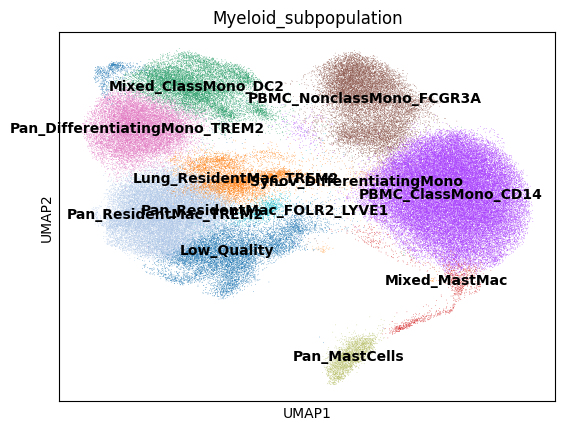

In [4]:
sc.pl.umap(adata_all, color='Myeloid_subpopulation', legend_loc='on data')

In [5]:
adata_all.obs["Myeloid_subpopulation"] = (
    adata_all.obs["Myeloid_subpopulation"]
    .astype(str)
    .replace({"Pan_ResidentMac_TREM2": "Lung_ResidentMac_TREM2"})
    .astype("category")
)

In [3]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

sns.set(style="whitegrid")


from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats


def run_pseudobulk_transform(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """

    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)


def run_de_for_cluster(
    adata,
    cluster_col,
    condition_col,
    cluster,
    cond1,
    cond2,
    sample_col="sample",
    method="pydeseq2",
    min_pct=0.10,
    outdir="PseudoBulk_matrices"
):
    """
    Run differential expression for one cluster comparing cond1 vs cond2 using PyDESeq2,
    after pseudobulking counts by sample.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    # Subset to the cluster of interest
    ad = adata[adata.obs[cluster_col] == cluster].copy()

    # Keep only desired conditions
    mask = ad.obs[condition_col].isin([cond1, cond2])
    ad = ad[mask].copy()
    if ad.n_obs == 0:
        raise ValueError(f"No cells for cluster {cluster} and conditions {cond1}/{cond2}")

    print(f"Running PyDESeq2 (pseudobulk) for cluster {cluster}: {cond1} vs {cond2}")

    # --- Convert to dense count matrix ---
    counts = ad.X.toarray() if not isinstance(ad.X, np.ndarray) else ad.X
    counts = pd.DataFrame(
        counts.astype(int),
        index=ad.obs_names,
        columns=ad.var_names
    )

    # --- Aggregate counts by sample (pseudobulk) ---
    print("Aggregating counts by sample...")
    ad.obs[sample_col] = ad.obs[sample_col].astype(str)
    ad.obs[condition_col] = ad.obs[condition_col].astype(str)

    # Sum counts per sample
    counts["sample_id"] = ad.obs[sample_col].values
    pseudo_counts = counts.groupby("sample_id").sum()

    # One metadata row per sample
    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
    )
    meta[condition_col] = meta[condition_col].astype("category")

    print(f"Pseudobulked to {pseudo_counts.shape[0]} samples × {pseudo_counts.shape[1]} genes")

    # --- Run PyDESeq2 ---
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats

    dds = DeseqDataSet(
        counts=pseudo_counts,
        metadata=meta,
        design_factors=condition_col
    )


    meta = (
        ad.obs[[sample_col, condition_col]]
        .drop_duplicates(subset=sample_col)
        .set_index(sample_col)
        .loc[pseudo_counts.index]
        .reset_index()  # sample becomes a column again
    )

    pseudo_counts = counts.groupby("sample_id").sum()
    pseudo_counts["sample"] = pseudo_counts.index
    
    cluster_dir = outdir / f"{cluster}"
    cluster_dir.mkdir(exist_ok=True, parents=True)
    pseudo_counts.to_csv(cluster_dir / f"PseudoBulk_{cluster}.tsv", sep="\t", index=False)
    meta.to_csv(cluster_dir / f"Metadata_{cluster}.tsv", sep="\t", index=False)

    print("Running DESeq2 model...")
    dds.deseq2()  # safer single-thread mode

    contrast = [condition_col, cond1, cond2]
    stats = DeseqStats(dds, contrast=contrast, independent_filter=False)
    stats.summary()
    stats.results_df.head()

    
    return stats


def volcano_plot(df, title, out_png=None, lfc_thresh=0.5, pval_thresh=0.05, top_n=15):
    """
    df must contain 'Gene', 'avg_log2FC', 'p_val' columns.
    Produces a volcano-style scatter and labels top genes.
    """
    df = df.copy()
    df['neglog10_p'] = -np.log10(df['p_val'].replace(0, 1e-50))
    # significance label
    df['Significance'] = 'Not Significant'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] > lfc_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['p_val'] < pval_thresh) & (df['avg_log2FC'] < -lfc_thresh), 'Significance'] = 'Downregulated'

    palette = {'Upregulated': 'red', 'Downregulated': 'blue', 'Not Significant': 'black'}
    plt.figure(figsize=(8, 6))
    ax = sns.scatterplot(data=df, x='avg_log2FC', y='neglog10_p', hue='Significance',
                         palette=palette, alpha=0.6, edgecolor=None, legend='brief')

    # vertical/horizontal lines
    ax.axvline(-lfc_thresh, color='gray', linestyle='--')
    ax.axvline(lfc_thresh, color='gray', linestyle='--')
    ax.axhline(-np.log10(pval_thresh), color='gray', linestyle='--')

    # annotate top genes (by logFC within each direction)
    up = df[df['Significance'] == 'Upregulated'].sort_values('avg_log2FC', ascending=False).head(top_n)
    down = df[df['Significance'] == 'Downregulated'].sort_values('avg_log2FC').head(top_n)
    top_genes = pd.concat([up, down])

    for _, row in top_genes.iterrows():
        ax.text(row['avg_log2FC'], row['neglog10_p'], row['Gene'], fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("log fold change")
    ax.set_ylabel("-log10(p-value)")
    plt.legend(title='Significance', loc='upper right')
    plt.tight_layout()
    if out_png:
        plt.savefig(out_png, dpi=150)
        plt.close()
    else:
        plt.show()


def run_preranked_gsea(ranked_series, gmt_path, outdir, min_size=15, max_size=500, permutation_num=1000):
    """
    Run preranked GSEA (FGSEA equivalent) using gseapy.prerank.
    ranked_series: pandas.Series indexed by gene symbol with numeric ranking (e.g. logFC),
                   sorted descending (largest positive first).
    gmt_path: path to GMT file
    returns: results dataframe (gseapy output)
    """
    os.makedirs(outdir, exist_ok=True)
    # gseapy expects a file or dataframe; we pass the pd.Series as a rnk file
    rnk = ranked_series.reset_index()
    rnk.columns = ['gene_name', 'score']
    # gseapy.prerank requires a file or dataframe with two columns
    pre_res = gp.prerank(rnk=rnk,
                         gene_sets=gmt_path,
                         processes=4,
                         permutation_num=permutation_num,
                         min_size=min_size,
                         max_size=max_size,
                         outdir=outdir,
                         seed=123)
    # pre_res.res2d is a pandas DataFrame with NES, pval, fdr (FDR is padj)
    res_df = pre_res.res2d.copy()
    # unify column names
    #if 'fdr' in res_df.columns:
    #   res_df = res_df.rename(columns={'fdr': 'padj', 'es': 'ES', 'nes': 'NES', 'pval': 'pval'})
    return res_df


def run_dge_and_gsea_all_clusters(adata, cluster_col, condition_col, cond1, cond2,
                                  outdir="DGE_GSEA_results",
                                  gmt_files=None,
                                  de_method="wilcoxon",
                                  lfc_cutoff=0.5,
                                  pvalue_cutoff=0.05):
    """
    Iterate clusters in cluster_col, run DE (cond1 vs cond2), run GSEA on ranked gene list,
    save results and produce plots.
    """
    outdir = Path(outdir)
    outdir.mkdir(exist_ok=True, parents=True)
    clusters = adata.obs[cluster_col].unique().tolist()
    

    for cluster in clusters:
        print(f"Processing cluster: {cluster}")

        # --- Skip clusters with too few cells ---
        n_cells = (adata.obs[cluster_col] == cluster).sum()
        print(f"Cluster {cluster}: has {n_cells} cells.")
        if n_cells < 50:
            print(f"Skipping cluster {cluster}: only {n_cells} cells (< 50).")
            continue
        # ----------------------------------------

        # --- Check that both conditions are sufficiently represented ---
        ad_cluster = adata[adata.obs[cluster_col] == cluster]
        cond_counts = ad_cluster.obs[condition_col].value_counts()
        n_cond1 = cond_counts.get(cond1, 0)
        n_cond2 = cond_counts.get(cond2, 0)
        
        print(f"Cluster {cluster}: has {n_cond1} cells in {cond1} and {cond2} in {n_cond2}.")

        df_de = run_pseudobulk_transform(adata, cluster_col, condition_col, cluster, cond1, cond2)
        if n_cond1 < 10 or n_cond2 < 10:
            print(f"Skipping cluster {cluster}: insufficient cells per condition "
                  f"({cond1}: {n_cond1}, {cond2}: {n_cond2}).")
            continue
        # --------------------------------------------------------------

        try:
            print("TRYING")
            stats = run_de_for_cluster(adata, cluster_col, condition_col, cluster, cond1, cond2, method=de_method)
            res = stats.results_df.copy()

            df_de = (
                res.rename(
                    columns={
                        "log2FoldChange": "avg_log2FC",
                        "pvalue": "p_val",
                        "padj": "p_val_adj"
                }
            )
            .reset_index()
            .rename(columns={"index": "Gene"})
            [["Gene", "avg_log2FC", "p_val", "p_val_adj"]]
         )
            
            print("TO_RUN")
        except Exception as e:
            print(f"Skipping cluster {cluster} due to error: {e}")
            continue

        # Add significance labels
        df_de['Significance'] = "Not Significant"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] > lfc_cutoff), 'Significance'] = "Upregulated"
        df_de.loc[(df_de['p_val'] < pvalue_cutoff) & (df_de['avg_log2FC'] < -lfc_cutoff), 'Significance'] = "Downregulated"
        df_de.isna().sum()

        # Volcano plot
        cluster_dir = outdir / f"{cluster}"
        cluster_dir.mkdir(exist_ok=True, parents=True)
        volcano_png = cluster_dir / f"{cluster}_volcano.png"
        volcano_plot(df_de, title=f"Volcano: {cluster} {cond1} vs {cond2}", out_png=str(volcano_png),
                     lfc_thresh=lfc_cutoff, pval_thresh=pvalue_cutoff)

        # Top up/down genes
        top_up_gene = df_de[(df_de['avg_log2FC'] > 0) & (df_de['Significance'] == 'Upregulated')].sort_values('p_val_adj')
        top_down_gene = df_de[(df_de['avg_log2FC'] < 0) & (df_de['Significance'] == 'Downregulated')].sort_values('p_val_adj')

        # Save DGE tables
        df_de.to_csv(cluster_dir / f"DGE_{cluster}.tsv", sep="\t", index=False)
        top_up_gene.to_csv(cluster_dir / f"DGE_{cluster}_UP.tsv", sep="\t", index=False)
        top_down_gene.to_csv(cluster_dir / f"DGE_{cluster}_DOWN.tsv", sep="\t", index=False)

        # Prepare ranked gene list for preranked GSEA (Log2FC, first attempt)
        #ranked = df_de[['Gene', 'avg_log2FC']].dropna()
        #ranked = ranked.groupby('Gene').agg({'avg_log2FC': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['avg_log2FC'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        if 'avg_log2FC' not in df_de.columns:
            raise ValueError(f"{'avg_log2FC'} not found in df columns: {df_de.columns.tolist()}")
        ranked_series = pd.Series(df_de['avg_log2FC'].values, index=df_de["Gene"].values)
        ranked_series = ranked_series.fillna(0.0)
        ranked_series = ranked_series.sort_values(ascending=False)
        print(f"[build_ranked_series] Series length: {len(ranked_series)}; top gene: {ranked_series.index[0]}")

        # Prepare ranked gene list for preranked GSEA (p.adj, second attempt)
        #ranked = df_de[['Gene', 'p_val_adj']].dropna()
        #ranked = ranked.groupby('Gene').agg({'p_val_adj': 'mean'}).reset_index()
        #ranked_series = pd.Series(ranked['p_val_adj'].values, index=ranked['Gene'].values)
        #ranked_series = ranked_series.sort_values(ascending=False)

        # Run GSEA for each GMT
        if gmt_files:
            all_gsea = []
            for gmt in gmt_files:
                print(f" Running GSEA with {gmt}")
                try:
                    gsea_df = run_preranked_gsea(ranked_series, gmt, outdir=str(cluster_dir / Path(gmt).stem))
                    print(gsea_df)
                except Exception as e:
                    print(f"  GSEA error: {e}")
                    continue

                #if 'FDR q-val' in gsea_df.columns:
                #    gsea_df = gsea_df[~gsea_df['FDR q-val'].isna()].copy()

                if 'FDR q-val' in gsea_df.columns:
                    gsea_df['FDR q-val'] = gsea_df['FDR q-val'].fillna(1)


                if 'Lead_genes' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Lead_genes'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))
                elif 'Gene' in gsea_df.columns:
                    gsea_df['leadingEdge'] = gsea_df['Gene'].apply(
                        lambda x: ";".join(x) if isinstance(x, (list, tuple)) else str(x))

                # Add direction
                gsea_df['direction'] = np.where(gsea_df['NES'] > 0, 'Upregulated', 'Downregulated')

                # Select top up/down pathways
                top_up = gsea_df[gsea_df['NES'] > 0].sort_values('FDR q-val').head(20)
                top_down = gsea_df[gsea_df['NES'] < 0].sort_values('FDR q-val').head(20)
                top_both = pd.concat([top_up, top_down])
                gsea_df = gsea_df.sort_values('FDR q-val')

                # Save results
                gsea_df.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}.tsv", sep="\t")
                top_both.to_csv(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_top.tsv", sep="\t")

                # Plot top pathways
                if not top_both.empty:
                    top_both['FDR q-val'] = pd.to_numeric(top_both['FDR q-val'], errors='coerce').replace(0, 1e-50)
                    top_both['log_padj'] = -np.log10(top_both['FDR q-val'])

                    plt.figure(figsize=(10, 8))
                    palette = {"Upregulated": "red", "Downregulated": "blue"}

                    sns.barplot(data=top_both, x='Term', y='log_padj', hue='direction', palette=palette, dodge=False)
                    plt.xticks(rotation=90, fontsize=4)
                    plt.yticks(fontsize=8)
                    plt.title(f"Top GSEA {Path(gmt).stem} - {cluster}", fontsize=12)
                    plt.axhline(-np.log10(0.05), color='red', linestyle='--', linewidth=1)
                    plt.tight_layout()
                    plt.savefig(cluster_dir / f"GSEA_{Path(gmt).stem}_{cluster}_bar.png",
                                bbox_inches="tight", dpi=300)
                    plt.close()

                all_gsea.append((gmt, gsea_df))

        print(f"Finished cluster {cluster}\n")


# Example usage (adapt paths & columns to your object)
if __name__ == "__main__":
    # Input AnnData with cell annotations

    # Parameters
    CLUSTER_COL = "Myeloid_subpopulation"  # column with cell type annotations (clusters)
    CONDITION_COL = "Condition"            # column with sample condition (e.g., "M0" vs "Sicca")
    CONDITION_1 = "SSC"                  # first condition (will be tested as group)
    CONDITION_2 = "CTRL"               # reference condition
    OUTDIR = "DGE_GSEA_results_log2FC_SubMyeloid"
    GMT_FILES = ["/home/ciperi/data/Atlas_SSC/GSEA_database/c2.cp.reactome.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt", "/home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt"]  # path(s) to your GMTs

    run_dge_and_gsea_all_clusters(adata_all,
                                  cluster_col=CLUSTER_COL,
                                  condition_col=CONDITION_COL,
                                  cond1=CONDITION_1,
                                  cond2=CONDITION_2,
                                  outdir=OUTDIR,
                                  gmt_files=GMT_FILES)


Processing cluster: Mixed_ClassMono_DC2
Cluster Mixed_ClassMono_DC2: has 11070 cells.
Cluster Mixed_ClassMono_DC2: has 6065 cells in SSC and CTRL in 5005.
Running (pseudobulk) for cluster Mixed_ClassMono_DC2: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 87 samples × 22446 genes
TRYING
Running PyDESeq2 (pseudobulk) for cluster Mixed_ClassMono_DC2: SSC vs CTRL
Aggregating counts by sample...
Pseudobulked to 87 samples × 22446 genes


/tmp/ipykernel_2710700/2454566245.py:151: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


Running DESeq2 model...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.03 seconds.

Fitting dispersions...
... done in 1.48 seconds.

Fitting dispersion trend curve...
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.19 seconds.

Fitting MAP dispersions...
... done in 2.04 seconds.

Fitting LFCs...
... done in 2.18 seconds.

Calculating cook's distance...
... done in 0.05 seconds.

Replacing 259 outlier genes.

Fitting dispersions...
... done in 0.06 seconds.

Fitting MAP dispersions...
... done in 0.05 seconds.

Fitting LFCs...
... done in 0.05 seconds.

Running Wald tests...
... done in 1.58 seconds.



Log2 fold change & Wald test p-value: Condition SSC vs CTRL
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG          2.365115       -0.335382  0.239739 -1.398942  0.161830  0.999972
A1BG-AS1      0.113017       -0.173730  0.698097 -0.248862  0.803467  0.999972
A1CF          0.002925        0.423366  3.254282  0.130095  0.896491  0.999972
A2M           1.869331       -0.677361  0.584534 -1.158806  0.246535  0.999972
A2M-AS1       0.036005       -0.005737  1.907573 -0.003008  0.997600  0.999972
...                ...             ...       ...       ...       ...       ...
ZYG11A        0.002925        0.423366  3.254282  0.130095  0.896491  0.999972
ZYG11B        1.030939        0.441512  0.528603  0.835244  0.403580  0.999972
ZYX          21.635263        0.097403  0.313875  0.310326  0.756313  0.999972
ZZEF1         3.172841        0.174484  0.540847  0.322612  0.746989  0.999972
hsa-mir-423   0.000000             NaN       NaN       NaN       NaN   

/tmp/ipykernel_2710700/2454566245.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:06:39,587 [WARNING] Duplicated values found in preranked stats: 30.15% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


... (101 outputs left out)

/tmp/ipykernel_2710700/2454566245.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:33:48,660 [WARNING] Duplicated values found in preranked stats: 43.37% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/c5.go.bp.v2025.1.Hs.symbols.gmt
         Name                                               Term        ES  \
0     prerank                  GOBP_TYPE_I_INTERFERON_PRODUCTION  0.618978   
1     prerank  GOBP_POSITIVE_REGULATION_OF_TYPE_I_INTERFERON_...   0.63214   
2     prerank          GOBP_GLUTAMATE_RECEPTOR_SIGNALING_PATHWAY  0.653278   
3     prerank                    GOBP_INTERFERON_BETA_PRODUCTION   0.61886   
4     prerank  GOBP_POSITIVE_REGULATION_OF_INTERFERON_ALPHA_P...  0.731859   
...       ...                                                ...       ...   
4117  prerank                      GOBP_REPLACEMENT_OSSIFICATION  0.235257   
4118  prerank                 GOBP_MITOCHONDRIAL_DNA_REPLICATION -0.264898   
4119  prerank                 GOBP_AZOLE_TRANSMEMBRANE_TRANSPORT -0.261348   
4120  prerank             GOBP_GAMMA_AMINOBUTYRIC_ACID_TRANSPORT -0.245799   
4121  prerank  GOBP_REGULATION_OF_PEPTIDYL_THREON

/tmp/ipykernel_2710700/2454566245.py:241: DeprecationWarning: processes is deprecated; use threads
  pre_res = gp.prerank(rnk=rnk,
2026-10-04 23:35:27,349 [WARNING] Duplicated values found in preranked stats: 43.37% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


 Running GSEA with /home/ciperi/data/Atlas_SSC/GSEA_database/h.all.v2025.1.Hs.symbols.gmt
       Name                                        Term        ES       NES  \
0   prerank          HALLMARK_INTERFERON_ALPHA_RESPONSE   0.64765  1.940525   
1   prerank          HALLMARK_INTERFERON_GAMMA_RESPONSE   0.54309  1.786441   
2   prerank                HALLMARK_PANCREAS_BETA_CELLS -0.592372 -1.465608   
3   prerank                     HALLMARK_UV_RESPONSE_DN -0.477251 -1.464267   
4   prerank                     HALLMARK_G2M_CHECKPOINT  0.423938  1.388961   
5   prerank                HALLMARK_IL2_STAT5_SIGNALING -0.413783  -1.32458   
6   prerank            HALLMARK_ESTROGEN_RESPONSE_EARLY -0.406174  -1.29759   
7   prerank               HALLMARK_BILE_ACID_METABOLISM -0.422065 -1.260001   
8   prerank  HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION -0.394452 -1.242934   
9   prerank                        HALLMARK_COAGULATION -0.405823 -1.224429   
10  prerank                         HALLM

In [ ]:
#Script solo per rilanciare la popolazione di macrofagi lung

In [119]:
# Carica il subset (che ora chiami con un nome diverso!)
#adata_sub = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Atlas_SSc/Integrated_Atlas_clean_all_V5.h5ad")
# oppure, se non lo hai salvato, riesegui il codice per crearlo

# Trasferisci la colonna usando l'indice delle cellule (cell barcodes)
#adata_sub.obs['fibroblast_subpopulation'] = (
#    adata_all.obs['fibroblast_subpopulation']
#    .reindex(adata_sub.obs.index)  # allinea sugli indici dell'oggetto completo
#)

[0/3] Auto-discovered 8 subpopulation folders under 'DGE_GSEA_results_log2FC_SubMyeloid' (excluding ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']): ['Lung_ResidentMac_TREM2', 'PBMC_ClassMono_CD14', 'PBMC_NonclassMono_FCGR3A', 'Pan_DifferentiatingMono_TREM2', 'Pan_MastCells', 'Pan_ResidentMac_FOLR2_LYVE1', 'Pan_ResidentMac_TREM2', 'Synov_DifferentiatingMono']

[1/3] Loading per-subpopulation GSEA results...
  Lung_ResidentMac_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (1122 pathways)
  Lung_ResidentMac_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_h.all.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (50 pathways)
  PBMC_ClassMono_CD14: loaded DGE_GSEA_results_log2FC_SubMyeloid/PBMC_ClassMono_CD14/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_PBMC_ClassMono_CD14.tsv (1122 pathways)
  PBMC_ClassMono_CD14: loaded DGE_GSEA_results_log2FC_SubMyeloid/PBMC_ClassMono_C

In [9]:
#!/usr/bin/env python3
# =============================================================================
# rank_pathways_myeloid_ALL.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD) across myeloid
#   subpopulations found under INPUT_ROOT.
#
#   For each pathway, the ranking also reports WHICH subpopulations it was
#   significant in (column "Significant_in"), so you can immediately see
#   which cell types drive each pathway's signal, not just how many.
#
#   Subpopulations can be excluded by exact name (EXCLUDE_EXACT) and/or
#   restricted to "Pan_*" only (PAN_ONLY).
#
# OUTPUT:
#   pathway_ranking_myeloid_ALL.tsv   — full ranked table (incl. Significant_in)
#   (top TOP_N rows printed to console)
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubMyeloid"
OUTPUT_FILE   = "pathway_ranking_myeloid_ALL.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations to always exclude
EXCLUDE_EXACT = {"Low_Quality"}
# Exclude organ-specific prefixes (anything NOT starting with Pan_)
PAN_ONLY = False   # set True to restrict to Pan_* subpopulations only

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione/log) ─────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare nei
# messaggi stampati a console e nella colonna "Significant_in". Modifica/
# aggiungi righe qui per usare nomi piu' leggibili - il resto dello script
# (ricerca file, calcolo del ranking, esclusioni) continua a usare il nome
# ORIGINALE, quindi non serve toccare nient'altro. Una sottopopolazione non
# elencata qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    # "Pan_ResidentMac_TREM2":   "Resident Mac (TREM2+)",
    # "PBMC_ClassMono_CD14":    "Classical Monocyte",
    # "Pan_MastCells":          "Mast cells",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# ── DISCOVER SUBPOPULATIONS ───────────────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = sorted(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
excluded = []
for d in all_folders:
    if d in EXCLUDE_EXACT:
        excluded.append(f"{display_name(d)} (exact exclude)")
        continue
    if PAN_ONLY and not d.startswith("Pan_"):
        excluded.append(f"{display_name(d)} (organ-specific)")
        continue
    subpops.append(d)

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(all_folders))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not found under "
          f"'{INPUT_ROOT}' (ignored): {unused_renames}")

print(f"Subpopulations included ({len(subpops)}): {[display_name(s) for s in subpops]}")
print(f"Excluded ({len(excluded)}): {excluded}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT, EXCLUDE_EXACT and PAN_ONLY settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Which subpopulations (display names) were significant for each pathway
# -> questa e' la colonna richiesta: "quali cellule esprimono" ogni pathway
sig_subpops = (
    sig.groupby("Term")["subpop"]
    .apply(lambda s: ", ".join(display_name(x) for x in sorted(set(s))))
    .reset_index()
    .rename(columns={"subpop": "Significant_in"})
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
    .merge(sig_subpops, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES", "Significant_in"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES", "Significant_in"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant")
print(f"Total subpopulations considered: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for figures.")

Subpopulations included (10): ['.ipynb_checkpoints', 'Lung_ResidentMac_TREM2', 'Mixed_ClassMono_DC2', 'Mixed_MastMac', 'PBMC_ClassMono_CD14', 'PBMC_NonclassMono_FCGR3A', 'Pan_DifferentiatingMono_TREM2', 'Pan_MastCells', 'Pan_ResidentMac_FOLR2_LYVE1', 'Synov_DifferentiatingMono']
Excluded (1): ['Low_Quality (exact exclude)']

  Lung_ResidentMac_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (1122 pathways, source=Reactome)
  Lung_ResidentMac_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_h.all.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (50 pathways, source=Hallmark)
  Mixed_ClassMono_DC2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Mixed_ClassMono_DC2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Mixed_ClassMono_DC2.tsv (1122 pathways, source=Reactome)
  Mixed_ClassMono_DC2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Mixed_ClassMono_DC2/GSEA_h.all.v2025.1.Hs.symbols_Mixed_Cl

In [11]:
#!/usr/bin/env python3
# =============================================================================
# rank_pathways_myeloid_SHARED.py
#
# PURPOSE:
#   Unbiased ranking of Hallmark + Reactome pathways by how frequently they
#   are significantly enriched (FDR < FDR_THRESHOLD), restricted ONLY to the
#   shared/pan myeloid subpopulations listed in SUBPOPS_OF_INTEREST (see
#   rank_pathways_myeloid_ALL.py for the version that uses every
#   subpopulation folder found under INPUT_ROOT).
#
#   For each pathway, the ranking also reports WHICH of these subpopulations
#   it was significant in (column "Significant_in").
#
# OUTPUT:
#   pathway_ranking_myeloid_SHARED.tsv   — full ranked table (incl. Significant_in)
#   (top TOP_N rows printed to console)
# =============================================================================

import os
import glob
import pandas as pd

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT    = "DGE_GSEA_results_log2FC_SubMyeloid"
OUTPUT_FILE   = "pathway_ranking_myeloid_SHARED.tsv"
TOP_N         = 20
FDR_THRESHOLD = 0.05

GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# ── SOTTOPOPOLAZIONI DI INTERESSE (condivise/pan) ────────────────────────────
# Solo queste sottopopolazioni vengono incluse nel ranking - modifica questa
# lista per cambiare il set.
SUBPOPS_OF_INTEREST = [
    "Pan_ResidentMac_FOLR2_LYVE1",
    "Pan_DifferentiatingMono_TREM2",

]

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione/log) ─────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare nei
# messaggi stampati a console e nella colonna "Significant_in". Modifica/
# aggiungi righe qui per usare nomi piu' leggibili - il resto dello script
# (ricerca file, calcolo del ranking) continua a usare il nome ORIGINALE,
# quindi non serve toccare nient'altro. Una sottopopolazione non elencata
# qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    # "Pan_ResidentMac_FOLR2_LYVE1":    "Resident Mac (FOLR2/LYVE1+)",
    # "Pan_MastCells":                  "Mast cells",
    # "Pan_DifferentiatingMono_TREM2": "Differentiating Mono (TREM2+)",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# ── CHECK SUBPOPULATIONS OF INTEREST ──────────────────────────────────────────
if not os.path.isdir(INPUT_ROOT):
    raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' not found. "
                            f"Run this script from the directory that contains it.")

all_folders = set(
    d for d in os.listdir(INPUT_ROOT)
    if os.path.isdir(os.path.join(INPUT_ROOT, d))
)

subpops = []
missing = []
for sp in SUBPOPS_OF_INTEREST:
    if sp in all_folders:
        subpops.append(sp)
    else:
        missing.append(sp)

if missing:
    print(f"  WARNING: SUBPOPS_OF_INTEREST entries not found under "
          f"'{INPUT_ROOT}' (skipped): {missing}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(SUBPOPS_OF_INTEREST))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among "
          f"SUBPOPS_OF_INTEREST (ignored): {unused_renames}")

print(f"Subpopulations included ({len(subpops)}): {[display_name(s) for s in subpops]}\n")

if not subpops:
    raise RuntimeError("No subpopulations remain after filtering. "
                       "Check INPUT_ROOT and SUBPOPS_OF_INTEREST settings.")

# ── LOAD GSEA RESULTS ─────────────────────────────────────────────────────────
records = []   # list of dicts: subpop, Term, source, NES, FDR

for sp in subpops:
    folder  = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))

    if not matches:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' — skipping.")
        continue

    for path in matches:
        source = "Hallmark" if "h.all" in os.path.basename(path).lower() else "Reactome"
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception as e:
            print(f"  ERROR reading {path}: {e}")
            continue

        # Normalise column names
        df.columns = df.columns.str.strip()
        term_col = next((c for c in df.columns if c == "Term"), None)
        fdr_col  = next((c for c in df.columns
                         if c.lower() in ("fdr q-val", "fdr", "fdr q val")), None)
        nes_col  = next((c for c in df.columns if c.upper() == "NES"), None)

        if term_col is None or fdr_col is None or nes_col is None:
            print(f"  WARNING: missing expected columns in {path} "
                  f"(found: {list(df.columns)}) — skipping.")
            continue

        for _, row in df.iterrows():
            records.append({
                "subpop": sp,
                "Term":   str(row[term_col]).strip(),
                "source": source,
                "NES":    pd.to_numeric(row[nes_col],  errors="coerce"),
                "FDR":    pd.to_numeric(row[fdr_col],  errors="coerce"),
            })
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways, source={source})")

if not records:
    raise RuntimeError("No records loaded. Check GSEA_FILENAME_GLOBS and file paths.")

data = pd.DataFrame(records)
print(f"\nTotal records loaded: {len(data)}")
print(f"Unique pathways: {data['Term'].nunique()}")
print(f"Unique subpopulations: {data['subpop'].nunique()}\n")

n_subpops = len(subpops)

# ── RANK PATHWAYS ─────────────────────────────────────────────────────────────
sig = data[data["FDR"] < FDR_THRESHOLD].copy()

# Count of subpopulations in which the pathway is significant (any direction)
freq = (
    sig.groupby("Term")["subpop"]
    .nunique()
    .reset_index()
    .rename(columns={"subpop": "n_subpops_sig"})
)

# Count separately for up / down
sig["direction"] = sig["NES"].apply(lambda x: "up" if x > 0 else "down")
freq_dir = (
    sig.groupby(["Term", "direction"])["subpop"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ("up", "down"):
    if col not in freq_dir.columns:
        freq_dir[col] = 0

# Mean |NES| across significant subpopulations (robustness measure)
mean_nes = (
    sig.groupby("Term")["NES"]
    .agg(mean_abs_NES=lambda x: x.abs().mean())
    .reset_index()
)

# Which subpopulations (display names) were significant for each pathway
# -> colonna richiesta: "quali cellule esprimono" ogni pathway
sig_subpops = (
    sig.groupby("Term")["subpop"]
    .apply(lambda s: ", ".join(display_name(x) for x in sorted(set(s))))
    .reset_index()
    .rename(columns={"subpop": "Significant_in"})
)

# Source (Hallmark / Reactome)
source_map = data.drop_duplicates("Term").set_index("Term")["source"]

# Merge
ranking = (
    freq
    .merge(freq_dir[["Term", "up", "down"]], on="Term", how="left")
    .merge(mean_nes, on="Term", how="left")
    .merge(sig_subpops, on="Term", how="left")
)
ranking["source"]        = ranking["Term"].map(source_map)
ranking["pct_subpops"]   = (ranking["n_subpops_sig"] / n_subpops * 100).round(1)
ranking["dominant_dir"]  = ranking.apply(
    lambda r: "up" if r["up"] > r["down"] else ("down" if r["down"] > r["up"] else "mixed"),
    axis=1
)

ranking = ranking.sort_values(
    ["n_subpops_sig", "mean_abs_NES"], ascending=[False, False]
).reset_index(drop=True)
ranking.index += 1   # 1-based rank

ranking = ranking[[
    "Term", "source", "n_subpops_sig", "pct_subpops",
    "up", "down", "dominant_dir", "mean_abs_NES", "Significant_in"
]]
ranking.columns = [
    "Pathway", "Source", "N_subpops_significant", "Pct_subpops",
    "N_up", "N_down", "Dominant_direction", "Mean_abs_NES", "Significant_in"
]

# ── SAVE ──────────────────────────────────────────────────────────────────────
ranking.to_csv(OUTPUT_FILE, sep="\t")
print(f"Full ranking saved to: {OUTPUT_FILE}\n")

# ── PRINT TOP N ───────────────────────────────────────────────────────────────
print(f"{'─'*90}")
print(f"TOP {TOP_N} PATHWAYS — ranked by N subpopulations significant (shared/pan only)")
print(f"Total subpopulations considered: {n_subpops}")
print(f"{'─'*90}")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print(ranking.head(TOP_N).to_string())
print(f"{'─'*90}")
print(f"\nFull table saved to {OUTPUT_FILE} — review all ranks before selecting pathways for figures.")

Subpopulations included (3): ['Pan_ResidentMac_FOLR2_LYVE1', 'Pan_MastCells', 'Pan_DifferentiatingMono_TREM2']

  Pan_ResidentMac_FOLR2_LYVE1: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_ResidentMac_FOLR2_LYVE1/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_ResidentMac_FOLR2_LYVE1.tsv (1122 pathways, source=Reactome)
  Pan_ResidentMac_FOLR2_LYVE1: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_ResidentMac_FOLR2_LYVE1/GSEA_h.all.v2025.1.Hs.symbols_Pan_ResidentMac_FOLR2_LYVE1.tsv (50 pathways, source=Hallmark)
  Pan_MastCells: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_MastCells/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_MastCells.tsv (1122 pathways, source=Reactome)
  Pan_MastCells: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_MastCells/GSEA_h.all.v2025.1.Hs.symbols_Pan_MastCells.tsv (50 pathways, source=Hallmark)
  Pan_DifferentiatingMono_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_DifferentiatingMono_TREM2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_DifferentiatingMono_TREM2.

In [12]:

#PAN!!!!!!



#!/usr/bin/env python3
# =============================================================================
# pathway_highlight_heatmap_myeloid.py
#   (replaces shared_pathway_cluster_groups.py for the myeloid compartment)
#
# PURPOSE:
#   Simple NES/FDR heatmap: a fixed panel of pathways of interest (rows) x
#   myeloid subpopulations (columns). Same structure as
#   pathway_highlight_heatmap_fibroblast.py - no macro-classification into
#   thematic groups (Mitochondrial suppression / OXPHOS-IFN activation /
#   Control) and no auto-detection of which group a pathway belongs to, no
#   group colour strip above the heatmap, no group separator lines. Just:
#   "how does each pathway of interest look across the myeloid
#   subpopulations", full stop.
#
# WHAT CHANGED vs the old shared_pathway_cluster_groups.py:
#   - GROUP_A/GROUP_B/CONTROL_CLUSTERS/CLUSTER_ANNOTATION and the whole
#     "auto-detect pathway <-> cluster-group" step are gone.
#   - Subpopulation folders are no longer numeric cluster IDs ("0".."6") -
#     they are the final, named subpopulation labels on disk (same
#     convention as the fibroblast folders), so the x-axis uses those
#     folder names directly. SUBPOPULATIONS is auto-discovered from the
#     subfolders of INPUT_ROOT (alphabetical) - set it to an explicit list
#     instead if you want a specific column order.
#   - Two filename glob patterns are tried per folder (Reactome + Hallmark),
#     since PATHWAYS_OF_INTEREST now mixes HALLMARK_* and REACTOME_* terms.
#     ADJUST GSEA_FILENAME_GLOBS if your actual filenames differ - check the
#     printed "loaded ..." lines on first run.
#   - Sizing/layout is the same self-adapting two-pass system used for the
#     fibroblast figure (see build_axes() below): FIG_SCALE/FONT_SCALE knobs,
#     independent CELL_W_IN/CELL_H_IN, and a probe pass that measures the
#     rotated x-tick labels' real rendered extent so nothing gets clipped at
#     the canvas edge, whatever the label lengths turn out to be here.
#
# PATHWAYS_OF_INTEREST (this run):
#   Just the 4 pathways requested for this test: IFN alpha/beta, IFN gamma,
#   reactive oxygen species, fatty acids. Neither the old mitochondrial/
#   OXPHOS panel from shared_pathway_cluster_groups.py nor the fibroblast
#   panel are used here. Note "REACTOME_FATTY_ACIDS" is used exactly as
#   given; if that's not the exact MSigDB term name it will just show up as
#   "n/a" in the figure and can be corrected.
#
# INPUT:
#   One or more GSEA results TSV per subpopulation folder, at:
#     {INPUT_ROOT}/{subpopulation}/<file matching one of GSEA_FILENAME_GLOBS>
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figures/Figure_Pathway_Highlight_Myeloid.pdf/.png/.svg
#
# USAGE:
#   python pathway_highlight_heatmap_myeloid.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubMyeloid"
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Pathway_Highlight_Myeloid_PAN")

# Tried in order for each subpopulation folder; ALL matches across ALL
# patterns are loaded and concatenated (so a Reactome file and a Hallmark
# file both contribute rows). Edit these to match your actual filenames.
GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations (columns). Auto-discovered from INPUT_ROOT's subfolders,
# sorted alphabetically, since no specific column order was requested. Set
# this to an explicit list (e.g. ["PBMC_ClassMono_CD14", "Pan_ResidentMac_TREM2", ...])
# instead if you want a fixed/custom order.
SUBPOPULATIONS = None   # None -> auto-discover at runtime, see below

# The pathways of interest (rows), in the order given.
PATHWAYS_OF_INTEREST = [
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "REACTOME_KERATINIZATION",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "REACTOME_FATTY_ACIDS",
]

SHORT_NAME = {
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY": "Olfactory signaling",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE":   "Interferon gamma response",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE":   "Interferon alpha response",
    "REACTOME_KERATINIZATION":              "Keratinization",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION":   "Oxidative phosphorylation",
    "REACTOME_FATTY_ACIDS":                 "Fatty acids",
}
FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# Subpopulation folders to always leave out of the figure, even if present
# on disk - "Mixed_*" clusters are ambiguous/merged (not a clean single-
# lineage subpopulation) and "Low_Quality" is not a biological population,
# same reasoning/convention as EXCLUDE_SUBPOPULATIONS in
# pathway_highlight_heatmap_fibroblast.py and as the myeloid marker dotplot.
EXCLUDE_SUBPOPULATIONS = {"Mixed_ClassMono_DC2", "Mixed_MastMac", "Low_Quality"}

# ── DISCOVER SUBPOPULATION FOLDERS ────────────────────────────────────────────
def _is_real_subpop_folder(name, full_path):
    """Filters out non-biological cruft that can end up alongside the real
    subpopulation folders on disk - notably ".ipynb_checkpoints" (created
    automatically by Jupyter whenever a notebook is saved in/near this
    directory), plus any other hidden/dunder folder, so it never shows up
    as a fake extra "subpopulation" column in the figure."""
    if name.startswith('.') or name.startswith('__'):
        return False
    return True

if SUBPOPULATIONS is None:
    if not os.path.isdir(INPUT_ROOT):
        raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' does not exist.")
    SUBPOPULATIONS = sorted(
        d for d in os.listdir(INPUT_ROOT)
        if os.path.isdir(os.path.join(INPUT_ROOT, d))
        and d not in EXCLUDE_SUBPOPULATIONS
        and d.startswith("Pan_")
    )
    print(f"[0/3] Auto-discovered {len(SUBPOPULATIONS)} Pan-tissue subpopulation folders under "
          f"'{INPUT_ROOT}' (excluding organ-specific and {sorted(EXCLUDE_SUBPOPULATIONS)}): {SUBPOPULATIONS}")
    if len(SUBPOPULATIONS) == 0:
        raise FileNotFoundError(f"No Pan_ subfolders found under '{INPUT_ROOT}'.")
else:
    SUBPOPULATIONS = [sp for sp in SUBPOPULATIONS
                      if sp not in EXCLUDE_SUBPOPULATIONS and sp.startswith("Pan_")]

# ── LOAD GSEA RESULTS PER SUBPOPULATION ───────────────────────────────────────
print("\n[1/3] Loading per-subpopulation GSEA results...")

subpop_tables = {}
for sp in SUBPOPULATIONS:
    folder = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))
    if len(matches) == 0:
        print(f"  WARNING: no GSEA file found for '{sp}' in '{folder}' matching any of "
              f"{[p.format(subpop=sp) for p in GSEA_FILENAME_GLOBS]} - all its cells "
              f"will be shown as n/a. Check GSEA_FILENAME_GLOBS if this is unexpected.")
        subpop_tables[sp] = pd.DataFrame(columns=["Term", "NES", "FDR q-val"])
        continue
    parts = []
    for path in matches:
        df = pd.read_csv(path, sep="\t", index_col=0)
        parts.append(df)
        print(f"  {sp}: loaded {path} ({len(df)} pathways)")
    subpop_tables[sp] = pd.concat(parts, ignore_index=True)

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/3] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)

for sp in SUBPOPULATIONS:
    df = subpop_tables[sp]
    if df.empty or "Term" not in df.columns:
        continue
    df = df.set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):   # duplicate Term rows (e.g. two files
                row = row.iloc[0]                # both containing it) - keep the first
            nes.loc[p, sp] = row["NES"]
            fdr.loc[p, sp] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in '{sp}' GSEA results (left blank/n-a)")

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[3/3] Plotting...")

n_rows = len(PATHWAYS_OF_INTEREST)
n_cols = len(SUBPOPULATIONS)

# ── SIZE CONTROLS ────────────────────────────────────────────────────────────
# Two independent knobs instead of a raw MANUAL_FIG_W/H override - forcing
# fig_w/fig_h directly (the old approach) broke the layout because the
# margins/label width below are fixed IN INCHES: shrinking only fig_w/fig_h
# without shrinking them too made the axes need more room than the canvas
# had, so parts got positioned off-canvas ("saved half-cut"). Scaling
# everything together here avoids that by construction - fig_w/fig_h are
# always computed FROM these scaled constants, never set independently.
#
#   FIG_SCALE  - shrinks/grows the CELL GRID (the coloured square size) -
#                this is your main "make it smaller/more compact" knob.
#   FONT_SCALE - scales ALL text AND the space reserved for text (row-label
#                column width, x-label height, colourbar margin) together.
#                Kept as a SEPARATE knob from FIG_SCALE on purpose: text
#                doesn't get smaller just because the cells do, so the
#                space around it must track the text size, not the cell
#                size - otherwise labels overflow their column and get
#                clipped at the canvas edge.
FIG_SCALE = 1.0
FONT_SCALE = 1.0

# Pure cell-grid geometry - scales with FIG_SCALE only.
# CELL_W_IN and CELL_H_IN are independent knobs: with n_cols subpopulation
# columns but only n_rows pathway rows, CELL_W_IN is usually the single
# biggest driver of total figure WIDTH (n_cols * CELL_W_IN), so lower ONLY
# this coefficient to make the figure narrower without affecting its height.
CELL_W_IN = 0.34 * FIG_SCALE   # width of one column (main "narrower" knob)
CELL_H_IN = 0.42 * FIG_SCALE   # height of one row
MARGIN_IN = 0.25 * FIG_SCALE   # blank margin to the LEFT of the row-label column

# Text-holding regions - sized to fit the text they contain, so they scale
# with FONT_SCALE (how big that text actually is), NOT with FIG_SCALE.
LABEL_W_IN     = 2.4 * FONT_SCALE   # row (pathway) label column
XLABEL_H_IN    = 0.75 * FONT_SCALE  # rotated x-axis subpopulation labels
CBAR_W_IN      = 0.35 * FONT_SCALE  # colourbar itself
RIGHT_MARGIN_IN = 0.30 * FONT_SCALE  # holds the rotated "NES" colourbar label
TOP_MARGIN_IN  = 0.15 * FONT_SCALE  # headroom above the top row

CELL_FONTSIZE      = 7 * FONT_SCALE
TICK_FONTSIZE      = 7 * FONT_SCALE
YLABEL_FONTSIZE    = 7.5 * FONT_SCALE
CBAR_FONTSIZE      = 7 * FONT_SCALE
CBAR_TICK_FONTSIZE = 6.5 * FONT_SCALE
NA_FONTSIZE        = 6 * FONT_SCALE

def build_axes(extra_left_in, extra_bottom_in):
    """Build the figure + heatmap/colourbar axes, with extra blank canvas
    inserted to the LEFT of the row-label column and BELOW the x-axis
    labels. Returns (fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in,
    xlabel_h_in).

    Why this is a function: at 45 degrees, a long rotated x-tick label's
    bounding box can dip below y=0 of the WHOLE FIGURE (not just below the
    axes) once its diagonal drop exceeds XLABEL_H_IN - the fixed inch
    budget reserved for it - and once that happens there is no canvas left
    to draw on, so the far end of the label (its first few characters,
    since ha='right' anchors the LAST character at the tick) is silently
    lost. This is a real page-boundary cutoff, not an axes clip -
    clip_on=False and rotation_mode='anchor' alone don't fix it, only
    giving the label enough vertical room does. A symmetric left-margin
    shortfall is measured too as a safety net, since a very short, early
    column could in principle reach past the figure's left edge as well.
    Rather than guess a fixed margin that only happens to work for THESE
    label lengths, `extra_left_in`/`extra_bottom_in` are measured from the
    actual rendered text extent in a first "probe" pass and fed back in
    for the real, final build - so this keeps working regardless of label
    length, rotation, or FONT_SCALE.
    """
    left_total_in = MARGIN_IN + LABEL_W_IN + extra_left_in
    xlabel_h_in = XLABEL_H_IN + extra_bottom_in
    fig_w = left_total_in + n_cols * CELL_W_IN + CBAR_W_IN + RIGHT_MARGIN_IN
    fig_h = TOP_MARGIN_IN + n_rows * CELL_H_IN + xlabel_h_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax_hm = fig.add_axes([
        left_total_in / fig_w, xlabel_h_in / fig_h,
        (n_cols * CELL_W_IN) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])
    ax_cbar = fig.add_axes([
        (left_total_in + n_cols * CELL_W_IN + 0.12) / fig_w, xlabel_h_in / fig_h,
        (CBAR_W_IN * 0.5) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])

    ax_hm.set_xlim(0, n_cols)
    ax_hm.set_ylim(0, n_rows)
    ax_hm.set_xticks(np.arange(n_cols) + 0.5)
    # rotation_mode='anchor': without it, matplotlib lays out each tick
    # label unrotated (per ha/va) and only THEN rotates it about the
    # centre of that unrotated box, instead of pivoting on the (ha, va)
    # anchor point (the tick position) itself - the correct way to rotate
    # tick labels so they swing cleanly from their tick mark.
    ax_hm.set_xticklabels(SUBPOPULATIONS, fontsize=TICK_FONTSIZE, rotation=45,
                           ha='right', rotation_mode='anchor')
    return fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in, xlabel_h_in


# ---- Pass 1: measure how far the rotated x-tick labels actually reach ----
_probe_fig, _probe_ax, _, _, _, _, _ = build_axes(extra_left_in=0.0, extra_bottom_in=0.0)
_probe_fig.canvas.draw()
_renderer = _probe_fig.canvas.get_renderer()
_bboxes_in = [
    lbl.get_window_extent(renderer=_renderer).transformed(_probe_fig.dpi_scale_trans.inverted())
    for lbl in _probe_ax.get_xticklabels()
]
_min_x0_in = min(bb.x0 for bb in _bboxes_in)
_min_y0_in = min(bb.y0 for bb in _bboxes_in)
_SAFETY_IN = 0.05
EXTRA_LEFT_IN = max(0.0, -_min_x0_in) + _SAFETY_IN
EXTRA_BOTTOM_IN = max(0.0, -_min_y0_in) + _SAFETY_IN
plt.close(_probe_fig)

# ---- Pass 2: build the real figure with that shortfall added up front ----
fig, ax_hm, ax_cbar, fig_w, fig_h, LEFT_TOTAL_IN, XLABEL_H_FINAL_IN = build_axes(
    EXTRA_LEFT_IN, EXTRA_BOTTOM_IN)

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

for i, p in enumerate(PATHWAYS_OF_INTEREST):
    for j, sp in enumerate(SUBPOPULATIONS):
        val = nes.loc[p, sp]
        q = fdr.loc[p, sp]
        y = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center', fontsize=NA_FONTSIZE, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=CELL_FONTSIZE, color=txt_col, fontweight=fontweight)

# (xlim/xticks/xticklabels were already set inside build_axes() above,
# using the final, correctly-margined ax_hm from Pass 2 - nothing to
# repeat here.)
ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels([SHORT_NAME.get(p, p) for p in PATHWAYS_OF_INTEREST[::-1]], fontsize=YLABEL_FONTSIZE)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=CBAR_FONTSIZE)
cbar.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)

os.makedirs(OUTPUT_DIR, exist_ok=True)
# NOTE: bbox_inches='tight' deliberately NOT used here - it recomputes the
# saved figure's size to fit its rendered content, which would silently
# override the FIG_SCALE-derived figsize above. Without it, the saved file
# matches figsize=(fig_w, fig_h) exactly, and since fig_w/fig_h are
# themselves derived from the same FIG_SCALE-scaled constants used for the
# axes placement, there's no off-canvas clipping at small FIG_SCALE.
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300)
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[0/3] Auto-discovered 3 Pan-tissue subpopulation folders under 'DGE_GSEA_results_log2FC_SubMyeloid' (excluding organ-specific and ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']): ['Pan_DifferentiatingMono_TREM2', 'Pan_MastCells', 'Pan_ResidentMac_FOLR2_LYVE1']

[1/3] Loading per-subpopulation GSEA results...
  Pan_DifferentiatingMono_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_DifferentiatingMono_TREM2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_DifferentiatingMono_TREM2.tsv (1122 pathways)
  Pan_DifferentiatingMono_TREM2: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_DifferentiatingMono_TREM2/GSEA_h.all.v2025.1.Hs.symbols_Pan_DifferentiatingMono_TREM2.tsv (50 pathways)
  Pan_MastCells: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_MastCells/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Pan_MastCells.tsv (1122 pathways)
  Pan_MastCells: loaded DGE_GSEA_results_log2FC_SubMyeloid/Pan_MastCells/GSEA_h.all.v2025.1.Hs.symbols_Pan_MastCells.tsv (50 pathways)
  Pan_ResidentMac_FOLR2

In [17]:
#!/usr/bin/env python3
# =============================================================================
# pathway_highlight_heatmap_myeloid_ALL.py
#   (replaces shared_pathway_cluster_groups.py for the myeloid compartment)
#
# PURPOSE:
#   Simple NES/FDR heatmap: a fixed panel of pathways of interest (rows) x
#   myeloid subpopulations (columns). Same structure as
#   pathway_highlight_heatmap_fibroblast.py - no macro-classification into
#   thematic groups (Mitochondrial suppression / OXPHOS-IFN activation /
#   Control) and no auto-detection of which group a pathway belongs to, no
#   group colour strip above the heatmap, no group separator lines. Just:
#   "how does each pathway of interest look across the myeloid
#   subpopulations", full stop.
#
# WHAT CHANGED vs the old shared_pathway_cluster_groups.py:
#   - GROUP_A/GROUP_B/CONTROL_CLUSTERS/CLUSTER_ANNOTATION and the whole
#     "auto-detect pathway <-> cluster-group" step are gone.
#   - Subpopulation folders are no longer numeric cluster IDs ("0".."6") -
#     they are the final, named subpopulation labels on disk (same
#     convention as the fibroblast folders), so the x-axis uses those
#     folder names directly. SUBPOPULATIONS is auto-discovered from the
#     subfolders of INPUT_ROOT (alphabetical) - set it to an explicit list
#     instead if you want a specific column order.
#   - Two filename glob patterns are tried per folder (Reactome + Hallmark),
#     since PATHWAYS_OF_INTEREST now mixes HALLMARK_* and REACTOME_* terms.
#     ADJUST GSEA_FILENAME_GLOBS if your actual filenames differ - check the
#     printed "loaded ..." lines on first run.
#   - Sizing/layout is the same self-adapting two-pass system used for the
#     fibroblast figure (see build_axes() below): FIG_SCALE/FONT_SCALE knobs,
#     independent CELL_W_IN/CELL_H_IN, and a probe pass that measures the
#     rotated x-tick labels' real rendered extent so nothing gets clipped at
#     the canvas edge, whatever the label lengths turn out to be here.
#   - RENAME_SUBPOPULATIONS added: a display-name map used ONLY for the
#     x-axis labels and the console log messages. All file lookups (folder
#     names, GSEA filename matching) still use the ORIGINAL subpopulation
#     name, so renaming here never breaks data matching.
#
# PATHWAYS_OF_INTEREST (this run):
#   Olfactory signaling, IFN gamma/alpha response, Keratinization, Oxidative
#   phosphorylation, Fatty acids.
#
# INPUT:
#   One or more GSEA results TSV per subpopulation folder, at:
#     {INPUT_ROOT}/{subpopulation}/<file matching one of GSEA_FILENAME_GLOBS>
#   with columns (tab-separated): <index>, Name, Term, ES, NES, NOM p-val,
#   FDR q-val, FWER p-val, Tag %, Gene %, Lead_genes, leadingEdge, direction
#
# OUTPUT:
#   Figures/Figure_Pathway_Highlight_Myeloid_ALL.pdf/.png/.svg
#
# USAGE:
#   python pathway_highlight_heatmap_myeloid_ALL.py
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
INPUT_ROOT = "DGE_GSEA_results_log2FC_SubMyeloid"
OUTPUT_DIR = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Pathway_Highlight_Myeloid_ALL")

# Tried in order for each subpopulation folder; ALL matches across ALL
# patterns are loaded and concatenated (so a Reactome file and a Hallmark
# file both contribute rows). Edit these to match your actual filenames.
GSEA_FILENAME_GLOBS = [
    "GSEA_c2*reactome*symbols*{subpop}.tsv",
    "GSEA_h.all*symbols*{subpop}.tsv",
]

# Subpopulations (columns). Auto-discovered from INPUT_ROOT's subfolders,
# sorted alphabetically, since no specific column order was requested. Set
# this to an explicit list (e.g. ["PBMC_ClassMono_CD14", "Pan_ResidentMac_TREM2", ...])
# instead if you want a fixed/custom order.
SUBPOPULATIONS = None   # None -> auto-discover at runtime, see below

# The pathways of interest (rows), in the order given.
PATHWAYS_OF_INTEREST = [
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "REACTOME_KERATINIZATION",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "REACTOME_FATTY_ACIDS",
]

SHORT_NAME = {
    "REACTOME_OLFACTORY_SIGNALING_PATHWAY": "Olfactory signaling",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE":   "Interferon gamma response",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE":   "Interferon alpha response",
    "REACTOME_KERATINIZATION":              "Keratinization",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION":   "Oxidative phosphorylation",
    "REACTOME_FATTY_ACIDS":                 "Fatty acids",
}

FDR_THRESHOLD = 0.05
NES_VMAX = 3.2   # colour scale cap, tune if your NES values run higher

# Subpopulation folders to always leave out of the figure, even if present
# on disk - "Mixed_*" clusters are ambiguous/merged (not a clean single-
# lineage subpopulation) and "Low_Quality" is not a biological population,
# same reasoning/convention as EXCLUDE_SUBPOPULATIONS in
# pathway_highlight_heatmap_fibroblast.py and as the myeloid marker dotplot.
EXCLUDE_SUBPOPULATIONS = {"Mixed_ClassMono_DC2", "Mixed_MastMac", "Low_Quality"}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione/log) ─────────────
#
# Mappa nome originale (cartella in INPUT_ROOT) -> nome da mostrare sull'asse
# X e nei messaggi stampati a console. Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - la ricerca dei file GSEA e il matching delle
# sottopopolazioni continuano a usare il nome ORIGINALE (quello della
# cartella), quindi non serve toccare nient'altro. Una sottopopolazione non
# elencata qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "PBMC_ClassMono_CD14":           "Classical Monocyte",
    "PBMC_NonclassMono_FCGR3A":      "Non-Classical Monocyte",
    "Lung_ResidentMac_TREM2":        "ResidentMacrophage lung",
    "Synov_DifferentiatingMono":     "Diff.Monocytes synovium",
    "Pan_DifferentiatingMono_TREM2": "Diff.Monocytes",
    "Pan_ResidentMac_FOLR2_LYVE1":   "ResidentMacrophage",
    "Pan_MastCells":                 "MastCells",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# ── DISCOVER SUBPOPULATION FOLDERS ────────────────────────────────────────────
def _is_real_subpop_folder(name, full_path):
    """Filters out non-biological cruft that can end up alongside the real
    subpopulation folders on disk - notably ".ipynb_checkpoints" (created
    automatically by Jupyter whenever a notebook is saved in/near this
    directory), plus any other hidden/dunder folder, so it never shows up
    as a fake extra "subpopulation" column in the figure."""
    if name.startswith('.') or name.startswith('__'):
        return False
    return True

if SUBPOPULATIONS is None:
    if not os.path.isdir(INPUT_ROOT):
        raise FileNotFoundError(f"INPUT_ROOT '{INPUT_ROOT}' does not exist.")
    SUBPOPULATIONS = sorted(
        d for d in os.listdir(INPUT_ROOT)
        if os.path.isdir(os.path.join(INPUT_ROOT, d))
        and d not in EXCLUDE_SUBPOPULATIONS
        and _is_real_subpop_folder(d, os.path.join(INPUT_ROOT, d))
    )
    print(f"[0/3] Auto-discovered {len(SUBPOPULATIONS)} subpopulation folders under "
          f"'{INPUT_ROOT}' (excluding {sorted(EXCLUDE_SUBPOPULATIONS)}): "
          f"{[display_name(sp) for sp in SUBPOPULATIONS]}")
    if len(SUBPOPULATIONS) == 0:
        raise FileNotFoundError(f"No subfolders found under '{INPUT_ROOT}'.")
else:
    SUBPOPULATIONS = [sp for sp in SUBPOPULATIONS if sp not in EXCLUDE_SUBPOPULATIONS]

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(SUBPOPULATIONS))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── LOAD GSEA RESULTS PER SUBPOPULATION ───────────────────────────────────────
print("\n[1/3] Loading per-subpopulation GSEA results...")

subpop_tables = {}
for sp in SUBPOPULATIONS:
    folder = os.path.join(INPUT_ROOT, sp)
    matches = []
    for pattern in GSEA_FILENAME_GLOBS:
        matches += glob.glob(os.path.join(folder, pattern.format(subpop=sp)))
    matches = sorted(set(matches))
    if len(matches) == 0:
        print(f"  WARNING: no GSEA file found for '{display_name(sp)}' in '{folder}' matching any of "
              f"{[p.format(subpop=sp) for p in GSEA_FILENAME_GLOBS]} - all its cells "
              f"will be shown as n/a. Check GSEA_FILENAME_GLOBS if this is unexpected.")
        subpop_tables[sp] = pd.DataFrame(columns=["Term", "NES", "FDR q-val"])
        continue
    parts = []
    for path in matches:
        df = pd.read_csv(path, sep="\t", index_col=0)
        parts.append(df)
        print(f"  {display_name(sp)}: loaded {path} ({len(df)} pathways)")
    subpop_tables[sp] = pd.concat(parts, ignore_index=True)

# ── EXTRACT NES / FDR FOR THE PATHWAYS OF INTEREST ────────────────────────────
print("\n[2/3] Extracting NES / FDR for the pathways of interest...")

nes = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)
fdr = pd.DataFrame(index=PATHWAYS_OF_INTEREST, columns=SUBPOPULATIONS, dtype=float)

for sp in SUBPOPULATIONS:
    df = subpop_tables[sp]
    if df.empty or "Term" not in df.columns:
        continue
    df = df.set_index("Term")
    for p in PATHWAYS_OF_INTEREST:
        if p in df.index:
            row = df.loc[p]
            if isinstance(row, pd.DataFrame):   # duplicate Term rows (e.g. two files
                row = row.iloc[0]                # both containing it) - keep the first
            nes.loc[p, sp] = row["NES"]
            fdr.loc[p, sp] = row["FDR q-val"]
        else:
            print(f"  NOTE: '{p}' not found in '{display_name(sp)}' GSEA results (left blank/n-a)")

# ── PLOT ───────────────────────────────────────────────────────────────────────
print("\n[3/3] Plotting...")

n_rows = len(PATHWAYS_OF_INTEREST)
n_cols = len(SUBPOPULATIONS)

# ── SIZE CONTROLS ────────────────────────────────────────────────────────────
# Two independent knobs instead of a raw MANUAL_FIG_W/H override - forcing
# fig_w/fig_h directly (the old approach) broke the layout because the
# margins/label width below are fixed IN INCHES: shrinking only fig_w/fig_h
# without shrinking them too made the axes need more room than the canvas
# had, so parts got positioned off-canvas ("saved half-cut"). Scaling
# everything together here avoids that by construction - fig_w/fig_h are
# always computed FROM these scaled constants, never set independently.
#
#   FIG_SCALE  - shrinks/grows the CELL GRID (the coloured square size) -
#                this is your main "make it smaller/more compact" knob.
#   FONT_SCALE - scales ALL text AND the space reserved for text (row-label
#                column width, x-label height, colourbar margin) together.
#                Kept as a SEPARATE knob from FIG_SCALE on purpose: text
#                doesn't get smaller just because the cells do, so the
#                space around it must track the text size, not the cell
#                size - otherwise labels overflow their column and get
#                clipped at the canvas edge.
FIG_SCALE = 1.0
FONT_SCALE = 1.0

# Pure cell-grid geometry - scales with FIG_SCALE only.
# CELL_W_IN and CELL_H_IN are independent knobs: with n_cols subpopulation
# columns but only n_rows pathway rows, CELL_W_IN is usually the single
# biggest driver of total figure WIDTH (n_cols * CELL_W_IN), so lower ONLY
# this coefficient to make the figure narrower without affecting its height.
CELL_W_IN = 0.24 * FIG_SCALE   # width of one column (main "narrower" knob)
CELL_H_IN = 0.22 * FIG_SCALE   # height of one row
MARGIN_IN = 0.25 * FIG_SCALE   # blank margin to the LEFT of the row-label column

# Text-holding regions - sized to fit the text they contain, so they scale
# with FONT_SCALE (how big that text actually is), NOT with FIG_SCALE.
LABEL_W_IN     = 2.4 * FONT_SCALE   # row (pathway) label column
XLABEL_H_IN    = 0.75 * FONT_SCALE  # rotated x-axis subpopulation labels
CBAR_W_IN      = 0.35 * FONT_SCALE  # colourbar itself
RIGHT_MARGIN_IN = 0.30 * FONT_SCALE  # holds the rotated "NES" colourbar label
TOP_MARGIN_IN  = 0.15 * FONT_SCALE  # headroom above the top row

CELL_FONTSIZE      = 7 * FONT_SCALE
TICK_FONTSIZE      = 7 * FONT_SCALE
YLABEL_FONTSIZE    = 7.5 * FONT_SCALE
CBAR_FONTSIZE      = 7 * FONT_SCALE
CBAR_TICK_FONTSIZE = 6.5 * FONT_SCALE
NA_FONTSIZE        = 6 * FONT_SCALE

def build_axes(extra_left_in, extra_bottom_in):
    """Build the figure + heatmap/colourbar axes, with extra blank canvas
    inserted to the LEFT of the row-label column and BELOW the x-axis
    labels. Returns (fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in,
    xlabel_h_in).

    Why this is a function: at 45 degrees, a long rotated x-tick label's
    bounding box can dip below y=0 of the WHOLE FIGURE (not just below the
    axes) once its diagonal drop exceeds XLABEL_H_IN - the fixed inch
    budget reserved for it - and once that happens there is no canvas left
    to draw on, so the far end of the label (its first few characters,
    since ha='right' anchors the LAST character at the tick) is silently
    lost. This is a real page-boundary cutoff, not an axes clip -
    clip_on=False and rotation_mode='anchor' alone don't fix it, only
    giving the label enough vertical room does. A symmetric left-margin
    shortfall is measured too as a safety net, since a very short, early
    column could in principle reach past the figure's left edge as well.
    Rather than guess a fixed margin that only happens to work for THESE
    label lengths, `extra_left_in`/`extra_bottom_in` are measured from the
    actual rendered text extent in a first "probe" pass and fed back in
    for the real, final build - so this keeps working regardless of label
    length, rotation, or FONT_SCALE.
    """
    left_total_in = MARGIN_IN + LABEL_W_IN + extra_left_in
    xlabel_h_in = XLABEL_H_IN + extra_bottom_in
    fig_w = left_total_in + n_cols * CELL_W_IN + CBAR_W_IN + RIGHT_MARGIN_IN
    fig_h = TOP_MARGIN_IN + n_rows * CELL_H_IN + xlabel_h_in

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax_hm = fig.add_axes([
        left_total_in / fig_w, xlabel_h_in / fig_h,
        (n_cols * CELL_W_IN) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])
    ax_cbar = fig.add_axes([
        (left_total_in + n_cols * CELL_W_IN + 0.12) / fig_w, xlabel_h_in / fig_h,
        (CBAR_W_IN * 0.5) / fig_w, (n_rows * CELL_H_IN) / fig_h,
    ])

    ax_hm.set_xlim(0, n_cols)
    ax_hm.set_ylim(0, n_rows)
    ax_hm.set_xticks(np.arange(n_cols) + 0.5)
    # rotation_mode='anchor': without it, matplotlib lays out each tick
    # label unrotated (per ha/va) and only THEN rotates it about the
    # centre of that unrotated box, instead of pivoting on the (ha, va)
    # anchor point (the tick position) itself - the correct way to rotate
    # tick labels so they swing cleanly from their tick mark.
    ax_hm.set_xticklabels([display_name(sp) for sp in SUBPOPULATIONS],
                           fontsize=TICK_FONTSIZE, rotation=45,
                           ha='right', rotation_mode='anchor')
    return fig, ax_hm, ax_cbar, fig_w, fig_h, left_total_in, xlabel_h_in


# ---- Pass 1: measure how far the rotated x-tick labels actually reach ----
_probe_fig, _probe_ax, _, _, _, _, _ = build_axes(extra_left_in=0.0, extra_bottom_in=0.0)
_probe_fig.canvas.draw()
_renderer = _probe_fig.canvas.get_renderer()
_bboxes_in = [
    lbl.get_window_extent(renderer=_renderer).transformed(_probe_fig.dpi_scale_trans.inverted())
    for lbl in _probe_ax.get_xticklabels()
]
_min_x0_in = min(bb.x0 for bb in _bboxes_in)
_min_y0_in = min(bb.y0 for bb in _bboxes_in)
_SAFETY_IN = 0.05
EXTRA_LEFT_IN = max(0.0, -_min_x0_in) + _SAFETY_IN
EXTRA_BOTTOM_IN = max(0.0, -_min_y0_in) + _SAFETY_IN
plt.close(_probe_fig)

# ---- Pass 2: build the real figure with that shortfall added up front ----
fig, ax_hm, ax_cbar, fig_w, fig_h, LEFT_TOTAL_IN, XLABEL_H_FINAL_IN = build_axes(
    EXTRA_LEFT_IN, EXTRA_BOTTOM_IN)

norm = TwoSlopeNorm(vmin=-NES_VMAX, vcenter=0, vmax=NES_VMAX)
cmap = plt.get_cmap('RdBu_r')

for i, p in enumerate(PATHWAYS_OF_INTEREST):
    for j, sp in enumerate(SUBPOPULATIONS):
        val = nes.loc[p, sp]
        q = fdr.loc[p, sp]
        y = n_rows - i - 1

        if pd.isna(val):
            ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor="#E0E0E0", edgecolor='white', linewidth=1))
            ax_hm.text(j + 0.5, y + 0.5, "n/a", ha='center', va='center', fontsize=NA_FONTSIZE, color="#888888")
            continue

        significant = q < FDR_THRESHOLD
        if significant:
            face = cmap(norm(val))
            txt_col = "white" if abs(val) > NES_VMAX * 0.45 else "#222222"
            fontweight = 'bold'
        else:
            face = "#F2F2F2"
            txt_col = "#BBBBBB"
            fontweight = 'normal'

        ax_hm.add_patch(plt.Rectangle((j, y), 1, 1, facecolor=face, edgecolor='white', linewidth=1))
        ax_hm.text(j + 0.5, y + 0.5, f"{val:.1f}", ha='center', va='center',
                   fontsize=CELL_FONTSIZE, color=txt_col, fontweight=fontweight)

# (xlim/xticks/xticklabels were already set inside build_axes() above,
# using the final, correctly-margined ax_hm from Pass 2 - nothing to
# repeat here.)
ax_hm.set_yticks(np.arange(n_rows) + 0.5)
ax_hm.set_yticklabels([SHORT_NAME.get(p, p) for p in PATHWAYS_OF_INTEREST[::-1]], fontsize=YLABEL_FONTSIZE)
ax_hm.tick_params(length=0)
for spine in ax_hm.spines.values():
    spine.set_visible(False)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=ax_cbar)
cbar.set_label("NES", fontsize=CBAR_FONTSIZE)
cbar.ax.tick_params(labelsize=CBAR_TICK_FONTSIZE)

os.makedirs(OUTPUT_DIR, exist_ok=True)
# NOTE: bbox_inches='tight' deliberately NOT used here - it recomputes the
# saved figure's size to fit its rendered content, which would silently
# override the FIG_SCALE-derived figsize above. Without it, the saved file
# matches figsize=(fig_w, fig_h) exactly, and since fig_w/fig_h are
# themselves derived from the same FIG_SCALE-scaled constants used for the
# axes placement, there's no off-canvas clipping at small FIG_SCALE.
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300)
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[0/3] Auto-discovered 7 subpopulation folders under 'DGE_GSEA_results_log2FC_SubMyeloid' (excluding ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']): ['ResidentMacrophage lung', 'Classical Monocyte', 'Non-Classical Monocyte', 'Diff.Monocytes', 'MastCells', 'ResidentMacrophage', 'Diff.Monocytes synovium']

[1/3] Loading per-subpopulation GSEA results...
  ResidentMacrophage lung: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (1122 pathways)
  ResidentMacrophage lung: loaded DGE_GSEA_results_log2FC_SubMyeloid/Lung_ResidentMac_TREM2/GSEA_h.all.v2025.1.Hs.symbols_Lung_ResidentMac_TREM2.tsv (50 pathways)
  Classical Monocyte: loaded DGE_GSEA_results_log2FC_SubMyeloid/PBMC_ClassMono_CD14/GSEA_c2.cp.reactome.v2025.1.Hs.symbols_PBMC_ClassMono_CD14.tsv (1122 pathways)
  Classical Monocyte: loaded DGE_GSEA_results_log2FC_SubMyeloid/PBMC_ClassMono_CD14/GSEA_h.all.v2025.1.Hs.symbols_PBMC_ClassMono_CD14.tsv

In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Unified palette & order — reuse for Lymphoid, Myeloid, Endothelial, Epithelial ──
SUBPOP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]
TISSUE_ORDER    = ["lung", "skin", "synovium", "pbmc"]
CONDITION_ORDER = ["CTRL", "SSC"]

# Ordine di riferimento delle sottopopolazioni, usato solo per assegnare un
# colore FISSO a ciascuna sottopopolazione (indipendente da quali categorie
# sono effettivamente presenti nei dati). Questo garantisce che la stessa
# sottopopolazione abbia sempre lo stesso colore sia qui sia in altre
# versioni/filtri dello stesso script. Una sottopopolazione non elencata qui
# riceve comunque un colore, assegnato in coda, e lo script lo segnala con
# una NOTE.
SUBPOP_ORDER = [
    "PBMC_ClassMono_CD14",
    "PBMC_NonclassMono_FCGR3A",
    "Lung_ResidentMac_TREM2",
    "Synov_DifferentiatingMono",
    "Pan_DifferentiatingMono_TREM2",
    "Pan_ResidentMac_FOLR2_LYVE1",
    "Pan_MastCells",
]

# ── SOTTOPOPOLAZIONI DA ESCLUDERE ─────────────────────────────────────────────
# Nomi ESATTI (come compaiono in adata_all.obs[subpop_col]) da escludere
# sempre dal grafico, anche se presenti nei dati - le loro cellule vengono
# tolte PRIMA del calcolo delle proporzioni (quindi le barre restano a somma
# 1 sulle sole sottopopolazioni rimaste), non semplicemente nascoste.
# Aggiungi/togli nomi qui per escludere altre sottopopolazioni.
EXCLUDE_SUBPOPULATIONS = {
    "Low_Quality",
    'Mixed_ClassMono_DC2', 
    'Mixed_MastMac'
}


# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[subpop_col]) -> nome da
# mostrare nella legenda "Clusters". Modifica/aggiungi righe qui per usare
# nomi piu' leggibili - tutto il resto dello script (matching con i dati,
# colori) continua a usare il nome ORIGINALE, quindi non serve toccare
# nient'altro. Una sottopopolazione non elencata qui viene mostrata con il
# suo nome originale, invariato.
#
# Esempio:
#   RENAME_SUBPOPULATIONS = {
#       "Skin_Superficial_papillary":   "Papillary FB (skin)",
#       "Pan_Myofibroblast_COMP_ACTA2": "Myofibroblast",
#   }
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "PBMC_ClassMono_CD14":           "Classical Monocyte",
    "PBMC_NonclassMono_FCGR3A":      "Non-Classical Monocyte",
    "Lung_ResidentMac_TREM2":        "ResidentMacrophage",
    "Synov_DifferentiatingMono":     "Diff.Monocytes synovium",
    "Pan_DifferentiatingMono_TREM2": "Diff.Monocytes",
    "Pan_ResidentMac_FOLR2_LYVE1":   "ResidentMacrophage LYVE1⁺FOLR2⁺",
    "Pan_MastCells":                 "MastCells",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


def plot_condition_composition_by_organ(
    obs_df, subpop_col, tissue_col="Tissue", condition_col="Condition",
    tissue_order=TISSUE_ORDER, condition_order=CONDITION_ORDER,
    palette=SUBPOP_PALETTE,
    fig_width=4.0, fig_height=2.2,     # <-- modifica qui la dimensione della figura
    bar_width=0.35, group_gap=0.25,    # larghezza barre e spazio tra gruppi tessuto
    title=None,
    save_path=None                    # <-- percorso completo del file da salvare (es. "Figures/fig.svg")
):
    df = obs_df[[condition_col, tissue_col, subpop_col]].copy()

    # Esclude le sottopopolazioni in EXCLUDE_SUBPOPULATIONS PRIMA del calcolo
    # delle proporzioni.
    if EXCLUDE_SUBPOPULATIONS:
        n_before = len(df)
        df = df[~df[subpop_col].astype(str).isin(EXCLUDE_SUBPOPULATIONS)].copy()
        n_excluded = n_before - len(df)
        if n_excluded:
            print(f"  Escluse {n_excluded} cellule delle sottopopolazioni in "
                  f"EXCLUDE_SUBPOPULATIONS: {sorted(EXCLUDE_SUBPOPULATIONS)}")

    df[subpop_col] = df[subpop_col].astype("category")
    categories = list(df[subpop_col].cat.categories)

    # Colore fisso per sottopopolazione, da SUBPOP_ORDER quando nota,
    # altrimenti assegnato in coda in base all'ordine di comparsa nei dati.
    color_map = {}
    for name in SUBPOP_ORDER:
        if name in categories:
            color_map[name] = palette[SUBPOP_ORDER.index(name) % len(palette)]
    extra_cats = [c for c in categories if c not in color_map]
    if extra_cats:
        print(f"  NOTE: sottopopolazioni non in SUBPOP_ORDER (colore assegnato in coda): {extra_cats}")
        start = len(SUBPOP_ORDER)
        for i, name in enumerate(extra_cats):
            color_map[name] = palette[(start + i) % len(palette)]

    unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(categories))
    if unused_renames:
        print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
              f"subpopulations (ignored): {unused_renames}")

    tissues = [t for t in tissue_order if t in df[tissue_col].unique()]
    n_cond = len(condition_order)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    group_centers = np.arange(len(tissues))
    offsets = (np.arange(n_cond) - (n_cond - 1) / 2) * (bar_width + 0.02)

    for tissue_idx, tissue in enumerate(tissues):
        sub = df[df[tissue_col] == tissue]
        counts = sub.groupby([condition_col, subpop_col], observed=True).size().unstack(fill_value=0)
        counts = counts.reindex(index=[c for c in condition_order if c in counts.index])
        props = counts.div(counts.sum(axis=1), axis=0)

        for cond_idx, cond in enumerate(props.index):
            x = group_centers[tissue_idx] + offsets[cond_idx]
            bottom = 0.0
            for cat in categories:
                if cat not in props.columns:
                    continue
                val = props.loc[cond, cat]
                ax.bar(x, val, bottom=bottom, width=bar_width,
                       color=color_map[cat], edgecolor="white", linewidth=0.3)
                bottom += val

    xtick_pos, xtick_labels = [], []
    for tissue_idx, tissue in enumerate(tissues):
        for cond_idx, cond in enumerate(condition_order):
            xtick_pos.append(group_centers[tissue_idx] + offsets[cond_idx])
            xtick_labels.append(cond)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=5.5, rotation=90)

    for tissue_idx, tissue in enumerate(tissues):
        ax.text(group_centers[tissue_idx], -0.30, tissue,
                ha="center", va="top", fontsize=6.5, fontweight="bold",
                transform=ax.get_xaxis_transform())

    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of cells", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=5.5)
    ax.set_xlim(group_centers[0] - 0.6, group_centers[-1] + 0.6)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[c]) for c in categories]
    fig.legend(handles, [display_name(c) for c in categories], title="Clusters",
               fontsize=5.5, title_fontsize=6,
               bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)

    if title:
        fig.suptitle(title, fontsize=7, y=1.05)

    plt.tight_layout()

    if save_path is not None:
        out_dir = os.path.dirname(save_path)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
        fig.savefig(save_path, format="svg", bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig, ax, color_map


# ── Usage ──────────────────────────────────────────────────────────────────
fig, ax, color_map = plot_condition_composition_by_organ(
    adata_all.obs, subpop_col="Myeloid_subpopulation",
    tissue_col="tissue", condition_col="Condition",
    fig_width=2.4, fig_height=2.2,
    save_path="Figures/myeloid_composition_by_organ_ALL.svg"
)
plt.show()

  Escluse 23475 cellule delle sottopopolazioni in EXCLUDE_SUBPOPULATIONS: ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']
  NOTE: sottopopolazioni non in SUBPOP_ORDER (colore assegnato in coda): ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']
Saved: Figures/myeloid_composition_by_organ_ALL.svg


In [27]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_myeloid.py
#   (myeloid counterpart of subpopulation_marker_dotplot.py, fibroblasts)
#
# PURPOSE:
#   Dotplot of curated marker genes across myeloid subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = subpopulations, with a coloured bar on the y axis showing the
#             tissue specificity of each subpopulation (PBMC / lung /
#             synovium / pan).
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it) - but every
#             subpopulation still gets ITS OWN logFC/pct dot in every gene
#             column (not just the "owning" population), so shared markers
#             (e.g. MARCO across both macrophage subpopulations) show
#             correctly in every row that expresses them.
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels (here, the myeloid
#   cluster annotation - Mixed_* and Low_Quality clusters are excluded
#   below, same convention as EXCLUDE_LABELS in the main pipeline / as done
#   for fibroblasts' "Mixed" cluster in the hierarchical pathway heatmap).
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot_Myeloid.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot_Myeloid_ALL")

SUBPOP_COL = "Myeloid_subpopulation"

# Full cluster -> subpopulation-name annotation, for reference (this is
# MYELOID_CLUSTER_ANNOTATION as shared) - Mixed_* and Low_Quality are
# deliberately NOT included in MANUAL_MARKERS / SUBPOP_ORDER below, so they
# are simply never plotted here (they can still be fully analysed
# elsewhere in the pipeline, same "hard filter from this figure only"
# convention already used for fibroblasts' "Mixed" and the hierarchical
# pathway heatmap's EXCLUDE_FROM_FIGURE):
#   "0":  "Mixed_ClassMono_DC2",          <- excluded (Mixed)
#   "1":  "Pan_DifferentiatingMono_TREM2",
#   "2":  "PBMC_NonclassMono_FCGR3A",
#   "3":  "PBMC_ClassMono_CD14",
#   "4":  "Pan_ResidentMac_TREM2",
#   "5":  "Low_Quality",                  <- excluded (not biological)
#   "6":  "Lung_ResidentMac_TREM2",
#   "7":  "Low_Quality",                  <- excluded (not biological)
#   "8":  "PBMC_ClassMono_CD14",
#   "9":  "Synov_DifferentiatingMono",
#   "10": "Pan_ResidentMac_FOLR2_LYVE1",
#   "11": "Pan_MastCells",
#   "12": "Mixed_MastMac",                <- excluded (Mixed)

MANUAL_MARKERS = {
    # PBMC (circulating monocytes)
    "PBMC_ClassMono_CD14":           ["CD14", "LYZ", "S100A8"],
    "PBMC_NonclassMono_FCGR3A":      ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    # Lung
    "Lung_ResidentMac_TREM2":        ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    # Synovium
    "Synov_DifferentiatingMono":     ["CD14", "MARCO"],
    # Pan-tissue
    "Pan_DifferentiatingMono_TREM2": ["CD14", "MARCO"],
    "Pan_ResidentMac_TREM2":         ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    "Pan_ResidentMac_FOLR2_LYVE1":   ["FOLR2", "LYVE1", "MERTK", "MRC1"],
    "Pan_MastCells":                 ["TPSAB1", "CPA3", "KIT"],
}

# Row order = tissue order (PBMC > lung > synovium > pan), mirroring the
# fibroblast script's skin > lung > synovium > pan grouping
SUBPOP_ORDER = [
    "PBMC_ClassMono_CD14",
    "PBMC_NonclassMono_FCGR3A",
    "Lung_ResidentMac_TREM2",
    "Synov_DifferentiatingMono",
    "Pan_DifferentiatingMono_TREM2",
    "Pan_ResidentMac_FOLR2_LYVE1",
    "Pan_MastCells",
]

SUBPOP_TISSUE = {
    "PBMC_ClassMono_CD14":           "pbmc",
    "PBMC_NonclassMono_FCGR3A":      "pbmc",
    "Lung_ResidentMac_TREM2":        "lung",
    "Synov_DifferentiatingMono":     "synovium",
    "Pan_DifferentiatingMono_TREM2": "pan",
    "Pan_ResidentMac_TREM2":         "pan",
    "Pan_ResidentMac_FOLR2_LYVE1":   "pan",
    "Pan_MastCells":                 "pan",
}

TISSUE_COLORS = {
    "pbmc":     "#c83737ff",   # circulating/blood monocytes
    "lung":     "#d4aa00ff",   # same hex as the fibroblast figure
    "synovium": "#5f8dd3ff",   # same hex as the fibroblast figure
    "pan":      "#CCCCCC",
}

TISSUE_LABELS = {"pbmc": "PBMC (blood)", "lung": "Lung", "synovium": "Synovium",
                  "pan": "Shared"}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[SUBPOP_COL]) -> nome da
# mostrare sull'asse Y e nei messaggi stampati a console. Modifica/aggiungi
# righe qui per usare nomi piu' leggibili - tutto il resto dello script
# (matching con i dati, colori, geni) continua a usare il nome ORIGINALE,
# quindi non serve toccare nient'altro. Una sottopopolazione non elencata
# qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "PBMC_ClassMono_CD14":           "Classical Monocyte",
    "PBMC_NonclassMono_FCGR3A":      "Non-Classical Monocyte",
    "Lung_ResidentMac_TREM2":        "ResidentMacrophage",
    "Synov_DifferentiatingMono":     "Diff.Monocytes synovium",
    "Pan_DifferentiatingMono_TREM2": "Diff.Monocytes",
    "Pan_ResidentMac_FOLR2_LYVE1":   "ResidentMacrophage LYVE1⁺FOLR2⁺",
    "Pan_MastCells":                 "MastCells",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# Figure / style
FIG_W, FIG_H   = 4.5, 2.2
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {[display_name(s) for s in subpops]}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {display_name(marker_gene_owner[gene])} "
                  f"- column not duplicated for {display_name(sp)} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels([display_name(sp) for sp in subpops], fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: not found in adata_all.obs['Myeloid_subpopulation']: ['Pan_ResidentMac_TREM2']
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Low_Quality', 'Mixed_ClassMono_DC2', 'Mixed_MastMac']
  Subpopulations to plot (7): ['Classical Monocyte', 'Non-Classical Monocyte', 'ResidentMacrophage', 'Diff.Monocytes synovium', 'Diff.Monocytes', 'ResidentMacrophage LYVE1⁺FOLR2⁺', 'MastCells']

[2/4] Building marker gene list from MANUAL_MARKERS...
  NOTE: 'CD14' already assigned to Classical Monocyte - column not duplicated for Diff.Monocytes synovium (its dot is still shown)
  NOTE: 'MARCO' already assigned to ResidentMacrophage - column not duplicated for Diff.Monocytes synovium (its dot is still shown)
  NOTE: 'CD14' already assigned to Classical Monocyte - column not duplicated for Diff.Monocytes (its dot is still shown)
  NOTE: 'MARCO' already assigned to ResidentMacrophage - column not duplicated for Diff.Monocytes (its dot is sti

In [30]:
#!/usr/bin/env python3
# =============================================================================
# subpopulation_marker_dotplot_myeloid_SHARED.py
#   (filtered to only the shared/pan myeloid subpopulations - see
#   subpopulation_marker_dotplot_myeloid.py for the version with ALL
#   myeloid subpopulations, PBMC/lung/synovium-specific included)
#
# PURPOSE:
#   Dotplot of curated marker genes across myeloid subpopulations.
#   logFC (colour) and pct_in_group (size) are computed DIRECTLY from the
#   expression matrix (adata_all.X) for exactly the genes in MANUAL_MARKERS,
#   so no gene is missing because of a top-N rank cutoff.
#
#   Rows    = ONLY the shared/pan-tissue subpopulations (see SUBPOP_ORDER
#             below) - PBMC/lung/synovium-specific subpopulations are left
#             out of this figure entirely.
#   Columns = marker genes (each gene appears once, under the first
#             subpopulation in SUBPOP_ORDER that claims it) - but every
#             subpopulation still gets ITS OWN logFC/pct dot in every gene
#             column (not just the "owning" population), so shared markers
#             (e.g. MARCO/MERTK/MRC1 across both macrophage subpopulations)
#             show correctly in every row that expresses them.
#
#   Exploratory/visual only: no statistical test.
#
# INPUT:
#   adata_all (AnnData) already in memory, log1p-normalised, with SUBPOP_COL
#   in .obs holding the final subpopulation labels.
#
# OUTPUT:
#   Figures/Figure_Subpopulation_Marker_Dotplot_Myeloid_SHARED.pdf/.png/.svg
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── CONFIGURATION ─────────────────────────────────────────────────────────────
OUTPUT_DIR    = "Figures"
OUTPUT_PREFIX = os.path.join(OUTPUT_DIR, "Figure_Subpopulation_Marker_Dotplot_Myeloid_SHARED")

SUBPOP_COL = "Myeloid_subpopulation"

MANUAL_MARKERS = {
    # PBMC (circulating monocytes)
    "PBMC_ClassMono_CD14":           ["CD14", "LYZ", "S100A8"],
    "PBMC_NonclassMono_FCGR3A":      ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    # Lung
    "Lung_ResidentMac_TREM2":        ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    # Synovium
    "Synov_DifferentiatingMono":     ["CD14", "MARCO"],
    # Pan-tissue
    "Pan_DifferentiatingMono_TREM2": ["CD14", "MARCO"],
    "Pan_ResidentMac_TREM2":         ["MARCO", "PPARG", "FABP4", "MERTK", "MRC1"],
    "Pan_ResidentMac_FOLR2_LYVE1":   ["FOLR2", "LYVE1", "MERTK", "MRC1"],
    "Pan_MastCells":                 ["TPSAB1", "CPA3", "KIT"],
}

# Only the shared/pan-tissue subpopulations - PBMC/lung/synovium-specific
# ones are simply not listed here, so they are never loaded/plotted.
SUBPOP_ORDER = [
    "Pan_DifferentiatingMono_TREM2",
    "Pan_ResidentMac_TREM2",
    "Pan_ResidentMac_FOLR2_LYVE1",
    "Pan_MastCells",
]

SUBPOP_TISSUE = {
    "PBMC_ClassMono_CD14":           "pbmc",
    "PBMC_NonclassMono_FCGR3A":      "pbmc",
    "Lung_ResidentMac_TREM2":        "lung",
    "Synov_DifferentiatingMono":     "synovium",
    "Pan_DifferentiatingMono_TREM2": "pan",
    "Pan_ResidentMac_TREM2":         "pan",
    "Pan_ResidentMac_FOLR2_LYVE1":   "pan",
    "Pan_MastCells":                 "pan",
}

TISSUE_COLORS = {
    "pbmc":     "#c83737ff",   # circulating/blood monocytes
    "lung":     "#d4aa00ff",   # same hex as the fibroblast figure
    "synovium": "#5f8dd3ff",   # same hex as the fibroblast figure
    "pan":      "#CCCCCC",
}

TISSUE_LABELS = {"pbmc": "PBMC (blood)", "lung": "Lung", "synovium": "Synovium",
                  "pan": "Pan-tissue"}

# =============================================================================
# ── RINOMINA SOTTOPOPOLAZIONI (solo per la visualizzazione) ─────────────────
#
# Mappa nome originale (come compare in adata_all.obs[SUBPOP_COL]) -> nome da
# mostrare sull'asse Y e nei messaggi stampati a console. Modifica/aggiungi
# righe qui per usare nomi piu' leggibili - tutto il resto dello script
# (matching con i dati, colori, geni) continua a usare il nome ORIGINALE,
# quindi non serve toccare nient'altro. Una sottopopolazione non elencata
# qui viene mostrata con il suo nome originale, invariato.
# =============================================================================
RENAME_SUBPOPULATIONS = {
    "PBMC_ClassMono_CD14":           "Classical Monocyte",
    "PBMC_NonclassMono_FCGR3A":      "Non-Classical Monocyte",
    "Lung_ResidentMac_TREM2":        "ResidentMacrophage",
    "Synov_DifferentiatingMono":     "Diff.Monocytes synovium",
    "Pan_DifferentiatingMono_TREM2": "Diff.Monocytes",
    "Pan_ResidentMac_FOLR2_LYVE1":   "ResidentMacrophage LYVE1⁺FOLR2⁺",
    "Pan_MastCells":                 "MastCells",
}

def display_name(subpop):
    return RENAME_SUBPOPULATIONS.get(subpop, subpop)


# Figure / style
FIG_W, FIG_H   = 3.5, 1.5       # reduced height vs the ALL version (4 rows instead of 8)
DOT_SIZE_RANGE = (10, 150)     # marker area (points^2) for pct 0-100%
FONT_SIZE      = 7.5
VMAX_CAP       = 3.5           # saturate colour scale at +/- this logFC

# ── STEP 1: CHECK SUBPOPULATIONS PRESENT IN adata_all ────────────────────────
print("[1/4] Checking subpopulations in adata_all...")

present_subpops = set(adata_all.obs[SUBPOP_COL].astype(str).unique())
subpops = [s for s in SUBPOP_ORDER if s in present_subpops]
missing_subpops = [s for s in SUBPOP_ORDER if s not in present_subpops]
if missing_subpops:
    print(f"  NOTE: not found in adata_all.obs['{SUBPOP_COL}']: {missing_subpops}")
extra = sorted(present_subpops - set(SUBPOP_ORDER))
if extra:
    print(f"  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): {extra}")
print(f"  Subpopulations to plot ({len(subpops)}): {[display_name(s) for s in subpops]}")

unused_renames = sorted(set(RENAME_SUBPOPULATIONS) - set(subpops))
if unused_renames:
    print(f"  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted "
          f"subpopulations (ignored): {unused_renames}")

# ── STEP 2: GENE ORDER (each gene claimed once, by first subpop in order) ────
print("\n[2/4] Building marker gene list from MANUAL_MARKERS...")

marker_gene_owner = {}
gene_order = []

for sp in subpops:
    for gene in MANUAL_MARKERS.get(sp, []):
        if gene in marker_gene_owner:
            print(f"  NOTE: '{gene}' already assigned to {display_name(marker_gene_owner[gene])} "
                  f"- column not duplicated for {display_name(sp)} (its dot is still shown)")
            continue
        marker_gene_owner[gene] = sp
        gene_order.append(gene)

all_genes_needed = sorted({g for sp in subpops for g in MANUAL_MARKERS.get(sp, [])})
genes_in_data = [g for g in all_genes_needed if g in adata_all.var_names]
genes_missing = [g for g in all_genes_needed if g not in adata_all.var_names]
if genes_missing:
    print(f"  WARNING: genes not in adata_all.var_names (will be blank): {genes_missing}")

n_genes = len(gene_order)
print(f"\n  Total marker gene columns: {n_genes}")

# ── STEP 3: logFC / pct_in_group FROM THE EXPRESSION MATRIX ──────────────────
print("\n[3/4] Computing logFC and pct_in_group from adata_all.X...")

def compute_marker_stats(adata, groupby, genes):
    """pct_in_group = fraction of cells in the group with expression > 0.
    logfoldchange = log2 ratio of mean un-logged expression, group vs rest.
    Assumes adata.X is log1p-normalised."""
    X = adata[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)

    df_expr = pd.DataFrame(X, columns=genes, index=adata.obs_names)
    groups = adata.obs[groupby].astype(str).values

    rows = []
    for grp in pd.unique(groups):
        in_mask = groups == grp
        for gene in genes:
            expr_in   = df_expr.loc[in_mask, gene]
            expr_rest = df_expr.loc[~in_mask, gene]
            mean_in   = float(np.expm1(expr_in).mean())
            mean_rest = float(np.expm1(expr_rest).mean())
            rows.append({
                "group": grp,
                "gene": gene,
                "logfoldchange": float(np.log2((mean_in + 1e-9) / (mean_rest + 1e-9))),
                "pct_in_group": float((expr_in > 0).mean()),
            })
    return pd.DataFrame(rows)

stats_long = compute_marker_stats(adata_all, SUBPOP_COL, genes_in_data)

logfc_matrix = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)
pct_matrix   = pd.DataFrame(index=subpops, columns=gene_order, dtype=float)

for sp in subpops:
    sub = stats_long[stats_long["group"] == sp].set_index("gene")
    for gene in gene_order:
        if gene in sub.index:
            logfc_matrix.loc[sp, gene] = sub.loc[gene, "logfoldchange"]
            pct_matrix.loc[sp, gene]   = sub.loc[gene, "pct_in_group"]

vmax = np.nanmax(np.abs(logfc_matrix.values))
vmax = min(vmax, VMAX_CAP)

# ── STEP 4: PLOT ─────────────────────────────────────────────────────────────
print("\n[4/4] Plotting...")

fig = plt.figure(figsize=(FIG_W, FIG_H))
# 3 columns: tissue bar | dotplot | dedicated side panel for colourbar + legends
gs  = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 0.34], wspace=0.05)
ax_tissue = fig.add_subplot(gs[0])
ax        = fig.add_subplot(gs[1], sharey=ax_tissue)   # shared y axis
ax_side   = fig.add_subplot(gs[2])
ax_side.axis('off')
cmap = plt.get_cmap('RdBu_r')

def scale_size(pct):
    lo, hi = DOT_SIZE_RANGE
    return lo + (hi - lo) * np.clip(pct, 0, 1)

# Background grid and separators between gene blocks
for j in range(n_genes):
    ax.axvline(j, color='#EEEEEE', linewidth=0.5, zorder=1)
for i in range(len(subpops)):
    ax.axhline(i, color='#EEEEEE', linewidth=0.5, zorder=1)

gene_owner_list = [marker_gene_owner[g] for g in gene_order]
for j in range(1, n_genes):
    if gene_owner_list[j] != gene_owner_list[j - 1]:
        ax.axvline(j - 0.5, color='#999999', linewidth=0.9, zorder=2)

# Dots
for i, sp in enumerate(subpops):
    for j, gene in enumerate(gene_order):
        logfc = logfc_matrix.loc[sp, gene]
        pct   = pct_matrix.loc[sp, gene]
        if pd.isna(logfc):
            continue
        color = cmap((logfc + vmax) / (2 * vmax))
        ax.scatter(j, i, s=scale_size(pct), color=color,
                   edgecolor='#222222', linewidth=0.4, zorder=3)

# Tissue bar on the y axis (one coloured cell per subpopulation)
for i, sp in enumerate(subpops):
    tissue = SUBPOP_TISSUE.get(sp, "pan")
    ax_tissue.add_patch(plt.Rectangle((0, i - 0.5), 1, 1,
                                      facecolor=TISSUE_COLORS[tissue],
                                      edgecolor='white', linewidth=0.8))
ax_tissue.set_xlim(0, 1)
ax_tissue.set_xticks([])
for spine in ax_tissue.spines.values():
    spine.set_visible(False)

# Axis limits (set once; y is shared and inverted once)
ax.set_xlim(-0.5, n_genes - 0.5)
ax.set_ylim(-0.5, len(subpops) - 0.5)
ax.invert_yaxis()

# X ticks: genes
ax.set_xticks(range(n_genes))
ax.set_xticklabels(gene_order, rotation=90, fontsize=FONT_SIZE, style='italic')

# Y ticks: subpopulation names next to the tissue bar
ax_tissue.set_yticks(range(len(subpops)))
ax_tissue.set_yticklabels([display_name(sp) for sp in subpops], fontsize=FONT_SIZE)
ax_tissue.set_ylabel("Subpopulation", fontsize=FONT_SIZE + 1)
ax_tissue.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0, labelleft=False)
ax.tick_params(axis='x', length=2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# ── Side panel: colourbar + size legend + tissue legend, stacked, no overlap ──
# All three are placed inside ax_side (transAxes coords 0-1 in both x and y),
# so their vertical slots are reserved explicitly instead of relying on
# matplotlib's automatic placement (which is what caused the overlap before).

# 1) Colourbar (logFC) — small vertical bar in the top slot
cax = ax_side.inset_axes([0.02, 0.66, 0.18, 0.30])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-vmax, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("log2 FC\n(vs rest)", fontsize=FONT_SIZE - 1)
cbar.ax.tick_params(labelsize=FONT_SIZE - 1.5, length=2)

# 2) Size legend (pct_in_group) — middle slot
legend_pcts = [0.25, 0.5, 0.75, 1.0]
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='#888888', markeredgecolor='#333333',
           markersize=np.sqrt(scale_size(p)), label=f"{int(p * 100)}%")
    for p in legend_pcts
]
size_leg = ax_side.legend(handles=legend_handles, title="% cells\nexpressing",
                          fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
                          loc='center left', bbox_to_anchor=(0.30, 0.42),
                          bbox_transform=ax_side.transAxes,
                          frameon=False, labelspacing=0.6, borderaxespad=0,
                          handletextpad=0.8)
ax_side.add_artist(size_leg)

# 3) Tissue legend — bottom slot
tissue_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TISSUE_COLORS[t],
                                edgecolor='#666666', linewidth=0.4,
                                label=TISSUE_LABELS[t])
                  for t in TISSUE_COLORS]
ax_side.legend(handles=tissue_handles, title="Tissue specificity",
              loc='center left', bbox_to_anchor=(0.0, -0.02),
              bbox_transform=ax_side.transAxes,
              fontsize=FONT_SIZE - 1, title_fontsize=FONT_SIZE - 1,
              frameon=False, labelspacing=0.35, handlelength=1.2,
              borderaxespad=0, alignment='left')

os.makedirs(OUTPUT_DIR, exist_ok=True)
for ext in ['pdf', 'png', 'svg']:
    fname = f"{OUTPUT_PREFIX}.{ext}"
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f"  Saved: {fname}")

plt.close(fig)
print("\nDone.")

[1/4] Checking subpopulations in adata_all...
  NOTE: not found in adata_all.obs['Myeloid_subpopulation']: ['Pan_ResidentMac_TREM2']
  NOTE: labels in adata_all not in SUBPOP_ORDER (not plotted): ['Low_Quality', 'Lung_ResidentMac_TREM2', 'Mixed_ClassMono_DC2', 'Mixed_MastMac', 'PBMC_ClassMono_CD14', 'PBMC_NonclassMono_FCGR3A', 'Synov_DifferentiatingMono']
  Subpopulations to plot (3): ['Diff.Monocytes', 'ResidentMacrophage LYVE1⁺FOLR2⁺', 'MastCells']
  NOTE: RENAME_SUBPOPULATIONS has entries not among the plotted subpopulations (ignored): ['Lung_ResidentMac_TREM2', 'PBMC_ClassMono_CD14', 'PBMC_NonclassMono_FCGR3A', 'Synov_DifferentiatingMono']

[2/4] Building marker gene list from MANUAL_MARKERS...

  Total marker gene columns: 9

[3/4] Computing logFC and pct_in_group from adata_all.X...

[4/4] Plotting...
  Saved: Figures/Figure_Subpopulation_Marker_Dotplot_Myeloid_SHARED.pdf
  Saved: Figures/Figure_Subpopulation_Marker_Dotplot_Myeloid_SHARED.png
  Saved: Figures/Figure_Subpopulation